#Objetivo del negocio

Facilitar el acceso, la consulta y la exploración de jurisprudencia contenciosa de la Corte IDH mediante herramientas de recuperación de información que permitan localizar documentos y fragmentos relevantes sin depender exclusivamente de búsquedas manuales por palabras clave.

El valor esperado es reducir el esfuerzo de búsqueda documental y apoyar la revisión de antecedentes jurisprudenciales. El sistema se plantea como una herramienta de apoyo a la investigación y consulta, no como sustituto de la lectura de las sentencias ni de la interpretación jurídica profesional.

#Objetivo del proyecto

Desarrollar un sistema de recuperación aumentada por generación (RAG) sobre sentencias de casos contenciosos de la Corte Interamericana de Derechos Humanos, utilizando técnicas de procesamiento de lenguaje natural para extraer, procesar y representar los textos, con el propósito de recuperar información pertinente frente a consultas formuladas en lenguaje natural y generar respuestas fundamentadas en los documentos recuperados.

#Descripción del conjunto de textos seleccionado
Fuente de los datos: El conjunto de textos se obtiene de la base de datos de jurisprudencia de la Corte Interamericana de Derechos Humanos, disponible en su plataforma de consulta jurisprudencial.

La selección se centra en los documentos clasificados como sentencias de casos contenciosos. Este alcance permite trabajar con decisiones judiciales emitidas en el marco de la función contenciosa de la Corte, en lugar de mezclar documentos de distinta naturaleza, como opiniones consultivas, resoluciones de supervisión de cumplimiento u otros materiales disponibles en la plataforma.

Naturaleza de los documentos

Las sentencias contenciosas son textos jurídicos especializados que pueden incluir, entre otros componentes:

* Identificación del caso y de las partes involucradas.

* Antecedentes y contexto de los hechos.

* Procedimiento ante la Comisión y la Corte.

* Posiciones y argumentos de los intervinientes.

* Consideraciones y análisis jurídico de la Corte.

* Determinaciones sobre responsabilidad internacional.

* Medidas de reparación y disposiciones finales.

La estructura y extensión de cada sentencia pueden variar según el caso. Por eso, el corpus puede contener documentos de longitudes muy diferentes, algo que se tendrá en cuenta en el análisis exploratorio y en el diseño de la segmentación para el RAG.

In [1]:
import os, sys, subprocess
from pathlib import Path

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf", "playwright", "nest_asyncio"], check=True)
    subprocess.run([sys.executable, "-m", "playwright", "install", "--with-deps", "chromium"],
                   check=True, stdout=subprocess.DEVNULL)

BASE_DIR   = Path(os.environ.get("CORTEIDH_BASE", "/content/drive/MyDrive/corteidh_rag/content/corte_idh_descargas"))
CASOS_DIR  = BASE_DIR / "casos"
CORPUS_DIR = BASE_DIR / "corpus"
PROC_DIR   = BASE_DIR / "procesado"
FIG_DIR    = PROC_DIR / "figuras"
for d in (CASOS_DIR, CORPUS_DIR, PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Colab:", EN_COLAB)
print("BASE_DIR :", BASE_DIR)
print("PDF de sentencias ya en disco:", sum(1 for c in CASOS_DIR.iterdir() if (c / f"{c.name}.pdf").exists()))

Colab: False
BASE_DIR : C:\Users\USER\Desktop\proyectoPLN
PDF de sentencias ya en disco: 597


In [2]:
DESCARGAR = EN_COLAB          # en local se usan los PDF ya descargados en CASOS_DIR (sin scraping)
LIMITE = None
REFRESCAR_URLS = False
PAUSA_SEG = 1.0

BASE_URL = "https://jurisprudencia.corteidh.or.cr"
FILTRO = "jurisdiction:EA+content_type:79+categoriaCorte:r06r9jvba33obda+tipoDeDocumento:r06r9jye99o4szy"

RANGOS_FECHA = [
    ("1987-01-01", "2003-12-31"),
    ("2004-01-01", "2008-12-31"),
    ("2009-01-01", "2013-12-31"),
    ("2014-01-01", "2017-12-31"),
    ("2018-01-01", "2020-12-31"),
    ("2021-01-01", "2023-06-30"),
    ("2023-07-01", "2026-12-31"),
]
URLS_BUSQUEDA = [f"{BASE_URL}/search/{FILTRO}+date:{ini}..{fin}/*" for ini, fin in RANGOS_FECHA]

ARCHIVO_CASOS = CORPUS_DIR / "casos_buscador.parquet"

SEL_RESULTADO = "ul.epag-results > li.list-item"
SEL_ENLACE    = "a.result"
SEL_TOTAL     = "span.total_entries"
SEL_DESCARGAS = "#downloadable-formats a[href]"

In [3]:
import re, asyncio
from urllib.parse import urljoin

import pandas as pd
from tqdm.auto import tqdm

import nest_asyncio
nest_asyncio.apply()


def texto_limpio(v):
    return re.sub(r"\s+", " ", v or "").strip()


def vid_de_url(url):
    m = re.search(r"/vid/(?:[^/]*-)?(\d{6,})", url) or re.search(r"(\d{6,})", url)
    return m.group(1) if m else None


def pdf_valido(ruta):
    try:
        with open(ruta, "rb") as f:
            return f.read(5) == b"%PDF-"
    except OSError:
        return False


def caso_completo(vid):
    return pdf_valido(CASOS_DIR / vid / f"{vid}.pdf")


async def recolectar_urls(pagina, limite=None):
    urls, vistos, rondas_estables, ultimo, total = [], set(), 0, -1, None
    while True:
        enlaces = pagina.locator(f"{SEL_RESULTADO} {SEL_ENLACE}")
        for i in range(await enlaces.count()):
            href = await enlaces.nth(i).get_attribute("href")
            if not href:
                continue
            url = urljoin(BASE_URL, href)
            if url not in vistos:
                vistos.add(url)
                urls.append(url)
                if limite and len(urls) >= limite:
                    return urls
        try:
            t = await pagina.locator(SEL_TOTAL).first.inner_text(timeout=1000)
            total = int(re.sub(r"\D", "", t)) if re.sub(r"\D", "", t) else total
        except Exception:
            pass
        if total and len(urls) >= total:
            return urls
        await pagina.evaluate("window.scrollTo(0, document.body.scrollHeight)")
        await pagina.wait_for_timeout(2000)
        n = await pagina.locator(SEL_RESULTADO).count()
        if n == ultimo:
            rondas_estables += 1
            if rondas_estables >= 5:
                return urls
        else:
            rondas_estables, ultimo = 0, n


def clasificar_documento(nombre):
    n = texto_limpio(nombre).lower()
    if not n or "voto" in n:
        return None
    if "resumen" in n or "summary" in n:
        return "resumen"
    if n.startswith(("corte idh", "i/a court", "corte interamericana", "inter-american court")):
        return "sentencia"
    return None


MARCAS_OTRO_IDIOMA = ("portugu", "english", "ingl", "franc", "french")


def es_espanol(etiqueta, texto):
    if etiqueta:
        return "espa" in etiqueta.lower()
    t = texto_limpio(texto).lower()[:40]
    return t.startswith("español") or not any(m in t for m in MARCAS_OTRO_IDIOMA)


async def enlaces_documentos(pagina):
    try:
        await pagina.wait_for_selector(SEL_DESCARGAS, state="attached", timeout=15000)
    except Exception:
        return []
    await pagina.wait_for_timeout(1000)
    items = await pagina.eval_on_selector_all(SEL_DESCARGAS, """
        els => els.map(e => {
            const b = e.querySelector('.badge');
            return {href: e.getAttribute('href'), data_type: e.getAttribute('data-type'),
                    download: e.getAttribute('download'), title: e.getAttribute('title'),
                    text: e.innerText, badge: b ? b.innerText : null};
        })""")
    candidatos = {"sentencia": [], "resumen": []}
    for it in items:
        href = (it.get("href") or "").strip()
        if not href:
            continue
        data_type = (it.get("data_type") or "").strip().lower()
        if data_type and data_type != "application/pdf":
            continue
        nombre = (it.get("download") or texto_limpio(it.get("title"))
                  or texto_limpio(it.get("text")) or href.split("/")[-1])
        tipo = clasificar_documento(nombre)
        if not tipo:
            continue
        etiqueta = texto_limpio(it.get("badge")) or None
        candidatos[tipo].append({"tipo": tipo, "nombre_fuente": texto_limpio(nombre),
                                 "url": urljoin(BASE_URL, href),
                                 "idioma": etiqueta or texto_limpio(it.get("text"))[:25],
                                 "es": es_espanol(etiqueta, it.get("text"))})
    # todas las versiones de cada tipo, primero las marcadas en español
    return {t: sorted(lista, key=lambda d: not d["es"]) for t, lista in candidatos.items() if lista}


def pdf_en_ingles(ruta):
    """Caso Girón y otro (883974361): el sitio marca "Español" a la traducción al inglés."""
    import pymupdf
    with pymupdf.open(ruta) as doc:
        return "INTER-AMERICAN COURT" in doc[0].get_text().upper() if len(doc) else False


async def descargar_pdf(pagina, url, destino, reintentos=3):
    if pdf_valido(destino):
        return None
    error = None
    for _ in range(reintentos):
        try:
            r = await pagina.context.request.get(url, headers={"Referer": pagina.url}, timeout=90000)
            cuerpo = await r.body() if r.ok else b""
            if cuerpo[:5] == b"%PDF-":
                destino.write_bytes(cuerpo)
                return None
            error = f"HTTP {r.status}" if not r.ok else "la respuesta no es un PDF"
        except Exception as ex:
            error = f"{type(ex).__name__}: {ex}"
        await asyncio.sleep(2)
    return error


async def procesar_caso(pagina, url_caso):
    vid = vid_de_url(url_caso)
    carpeta = CASOS_DIR / vid
    carpeta.mkdir(parents=True, exist_ok=True)
    fila = {"vid": vid, "case_url": url_caso, "idioma_sentencia": None, "error": None}
    try:
        await pagina.goto(url_caso, wait_until="domcontentloaded", timeout=60000)
        docs = await enlaces_documentos(pagina)
        for tipo, versiones in docs.items():
            destino = carpeta / (f"{vid}.pdf" if tipo == "sentencia" else "resumen.pdf")
            for doc in versiones:
                error = await descargar_pdf(pagina, doc["url"], destino)
                if error or doc is versiones[-1] or not pdf_en_ingles(destino):
                    break
                destino.unlink()                       # está en inglés: se prueba la versión siguiente
            if tipo == "sentencia":
                fila["idioma_sentencia"] = doc["idioma"]
                if error:
                    fila["error"] = f"sentencia: {error}"
        if "sentencia" not in docs:
            fila["error"] = "no se encontró la sentencia en el menú Descargar"
    except Exception as ex:
        fila["error"] = f"{type(ex).__name__}: {ex}"
    return fila


ARGS_CHROMIUM = ["--no-sandbox", "--disable-dev-shm-usage", "--disable-gpu"]


def navegador_caido(error):
    return bool(error) and any(k in error for k in ("closed", "Target", "crash", "Browser has been"))


async def abrir_navegador(p):
    navegador = await p.chromium.launch(headless=True, args=ARGS_CHROMIUM)
    contexto = await navegador.new_context(accept_downloads=True, locale="es-ES",
                                           viewport={"width": 1400, "height": 1000})
    return navegador, await contexto.new_page()


async def cerrar(navegador):
    try:
        await navegador.close()
    except Exception:
        pass


async def scrape(limite=None):
    from playwright.async_api import async_playwright
    async with async_playwright() as p:
        navegador, pagina = await abrir_navegador(p)
        try:
            if ARCHIVO_CASOS.exists() and not REFRESCAR_URLS:
                urls = pd.read_parquet(ARCHIVO_CASOS)["case_url"].tolist()
                print(f"Lista de casos cargada de {ARCHIVO_CASOS.name}: {len(urls)}")
            else:
                urls = []
                for i, u_busq in enumerate(URLS_BUSQUEDA, 1):
                    await pagina.goto(u_busq, wait_until="domcontentloaded", timeout=90000)
                    await pagina.wait_for_selector(SEL_RESULTADO, timeout=60000)
                    nuevas = await recolectar_urls(pagina, limite)
                    antes = len(urls)
                    urls += [u for u in nuevas if u not in urls]
                    print(f"Rango {i}/{len(URLS_BUSQUEDA)} {RANGOS_FECHA[i-1][0]}..{RANGOS_FECHA[i-1][1]}: "
                          f"{len(nuevas)} casos, {len(urls) - antes} nuevos (total {len(urls)})")
                    if len(nuevas) >= 195:
                        print("  ATENCIÓN: este rango llegó al tope de ~200; divídelo en dos en RANGOS_FECHA")
                    if limite and len(urls) >= limite:
                        break
                if not limite:
                    pd.DataFrame({"vid": [vid_de_url(u) for u in urls], "case_url": urls}).to_parquet(
                        ARCHIVO_CASOS, index=False)
            if limite:
                urls = urls[:limite]

            pendientes = [u for u in urls if not caso_completo(vid_de_url(u))]
            print(f"Casos: {len(urls)} | ya descargados: {len(urls) - len(pendientes)} | pendientes: {len(pendientes)}")
            log = []
            for url in tqdm(pendientes, desc="Descargando"):
                fila = await procesar_caso(pagina, url)
                if navegador_caido(fila["error"]):
                    await cerrar(navegador)
                    navegador, pagina = await abrir_navegador(p)
                    fila = await procesar_caso(pagina, url)
                log.append(fila)
                await asyncio.sleep(PAUSA_SEG)
            return urls, pd.DataFrame(log, columns=["vid", "case_url", "idioma_sentencia", "error"])
        finally:
            await cerrar(navegador)

descargar documentos

In [4]:
if DESCARGAR:
    urls_casos, log_descarga = asyncio.get_event_loop().run_until_complete(scrape(LIMITE))
    errores = log_descarga[log_descarga["error"].notna()]
    print(f"Descargados en esta ejecución: {len(log_descarga) - len(errores)} de {len(log_descarga)}")
    if len(errores):
        print("Casos con error (vuelve a ejecutar esta celda para reintentarlos):")
        display(errores)

carpetas = sorted(c for c in CASOS_DIR.iterdir() if c.is_dir())
estado_descarga = pd.DataFrame({
    "vid": [c.name for c in carpetas],
    "sentencia": [caso_completo(c.name) for c in carpetas],
    "resumen": [pdf_valido(c / "resumen.pdf") for c in carpetas],
})
estado_descarga.to_parquet(CORPUS_DIR / "estado_descarga.parquet", index=False)
print(f"Casos en disco: {len(estado_descarga)} | con sentencia: {estado_descarga['sentencia'].sum()} "
      f"| con resumen: {estado_descarga['resumen'].sum()}")

Casos en disco: 597 | con sentencia: 597 | con resumen: 290


Construir el corpus

In [5]:
import hashlib
from collections import Counter
import pymupdf

MESES_PT = {"janeiro": "enero", "fevereiro": "febrero", "março": "marzo", "abril": "abril", "maio": "mayo",
            "junho": "junio", "julho": "julio", "agosto": "agosto", "setembro": "septiembre",
            "outubro": "octubre", "novembro": "noviembre", "dezembro": "diciembre"}


def separar_notas(doc, margen=0.75):
    """Separa, página a página, el cuerpo de las notas al pie usando el tamaño de fuente.

    Nota: renglón con fuente menor que la del cuerpo y ubicado debajo del último renglón del cuerpo
    (las citas en fuente menor dentro del cuerpo se conservan). Del cuerpo se quitan los marcadores
    de nota: dígitos en superíndice o en fuente menor. Si el PDF no usa una fuente menor para las
    notas, todo queda en el cuerpo, como antes."""
    paginas = [[l for b in pag.get_text("dict", flags=pymupdf.TEXTFLAGS_TEXT)["blocks"] for l in b.get("lines", [])]
               for pag in doc]
    tamanos = Counter()                                  # tamaño del cuerpo = el de más caracteres
    for lineas in paginas:
        for l in lineas:
            for s in l["spans"]:
                tamanos[round(s["size"], 1)] += len(s["text"].strip())
    if not tamanos:
        return [""] * len(paginas), [""] * len(paginas)
    t_cuerpo = tamanos.most_common(1)[0][0]

    def pequeno(s):
        return s["size"] < t_cuerpo - margen

    def texto(l):
        return "".join(s["text"] for s in l["spans"])

    cuerpos, notas = [], []
    for lineas in paginas:
        lineas = [l for l in lineas if texto(l).strip()]
        chica = [all(pequeno(s) for s in l["spans"] if s["text"].strip()) for l in lineas]
        fin_cuerpo = max((l["bbox"][3] for l, c in zip(lineas, chica)
                          if not c and not texto(l).strip().isdigit()), default=0)   # sin el número de página
        cuerpo, nota = [], []
        for l, c in zip(lineas, chica):
            if c and l["bbox"][1] >= fin_cuerpo - 1:
                nota.append(texto(l))
            else:
                cuerpo.append("".join(s["text"] for s in l["spans"]
                                      if not (s["text"].strip().isdigit() and (s["flags"] & 1 or pequeno(s)))))
        cuerpos.append("\n".join(cuerpo))
        notas.append("\n".join(nota))
    return cuerpos, notas


def extraer_paginas(ruta):
    with pymupdf.open(ruta) as doc:
        crudas = [pag.get_text("text") for pag in doc]
        try:
            cuerpos, notas = separar_notas(doc)
        except Exception as ex:          # si falla la separación, el documento se conserva con el texto crudo
            print("No se separaron las notas de", ruta, ex)
            cuerpos, notas = crudas, [""] * len(crudas)
    return crudas, cuerpos, notas


# El orden importa: "Interpretación de la Sentencia de Fondo" es interpretación, no fondo
TIPOS_SENTENCIA = [("interpretación", "interpreta"), ("fondo", "fondo"), ("reparaciones", "reparaci"),
                   ("excepciones preliminares", "excepci"), ("competencia", "competencia")]


def tipo_de_sentencia(descripcion):
    d = descripcion.lower()
    return next((tipo for tipo, clave in TIPOS_SENTENCIA if clave in d), "otra")


def detectar_idioma(texto):
    m = texto[:20000].lower()
    pt = m.count("ção") + m.count("ções") + m.count(" não ")
    es = m.count("ción") + m.count("ciones") + m.count(" del ")
    en = m.count(" the ") + m.count(" of ")
    return max((es, "es"), (pt, "pt"), (en, "en"))[1]


def extraer_jueces(texto):
    t = texto_limpio(texto)
    m = re.search(r"integrada por la siguiente composici[oó]n\S*:?\s*(.+?)\s*presentes?,\s+adem[aá]s", t,
                  flags=re.IGNORECASE)
    bloque = m.group(1) if m else t
    patron = re.compile(r"(?:^|[;,]\s*)(?:y\s+|e\s+)?([A-ZÁÉÍÓÚÑ][A-Za-zÁÉÍÓÚÑáéíóúñü\s\.\'\-]+?)\s*,\s*"
                        r"(?:Presidenta|Presidente|Vicepresidenta|Vicepresidente|Jueza|Juez|Juíza)\b")
    jueces = []
    for nombre in patron.findall(bloque):
        nombre = texto_limpio(nombre)
        if nombre and nombre not in jueces and len(nombre.split()) <= 6:
            jueces.append(nombre)
    return jueces


# "Sentencia de 1 ...", "Sentencia del 28 ...", "Resolución de la Corte de 13 ...", "Resolución de la Corte 8 ..."
RE_DOC = r"(?:SENTEN(?:CIA|ÇA)|RESOLUCI[ÓO]N)\s+(?:DE\s+LA\s+CORTE\s+)?(?:DEL?\s+)?"


# el mismo Estado aparece con su nombre oficial o en otra grafía
ESTADOS_ALIAS = {"suriname": "surinam", "estados unidos mexicanos": "méxico",
                 "estado plurinacional de bolivia": "bolivia", "república federativa del brasil": "brasil"}


def extraer_metadata(paginas):
    cab = texto_limpio("\n".join(paginas[:2]))[:6000]
    meta = {"titulo": None, "estado": None, "fecha": None, "anio": None, "tipo_sentencia": None,
            "jueces": extraer_jueces(cab)}
    # título: entre "CASO" (o "DERECHOS HUMANOS" si el encabezado no lo trae) y "SENTENCIA DE <día>"
    candidatos = [m.group(1) for patron in (r"\bCASO\s+(.{3,250}?)\s+" + RE_DOC + r"\d",
                                             r"DERECHOS HUMANOS\W{0,3}\s+(.{3,250}?)\s+" + RE_DOC + r"\d")
                  for m in re.finditer(patron, cab, flags=re.IGNORECASE)]
    raw = next((c for c in candidatos if re.search(r"\bvs\b", c, re.IGNORECASE) and "la corte interamericana" not in c.lower()), None)
    if raw:
        raw = re.sub(r"\bVS\.?\b", "vs.", texto_limpio(raw), flags=re.IGNORECASE)
        raw = re.sub(r"\.{2,}", ".", raw)
        raw = re.sub(r"\s*[*∗\uf02a]+", "", raw).strip()        # llamada de nota: "COSTA RICA*"
        # el título termina en el Estado: "caso x vs. perú (interpretación de la sentencia ...)" -> "caso x vs. perú"
        m_est = re.search(r"\bvs\.\s*([^.,;:()]+)", raw, flags=re.IGNORECASE)
        if m_est:
            estado = re.sub(r"\d+$", "", texto_limpio(m_est.group(1)).lower()).strip()     # "colombia1": llamada de nota
            meta["estado"] = ESTADOS_ALIAS.get(estado, estado)
            raw = raw[:m_est.end()].strip()
        meta["titulo"] = f"caso {raw}".lower()
    m = re.search(RE_DOC + r"(\d{1,2})\s*[º°o]?\s+(?:DE\s+)?([A-Za-zÁÉÍÓÚÑÇáéíóúñç]+)\s+(?:DE\s+)?(\d{4})",
                  cab, flags=re.IGNORECASE)
    if m:
        mes = m.group(2).lower()
        meta["fecha"] = f"{int(m.group(1))} de {MESES_PT.get(mes, mes)} de {m.group(3)}"
        meta["anio"] = int(m.group(3))
        # el tipo va entre paréntesis tras la fecha: "(Excepciones Preliminares, Fondo, Reparaciones y Costas)"
        tipo = re.search(r"\(([^)]{3,200})\)", cab[m.end():m.end() + 300])
        meta["tipo_sentencia"] = tipo_de_sentencia(tipo.group(1)) if tipo else None
    else:
        m = re.search(r"\b(19[89]\d|20[0-3]\d)\b", cab)
        meta["anio"] = int(m.group(1)) if m else None
    return meta


registros = []
for carpeta in tqdm(sorted(c for c in CASOS_DIR.iterdir() if c.is_dir()), desc="Construyendo corpus"):
    vid = carpeta.name
    documentos = [("sentencia", carpeta / f"{vid}.pdf"), ("resumen", carpeta / "resumen.pdf")]
    meta = None
    for tipo, ruta in documentos:
        if not pdf_valido(ruta):
            continue
        try:
            paginas, cuerpos, notas = extraer_paginas(ruta)
        except Exception as ex:
            print("No se pudo leer", ruta, ex)
            continue
        if tipo == "sentencia":
            meta = extraer_metadata(paginas)
        if meta is None:
            continue
        texto = "\n".join(paginas).replace("\x00", "")
        texto_notas = "\n".join(notas).replace("\x00", "")
        registros.append({
            "doc_id": f"{vid}_{tipo}",
            "vid": vid,
            **meta,
            "idioma": detectar_idioma(texto),
            "case_url": f"{BASE_URL}/es/vid/{vid}",
            "tipo_documento": tipo,
            "pdf_path": str(ruta),
            "numero_paginas": len(paginas),
            "numero_caracteres": len(texto),
            "numero_palabras": len(texto.split()),
            "texto_original": texto,
            "texto_cuerpo": "\n".join(cuerpos).replace("\x00", ""),   # sin notas al pie ni marcadores
            "texto_notas": texto_notas,
            "numero_palabras_notas": len(texto_notas.split()),
            "hash_texto": hashlib.sha256(texto.encode("utf-8")).hexdigest(),
            "extraccion_ok": len(texto) > 0,
        })

df = pd.DataFrame(registros)
print(f"Documentos leídos: {len(df)}")
df["tipo_documento"].value_counts()

Documentos leídos: 887


tipo_documento
sentencia    597
resumen      290
Name: count, dtype: int64

In [6]:
duplicados = df[df.duplicated("hash_texto", keep=False)].sort_values("hash_texto")
if len(duplicados):
    print("Textos idénticos (se conserva uno; si uno es sentencia, se conserva la sentencia):")
    display(duplicados[["doc_id", "titulo", "tipo_documento", "numero_paginas"]])
prioridad = (df["tipo_documento"] != "sentencia").astype(int)
df = (df.assign(_p=prioridad).sort_values("_p", kind="stable")
        .drop_duplicates("hash_texto", keep="first").sort_index().drop(columns="_p").reset_index(drop=True))

otro_idioma = df.loc[df["idioma"] != "es", ["doc_id", "idioma"]]
if len(otro_idioma):
    print("Descartados por no estar en español:", otro_idioma.values.tolist())
df = df[df["idioma"] == "es"].reset_index(drop=True)
# Un caso tiene varias sentencias (excepciones, fondo, reparaciones, interpretación)
# shortcut: agrupa por título normalizado; si el título varía entre sentencias del mismo caso, quedan separados
df["caso_id"] = df["titulo"].fillna(df["vid"]).str.replace(r"[^\w\s]", "", regex=True).str.split().str.join(" ")
s = df[df["tipo_documento"] == "sentencia"]
calidad = pd.Series({
    "documentos": len(df),
    "sentencias": len(s),
    "resúmenes": int((df["tipo_documento"] == "resumen").sum()),
    "documentos descartados por idioma": len(otro_idioma),
    "sentencias sin título": int(s["titulo"].isna().sum()),
    "sentencias sin Estado": int(s["estado"].isna().sum()),
    "sentencias sin fecha": int(s["fecha"].isna().sum()),
    "documentos con texto vacío": int((~df["extraccion_ok"]).sum()),
    "documentos con menos de 100 palabras": int((df["numero_palabras"] < 100).sum()),
    "duplicados eliminados": int(duplicados["hash_texto"].duplicated().sum()),
    "casos distintos (por título)": int(s["caso_id"].nunique()),
    "% palabras en notas al pie (sentencias)": round(100 * s["numero_palabras_notas"].sum() / s["numero_palabras"].sum(), 1),
})
display(s["tipo_sentencia"].value_counts(dropna=False).to_frame("sentencias"))
calidad.to_frame("valor")

Textos idénticos (se conserva uno; si uno es sentencia, se conserva la sentencia):


,doc_id,titulo,tipo_documento,numero_paginas
790,916956403_sentencia,caso pueblos indígenas maya kaqchikel de sumpa...,sentencia,14
791,916956404_sentencia,caso pueblos indígenas maya kaqchikel de sumpa...,sentencia,14


,sentencias
tipo_sentencia,
fondo,394
interpretación,109
excepciones preliminares,41
otra,24
reparaciones,23
competencia,3
NaN,2


,valor
documentos,886.0
sentencias,596.0
resúmenes,290.0
documentos descartados por idioma,0.0
sentencias sin título,1.0
sentencias sin Estado,1.0
sentencias sin fecha,1.0
documentos con texto vacío,0.0
documentos con menos de 100 palabras,0.0
duplicados eliminados,1.0


In [7]:
df.to_parquet(CORPUS_DIR / "corpus.parquet", index=False)
df.drop(columns=["texto_original", "texto_cuerpo", "texto_notas"]).to_csv(CORPUS_DIR / "documentos.csv", index=False, encoding="utf-8-sig")
print("Corpus guardado:", CORPUS_DIR / "corpus.parquet", "|", len(df), "documentos")
df.drop(columns=["texto_original", "texto_cuerpo", "texto_notas"]).head()

Corpus guardado: C:\Users\USER\Desktop\proyectoPLN\corpus\corpus.parquet | 886 documentos


,doc_id,vid,titulo,estado,fecha,anio,tipo_sentencia,jueces,idioma,case_url,tipo_documento,pdf_path,numero_paginas,numero_caracteres,numero_palabras,numero_palabras_notas,hash_texto,extraccion_ok,caso_id
0,1025868111_sentencia,1025868111,caso integrantes y militantes de la unión patr...,colombia,24 de enero de 2024,2024.0,interpretación,"[L. Patricio Pazmiño Freire, Eduardo Ferrer Ma...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\102586...,37,143430,22598,3122,4de5114ac4ac10796425bb3e9111053d69fe9cc6fb97ec...,True,caso integrantes y militantes de la unión patr...
1,1031550500_sentencia,1031550500,caso flores bedregal y otras vs. bolivia,bolivia,14 de marzo de 2024,2024.0,interpretación,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\103155...,17,60275,9544,2255,0fdfa5efb66bffec699efea02b4df2b6e9853f2e3c6895...,True,caso flores bedregal y otras vs bolivia
2,1034838366_sentencia,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\103483...,59,215859,33208,10617,df03ec1053f1c759669de7439a9766a0b629d490d73426...,True,caso cuéllar sandoval y otros vs el salvador
3,1034838366_resumen,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,resumen,C:\Users\USER\Desktop\proyectoPLN\casos\103483...,7,23921,3745,33,fc3ba4d84f1e4fb14c67198331c52ec0cebe4e308aa795...,True,caso cuéllar sandoval y otros vs el salvador
4,1035032346_sentencia,1035032346,caso aguirre magaña vs. el salvador,el salvador,8 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1...,sentencia,C:\Users\USER\Desktop\proyectoPLN\casos\103503...,22,73993,11281,3241,b789e3fe65eaf3e2083e1043c18b6c70642ac9943d5fb4...,True,caso aguirre magaña vs el salvador


#**2.** Entendimiento y preparación del conjunto de textos

In [8]:
%pip install -q spacy wordcloud
!python -m spacy download es_core_news_sm

Note: you may need to restart the kernel to use updated packages.


     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     ---------------------------------------- 0.2/12.9 MB 1.8 MB/s eta 0:00:07
     --- ------------------------------------ 1.1/12.9 MB 8.5 MB/s eta 0:00:02
     ------------ --------------------------- 4.1/12.9 MB 23.8 MB/s eta 0:00:01
     ---------------------- ----------------- 7.3/12.9 MB 33.3 MB/s eta 0:00:01
     ------------------------------- ------- 10.5/12.9 MB 59.5 MB/s eta 0:00:01
     --------------------------------------  12.9/12.9 MB 72.6 MB/s eta 0:00:01
     --------------------------------------- 12.9/12.9 MB 59.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')


In [9]:
%pip install seaborn spacy wordcloud tqdm

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os, json, re, unicodedata, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from spacy.lang.es.stop_words import STOP_WORDS as STOP_ES
from wordcloud import WordCloud
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

BASE_DIR = Path(os.environ.get("CORTEIDH_BASE", "/content/drive/MyDrive/corteidh_rag/content/corte_idh_descargas"))
CORPUS_DIR = BASE_DIR / "corpus"
PROC_DIR   = BASE_DIR / "procesado"
FIG_DIR    = PROC_DIR / "figuras"
for d in (PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

print("CORPUS_DIR:", CORPUS_DIR)
print("PROC_DIR  :", PROC_DIR)

CORPUS_DIR: C:\Users\USER\Desktop\proyectoPLN\corpus
PROC_DIR  : C:\Users\USER\Desktop\proyectoPLN\procesado


In [11]:
corpus_path = CORPUS_DIR / "corpus.parquet"
assert corpus_path.exists(), "No se encuentra corpus.parquet: ejecute primero el punto 1."

df = pd.read_parquet(corpus_path)
assert "texto_cuerpo" in df, "corpus.parquet es de una versión anterior: ejecute de nuevo la construcción del corpus (punto 1)."
df["vid"] = df["vid"].astype(str)
df["tipo_documento"] = df["tipo_documento"].astype(str)
df["doc_id"] = df["vid"] + "_" + df["tipo_documento"]
df["etiqueta"] = df["vid"].str[-5:] + " · " + df["tipo_documento"]

# Alcance del RAG: solamente sentencias
TIPOS_RAG = ["sentencia"]
df["en_alcance_rag"] = df["tipo_documento"].isin(TIPOS_RAG)

assert df["doc_id"].is_unique, "Hay doc_id repetidos"
print(f"Documentos cargados: {len(df)}  |  en alcance RAG: {df['en_alcance_rag'].sum()}")
display(df.drop(columns=["texto_original", "texto_cuerpo", "texto_notas"]).head(10))

Documentos cargados: 886  |  en alcance RAG: 596


,doc_id,vid,titulo,estado,fecha,anio,tipo_sentencia,jueces,idioma,case_url,...,pdf_path,numero_paginas,numero_caracteres,numero_palabras,numero_palabras_notas,hash_texto,extraccion_ok,caso_id,etiqueta,en_alcance_rag
0,1025868111_sentencia,1025868111,caso integrantes y militantes de la unión patriótica vs. colombia,colombia,24 de enero de 2024,2024.0,interpretación,"[L. Patricio Pazmiño Freire, Eduardo Ferrer Mac Gregor Poisot, Eugenio Raúl Zaffaroni,...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1025868111,...,C:\Users\USER\Desktop\proyectoPLN\casos\1025868111\1025868111.pdf,37,143430,22598,3122,4de5114ac4ac10796425bb3e9111053d69fe9cc6fb97ecd6f40a61c12e82dc54,True,caso integrantes y militantes de la unión patriótica vs colombia,68111 · sentencia,True
1,1031550500_sentencia,1031550500,caso flores bedregal y otras vs. bolivia,bolivia,14 de marzo de 2024,2024.0,interpretación,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1031550500,...,C:\Users\USER\Desktop\proyectoPLN\casos\1031550500\1031550500.pdf,17,60275,9544,2255,0fdfa5efb66bffec699efea02b4df2b6e9853f2e3c6895609c620fca935615cc,True,caso flores bedregal y otras vs bolivia,50500 · sentencia,True
2,1034838366_sentencia,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1034838366,...,C:\Users\USER\Desktop\proyectoPLN\casos\1034838366\1034838366.pdf,59,215859,33208,10617,df03ec1053f1c759669de7439a9766a0b629d490d7342608f3af9ea05bb2d32e,True,caso cuéllar sandoval y otros vs el salvador,38366 · sentencia,True
3,1034838366_resumen,1034838366,caso cuéllar sandoval y otros vs. el salvador,el salvador,18 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1034838366,...,C:\Users\USER\Desktop\proyectoPLN\casos\1034838366\resumen.pdf,7,23921,3745,33,fc3ba4d84f1e4fb14c67198331c52ec0cebe4e308aa79527a140dc84d31a9af3,True,caso cuéllar sandoval y otros vs el salvador,38366 · resumen,False
4,1035032346_sentencia,1035032346,caso aguirre magaña vs. el salvador,el salvador,8 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1035032346,...,C:\Users\USER\Desktop\proyectoPLN\casos\1035032346\1035032346.pdf,22,73993,11281,3241,b789e3fe65eaf3e2083e1043c18b6c70642ac9943d5fb40502ccd86cfb1b72b2,True,caso aguirre magaña vs el salvador,32346 · sentencia,True
5,1035032346_resumen,1035032346,caso aguirre magaña vs. el salvador,el salvador,8 de marzo de 2024,2024.0,fondo,"[Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer Mac-Gregor Poisot, Rica...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1035032346,...,C:\Users\USER\Desktop\proyectoPLN\casos\1035032346\resumen.pdf,2,4700,725,0,b0b1509f59ce7afb4cb23a187b4c5bc31601e3c187b23863c1802f6bfbfe125b,True,caso aguirre magaña vs el salvador,32346 · resumen,False
6,1039244171_sentencia,1039244171,caso asociación civil memoria activa vs. argentina,argentina,26 de enero de 2024,2024.0,fondo,"[Nancy Hernández López, Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer ...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1039244171,...,C:\Users\USER\Desktop\proyectoPLN\casos\1039244171\1039244171.pdf,113,424083,65252,19703,4ef9c92de109024f622c5d3da27153445e3922914ab393d7c4b4ef7c4afeeb99,True,caso asociación civil memoria activa vs argentina,44171 · sentencia,True
7,1039244171_resumen,1039244171,caso asociación civil memoria activa vs. argentina,argentina,26 de enero de 2024,2024.0,fondo,"[Nancy Hernández López, Rodrigo Mudrovitsch, Humberto A. Sierra Porto, Eduardo Ferrer ...",es,https://jurisprudencia.corteidh.or.cr/es/vid/1

**Analisis exploratorio**

In [12]:
#Estructura general y calidad de los metadatos

cols_meta = [c for c in df.columns if c not in ("texto_original",)]

print("Dimensiones:", df.shape)
print("\nTipos de dato:")
print(df[cols_meta].dtypes.to_string())

nulos = df[cols_meta].isna().sum().to_frame("nulos")
nulos["% nulos"] = (nulos["nulos"] / len(df) * 100).round(1)

print("\nValores nulos por columna:")

display(nulos[nulos["nulos"] > 0] if (nulos["nulos"] > 0).any() else nulos.head(0))

if not (nulos["nulos"] > 0).any():
    print("(sin valores nulos)")

print("\nDocumentos por tipo:")

display(df["tipo_documento"].value_counts().to_frame("documentos"))

for c in ("idioma", "anio"):
    if c in df and df[c].notna().any():
        print(f"\nDistribución por {c}:")
        display(df[c].value_counts(dropna=False).sort_index().to_frame("documentos"))

Dimensiones: (886, 24)

Tipos de dato:
doc_id                       str
vid                          str
titulo                       str
estado                       str
fecha                        str
anio                     float64
tipo_sentencia               str
jueces                    object
idioma                       str
case_url                     str
tipo_documento               str
pdf_path                     str
numero_paginas             int64
numero_caracteres          int64
numero_palabras            int64
texto_cuerpo                 str
texto_notas                  str
numero_palabras_notas      int64
hash_texto                   str
extraccion_ok               bool
caso_id                      str
etiqueta                     str
en_alcance_rag              bool

Valores nulos por columna:


,nulos,% nulos
titulo,2,0.2
estado,2,0.2
fecha,2,0.2
anio,2,0.2
tipo_sentencia,3,0.3



Documentos por tipo:


,documentos
tipo_documento,
sentencia,596
resumen,290



Distribución por idioma:


,documentos
idioma,
es,886



Distribución por anio:


,documentos
anio,
1987.0,3
1988.0,1
1989.0,4
1990.0,2
1991.0,3
1993.0,2
1994.0,2
1995.0,5
1996.0,7


evalúa la calidad de la extracción PDF identificando artefactos frecuentes (paginación, encabezados repetidos, notas al pie, palabras cortadas, caracteres invisibles y otros elementos de maquetación). El resultado es una matriz de métricas por documento que permite priorizar tareas de limpieza y normalización antes de la indexación en el sistema de recuperación de información.

In [13]:
print(df.columns.tolist())

['doc_id', 'vid', 'titulo', 'estado', 'fecha', 'anio', 'tipo_sentencia', 'jueces', 'idioma', 'case_url', 'tipo_documento', 'pdf_path', 'numero_paginas', 'numero_caracteres', 'numero_palabras', 'texto_original', 'texto_cuerpo', 'texto_notas', 'numero_palabras_notas', 'hash_texto', 'extraccion_ok', 'caso_id', 'etiqueta', 'en_alcance_rag']


In [14]:
# @title
#Diagnóstico de ruido introducido por la extracción del PDF

# ──────── Patrones ──────────────
RE_PAGINA      = re.compile(r"^(?:[-–—]\s*)?\d{1,3}(?:\s*[-–—])?$")         # paginacion
RE_NUM_PARR    = re.compile(r"^(\d{1,3})\.\s+(?=\S)")                       # N° parrafo
RE_NUM_SOLO    = re.compile(r"^(\d{1,3})\.$")                               # "45."  (número solo en su línea)
RE_TITULO      = re.compile(r"^[IVX]{1,6}\.\s+[A-ZÁÉÍÓÚÑÜ][A-ZÁÉÍÓÚÑÜ0-9 ,;:()/\-–]{3,}$")  # Encabezados
RE_GUION_CORTE = re.compile(r"(?<=[a-záéíóúñü])-\n(?=[a-záéíóúñü])")        # Palabras separadas por \n
RE_NOTA_PIE    = re.compile(r"^\d{1,3}\s+(?:Cfr\.?|Cf\.?|Ver\b|Véase|Caso\b|Ibíd|Ibid|Supra|Infra|Op\.\s*cit|Corte IDH|CIDH|Convención|Informe|Opinión)")
RE_URL         = re.compile(r"https?://\S+|www\.\S+")

def detectar_lineas_repetidas(texto, n_paginas, umbral=0.4, min_rep=3):

    lineas = [l.strip() for l in texto.split("\n")]
    cnt = Counter(l for l in lineas if 3 <= len(l) <= 150 and not RE_PAGINA.match(l))
    minimo = max(min_rep, int(np.ceil(umbral * max(n_paginas, 1))))

    return {l: c for l, c in cnt.items() if c >= minimo}

def diagnostico_ruido(texto, n_paginas):
    lineas = [l.strip() for l in texto.split("\n")]
    nv = [l for l in lineas if l]
    rep = detectar_lineas_repetidas(texto, n_paginas)

    return {
        "lineas_no_vacias": len(nv),
        "lineas_encabezado_pie": sum(rep.values()),
        "lineas_solo_num_pagina": sum(bool(RE_PAGINA.match(l)) for l in nv),
        "lineas_num_parrafo_solo": sum(bool(RE_NUM_SOLO.match(l)) for l in nv),
        "posibles_notas_pie": sum(bool(RE_NOTA_PIE.match(l)) for l in nv),
        "palabras_cortadas_guion": len(RE_GUION_CORTE.findall(texto)),
        "urls": len(RE_URL.findall(texto)),
        "espacios_multiples": len(re.findall(r"[ \t]{2,}", texto)),
        "ligaduras_o_invisibles": len(re.findall(r"[\ufb00-\ufb04\u00ad\u200b\ufeff\xa0]", texto)),
        "inicios_de_parrafo_numerado": sum(bool(RE_NUM_PARR.match(l)) for l in nv),
        "posibles_titulos": sum(bool(RE_TITULO.match(l)) for l in nv),
    }

df_ruido = pd.DataFrame(
    {r.doc_id: diagnostico_ruido(r.texto_original, r.numero_paginas) for r in df.itertuples()}
).T
df_ruido.insert(0, "paginas", df.set_index("doc_id")["numero_paginas"])
display(df_ruido)

,paginas,lineas_no_vacias,lineas_encabezado_pie,lineas_solo_num_pagina,lineas_num_parrafo_solo,posibles_notas_pie,palabras_cortadas_guion,urls,espacios_multiples,ligaduras_o_invisibles,inicios_de_parrafo_numerado,posibles_titulos
1025868111_sentencia,37,1913,0,111,160,0,0,0,200,0,0,0
1031550500_sentencia,17,847,0,42,64,0,0,0,87,0,2,0
1034838366_sentencia,59,3145,0,268,129,3,0,9,410,0,89,0
1034838366_resumen,7,319,0,7,0,0,0,1,23,0,0,0
1035032346_sentencia,22,1079,0,79,74,0,0,2,136,0,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...
980571262_resumen,7,302,0,8,0,0,0,1,23,0,0,0
980571899_sentencia,224,12541,0,910,594,386,0,13,506,0,119,5
980571899_resumen,7,349,0,7,0,0,0,1,11,0,0,0
980572019_sentencia,101,5465,0,456,386,21,1,3,756,0,57,0


el patrón no es uniforme entre documentos (el 1034838366 sí tiene 89 inicios numerados), así que puede haber PDF con distinto formato.

In [15]:
# Líneas detectadas como encabezados | pie de pagina

doc_ref = df[df["tipo_documento"] == "sentencia"].sort_values("numero_paginas").iloc[-1]

print("Documento de referencia:", doc_ref["doc_id"], "|", doc_ref["numero_paginas"], "páginas\n")

rep = detectar_lineas_repetidas(doc_ref["texto_original"], doc_ref["numero_paginas"])
print("Líneas repetidas detectadas (candidatas a encabezado / pie de página):")

for l, c in sorted(rep.items(), key=lambda x: -x[1])[:15]:
    print(f"  {c:>4} × {l[:110]}")

print("\nPosibles títulos de sección detectados:")

for l in doc_ref["texto_original"].split("\n"):
    if RE_TITULO.match(l.strip()):
        print("  ", l.strip())

Documento de referencia: 953775991_sentencia | 458 páginas

Líneas repetidas detectadas (candidatas a encabezado / pie de página):

Posibles títulos de sección detectados:


Analisis descriptivo

In [16]:
#Analisis descriptivo

def tokens_simples(texto):
    return re.findall(r"[a-záéíóúñü]+", texto.lower())

def n_oraciones(texto):
    partes = re.split(r"(?<=[.!?])\s+", texto)
    return sum(1 for p in partes if len(p.split()) >= 3)

filas = []
for r in df.itertuples():
    tok = tokens_simples(r.texto_original)
    cnt = Counter(tok)
    n, v = len(tok), len(cnt)
    n_or = n_oraciones(r.texto_original)
    filas.append({
        "doc_id": r.doc_id,
        "etiqueta": r.etiqueta,
        "tipo_documento": r.tipo_documento,
        "num_paginas": r.numero_paginas,
        "num_palabras": r.numero_palabras,
        "num_caracteres": r.numero_caracteres if hasattr(r, "numero_caracteres") else len(r.texto_original),
        "tokens_alfabeticos": n,
        "vocabulario": v,
        "TTR": v / n if n else np.nan,                        # type/token ratio (depende de la longitud)
        "RTTR": v / np.sqrt(n) if n else np.nan,              # root TTR (más comparable entre longitudes)
        "hapax_%": 100 * sum(1 for c in cnt.values() if c == 1) / v if v else np.nan,
        "palabras_por_pagina": r.numero_palabras / max(r.numero_paginas, 1),
        "long_media_palabra": np.mean([len(t) for t in tok]) if tok else np.nan,
        "oraciones": n_or,
        "palabras_por_oracion": n / n_or if n_or else np.nan,
    })
df_desc = pd.DataFrame(filas)
display(df_desc.drop(columns=["etiqueta"]).round(2))

,doc_id,tipo_documento,num_paginas,num_palabras,num_caracteres,tokens_alfabeticos,vocabulario,TTR,RTTR,hapax_%,palabras_por_pagina,long_media_palabra,oraciones,palabras_por_oracion
0,1025868111_sentencia,sentencia,37,22598,143430,21690,2390,0.11,16.23,45.23,610.76,5.10,665,32.62
1,1031550500_sentencia,sentencia,17,9544,60275,9150,1409,0.15,14.73,44.22,561.41,5.12,327,27.98
2,1034838366_sentencia,sentencia,59,33208,215859,31490,3381,0.11,19.05,49.19,562.85,5.14,1265,24.89
3,1034838366_resumen,resumen,7,3745,23921,3636,818,0.22,13.57,54.40,535.00,5.18,99,36.73
4,1035032346_sentencia,sentencia,22,11281,73993,10686,1762,0.16,17.05,52.38,512.77,5.16,517,20.67
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
881,980571262_resumen,resumen,7,3837,24438,3796,910,0.24,14.77,58.68,548.14,5.15,91,41.71
882,980571899_sentencia,sentencia,224,133452,851307,124363,8413,0.07,23.86,44.04,595.77,5.12,5289,23.51
883,980571899_resumen,resumen,7,4513,28717,4415,1001,0.23,15.06,58.34,644.71,5.19,117,37.74
884,980572019_sentencia,sentencia,101,60387,387128,56903,5130,0.09,21.51,45.63,597.89,5.19,3106,18.32


In [17]:
print("Estadísticos descriptivos — solo sentencias (alcance del RAG):")

cols_num = ["num_paginas", "num_palabras", "vocabulario", "RTTR", "palabras_por_pagina", "palabras_por_oracion"]

sent = df_desc[df_desc["tipo_documento"] == "sentencia"]

display(sent[cols_num].describe().round(2).T)

# Dispersión de longitudes: relevante para el diseño del chunking
mediana = sent["num_palabras"].median()
print(f"\nMediana de palabras por sentencia: {mediana:,.0f}")
print(f"Sentencia más larga / mediana    : {sent['num_palabras'].max() / mediana:.1f}×")
print(f"Sentencia más corta / mediana    : {sent['num_palabras'].min() / mediana:.2f}×")

Estadísticos descriptivos — solo sentencias (alcance del RAG):


,count,mean,std,min,25%,50%,75%,max
num_paginas,596.0,67.45,53.04,4.00,20.00,59.50,101.00,458.00
num_palabras,596.0,40194.12,33748.78,1324.00,9910.25,34750.50,60474.50,311439.00
vocabulario,596.0,3746.82,2225.63,322.00,1614.50,3720.00,5215.00,15626.00
RTTR,596.0,19.64,3.98,9.19,17.39,20.46,22.16,31.62
palabras_por_pagina,596.0,556.25,87.80,302.50,492.60,570.48,618.25,778.66
palabras_por_oracion,596.0,26.43,4.57,12.82,23.38,25.67,28.97,52.45



Mediana de palabras por sentencia: 34,750
Sentencia más larga / mediana    : 9.0×
Sentencia más corta / mediana    : 0.04×


Mediana de 34.750 palabras (unos 47 mil tokens), con una distribución muy sesgada: media 40.194, cuartiles de 10 mil a 60 mil y un máximo de 311 mil (9 veces la mediana).

In [18]:
sent = df_desc[df_desc["tipo_documento"] == "sentencia"]
cols = ["doc_id", "num_paginas", "num_palabras", "palabras_por_pagina", "palabras_por_oracion"]

print("Más cortas:");            display(sent.nsmallest(5, "num_palabras")[cols])
print("Más largas:");            display(sent.nlargest(5, "num_palabras")[cols])
print("Pocas palabras/página:"); display(sent.nsmallest(8, "palabras_por_pagina")[cols])
print("Oraciones extremas:");    display(pd.concat([sent.nsmallest(4, "palabras_por_oracion"),
                                                     sent.nlargest(4, "palabras_por_oracion")])[cols])

# Cómo se ven en el texto crudo los números de párrafo, páginas y títulos
r = df[df["doc_id"] == doc_ref["doc_id"]].iloc[0]
lineas = r["texto_original"].split("\n")

def ver(idxs, antes=2, despues=4):
    for i in idxs:
        print(repr(lineas[max(0, i - antes): i + despues]))
        print()

print(">> Número de párrafo solo:")
ver([i for i, l in enumerate(lineas) if RE_NUM_SOLO.match(l.strip())][:3])

print(">> Línea solo número (página o nota):")
ver([i for i, l in enumerate(lineas) if RE_PAGINA.match(l.strip())][:5])

print(">> Posibles títulos reales:")
for i, l in enumerate(lineas):
    if re.match(r"^[IVX]{1,6}\b", l.strip()) and l.strip().isupper() is False and len(l.strip()) < 3:
        pass
ver([i for i, l in enumerate(lineas) if "INTRODUCCI" in l.upper()][:2], 1, 3)

Más cortas:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
506,883975630_sentencia,4,1324,331.000000,29.261905
675,883977162_sentencia,6,1815,302.500000,23.589041
16,1039354637_sentencia,6,1962,327.000000,18.836735
676,883977164_sentencia,6,2087,347.833333,26.065789
91,1097991245_sentencia,6,2108,351.333333,22.727273


Más largas:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
870,953775991_sentencia,458,311439,679.997817,26.062386
147,883974189_sentencia,235,182985,778.659574,24.811559
39,1049684937_sentencia,235,143190,609.319149,24.001578
882,980571899_sentencia,224,133452,595.767857,23.513519
12,1039353307_sentencia,191,129843,679.806283,21.944956


Pocas palabras/página:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
675,883977162_sentencia,6,1815,302.500000,23.589041
16,1039354637_sentencia,6,1962,327.000000,18.836735
506,883975630_sentencia,4,1324,331.000000,29.261905
293,883974716_sentencia,7,2381,340.142857,31.205479
676,883977164_sentencia,6,2087,347.833333,26.065789
352,883974994_sentencia,9,3145,349.444444,29.127451
91,1097991245_sentencia,6,2108,351.333333,22.727273
396,883975184_sentencia,22,7796,354.363636,24.782007


Oraciones extremas:


,doc_id,num_paginas,num_palabras,palabras_por_pagina,palabras_por_oracion
757,916956257_sentencia,112,48385,432.008929,12.816410
19,1039356522_sentencia,198,90353,456.328283,14.389957
862,953773998_sentencia,32,17222,538.187500,17.319869
74,1086496621_sentencia,123,79930,649.837398,17.462245
288,883974708_sentencia,33,17355,525.909091,52.448598
397,883975196_sentencia,40,20045,501.125000,43.395506
242,883974530_sentencia,22,12409,564.045455,42.851986
425,883975299_sentencia,42,21136,503.238095,42.396624


>> Número de párrafo solo:
['INTRODUCCIÓN DE LA CAUSA Y OBJETO DE LA CONTROVERSIA ', ' ', '1. ', 'El caso sometido a la Corte. - El 8 de julio de 2020 la Comisión Interamericana de ', 'Derechos Humanos (en adelante también “Comisión” o “Comisión Interamericana”) sometió a ', 'la jurisdicción de la Corte el caso “Miembros de la Corporación Colectivo de Abogados ‘José ']

['menores de edad”. ', ' ', '2. ', 'Trámite ante la Comisión. - El trámite ante la Comisión fue el siguiente:  ', ' ', 'a) ']

['a una serie de conclusiones y formuló distintas recomendaciones al Estado. ', ' ', '3. ', 'Notificación al Estado. - El Informe de Fondo fue notificado al Estado mediante ', 'comunicación de 8 de octubre de 2019, habiéndosele otorgado el plazo de dos meses para ', 'que informara sobre el cumplimiento de las recomendaciones formuladas. La Comisión, ']

>> Línea solo número (página o nota):
['tampoco participó en la deliberación y firma de esta Sentencia. ', '', '2 ', ' ', 'Tabla de Contenido ',

In [19]:
def limpiar_texto(texto):
    lineas = [l.strip() for l in texto.split("\n")]
    # quitar líneas vacías y líneas que son solo un número (página o marcador de nota)
    lineas = [l for l in lineas if l and not RE_PAGINA.match(l)]
    texto = "\n".join(lineas)
    # pegar el número de párrafo ("45.") con su texto
    texto = re.sub(r"(?m)^(\d{1,3})\.\n(?=\S)", r"\1. ", texto)
    return re.sub(r"[ \t]{2,}", " ", texto)

df["texto_limpio"] = df["texto_original"].apply(limpiar_texto)

In [20]:
df["texto_original"]

0       \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \nCASO INTEGRANTES Y MILITANTE...
1      1 \n \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \nCASO FLORES BEDREGAL Y OTRA...
2       \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \n \nCASO CUÉLLAR SANDOVAL Y O...
3      1 \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS* \nCASO CUÉLLAR SANDOVAL Y OTROS VS. E...
4       \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \nCASO AGUIRRE MAGAÑA VS. EL SALVADO...
                                                 ...                                            
881    1 \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS\n \nCASO VITERI UNGARETTI Y OTROS V...
882     \n \n \n \n \n \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \nCASO HABITANTES ...
883    CORTE INTERAMERICANA DE DERECHOS HUMANOS* \n \n \nCASO HABITANTES DE LA OROYA VS. PERÚ...
884    -1- \n \n \n \nCORTE INTERAMERICANA DE DERECHOS HUMANOS \n \nCASO GUTIÉRREZ NAVAS Y OT...
885    1 \n \nCORTE INTERAMERI

In [21]:
df["texto_limpio"]

0      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO INTEGRANTES Y MILITANTES DE LA UNIÓN PA...
1      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO FLORES BEDREGAL Y OTRAS VS. BOLIVIA\nSE...
2      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO CUÉLLAR SANDOVAL Y OTROS VS. EL SALVADO...
3      CORTE INTERAMERICANA DE DERECHOS HUMANOS*\nCASO CUÉLLAR SANDOVAL Y OTROS VS. EL SALVAD...
4      CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO AGUIRRE MAGAÑA VS. EL SALVADOR\nSENTENC...
                                                 ...                                            
881    CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO VITERI UNGARETTI Y OTROS VS. ECUADOR\nS...
882    CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO HABITANTES DE LA OROYA VS. PERÚ\nSENTEN...
883    CORTE INTERAMERICANA DE DERECHOS HUMANOS*\nCASO HABITANTES DE LA OROYA VS. PERÚ\nSENTE...
884    CORTE INTERAMERICANA DE DERECHOS HUMANOS\nCASO GUTIÉRREZ NAVAS Y OTROS VS. HONDURAS\nS...
885    CORTE INTERAMERICANA DE

**Visualizacion del texto**
***

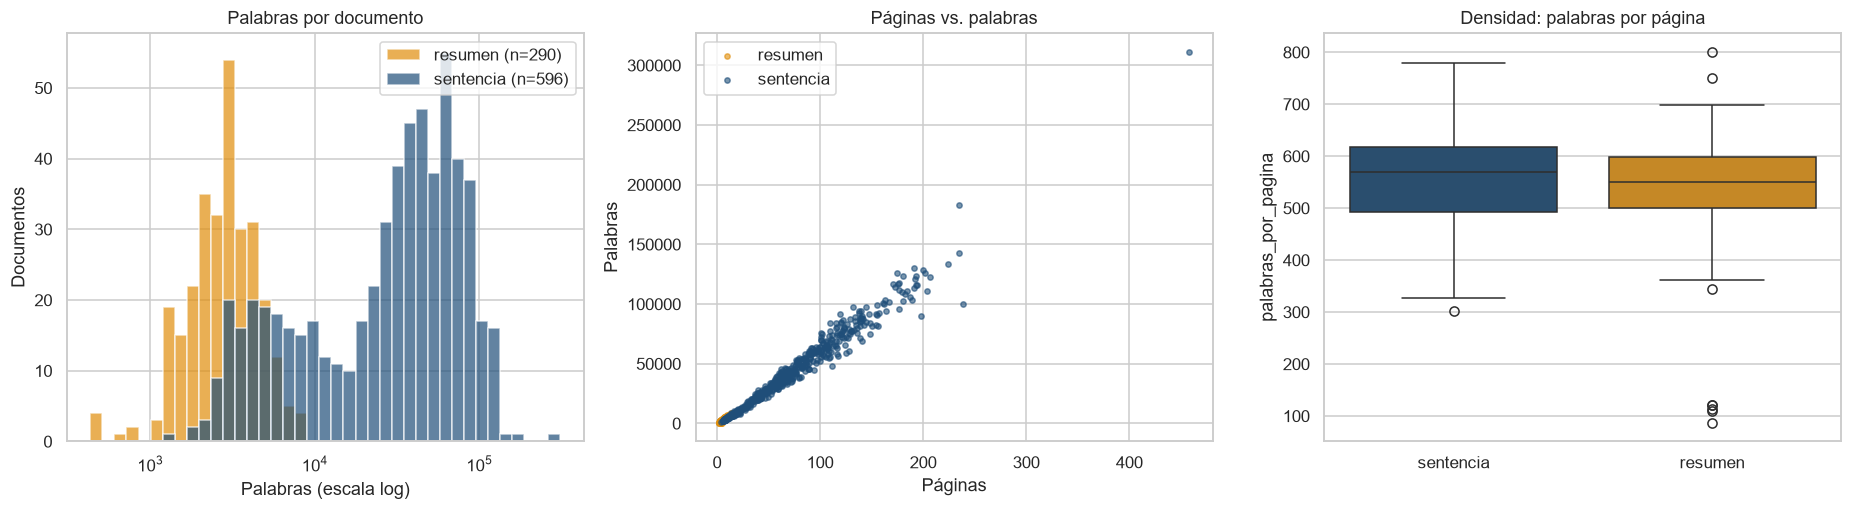

In [22]:
colores = {"sentencia": "#1f4e79", "resumen": "#e08e0b"}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

bins = np.logspace(np.log10(max(df_desc["num_palabras"].min(), 1)), np.log10(df_desc["num_palabras"].max()), 40)
for t, g in df_desc.groupby("tipo_documento"):
    ax[0].hist(g["num_palabras"], bins=bins, alpha=0.7, label=f"{t} (n={len(g)})", color=colores.get(t, "gray"))
ax[0].set_xscale("log"); ax[0].set_xlabel("Palabras (escala log)"); ax[0].set_ylabel("Documentos")
ax[0].set_title("Palabras por documento"); ax[0].legend()

for t, g in df_desc.groupby("tipo_documento"):
    ax[1].scatter(g["num_paginas"], g["num_palabras"], s=12, alpha=0.6, label=t, color=colores.get(t, "gray"))
ax[1].set_xlabel("Páginas"); ax[1].set_ylabel("Palabras"); ax[1].legend()
ax[1].set_title("Páginas vs. palabras")

sns.boxplot(data=df_desc, x="tipo_documento", y="palabras_por_pagina", hue="tipo_documento",
            palette=colores, ax=ax[2], legend=False)
ax[2].set_xlabel(""); ax[2].set_title("Densidad: palabras por página")

guardar_fig("fig01_tamano_documentos")

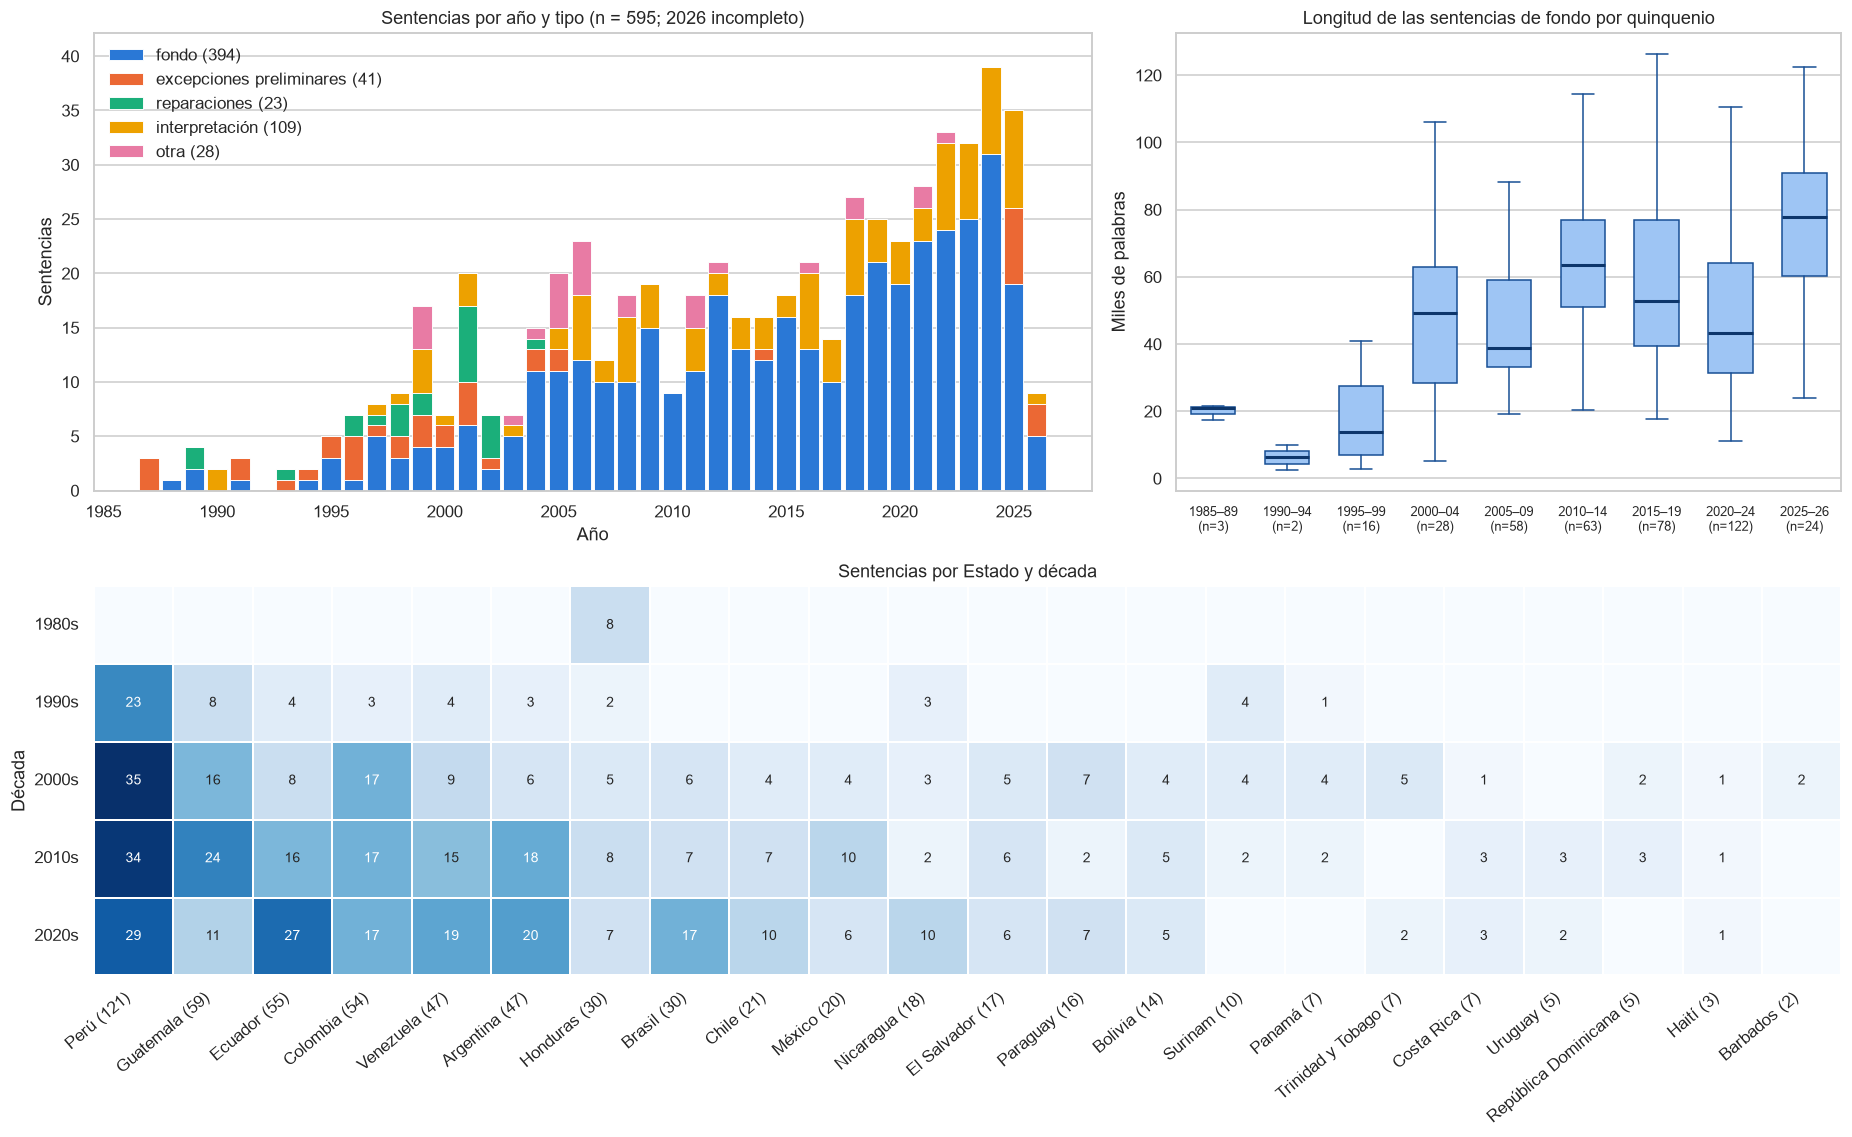

Los 5 Estados con más sentencias reúnen el 56 %: Perú 20 %, Guatemala 10 %, Ecuador 9 %, Colombia 9 %, Argentina 8 %
Mediana de palabras de las sentencias de fondo por década:
decada
1980s    20900
1990s    13100
2000s    42100
2010s    59300
2020s    46900


In [23]:
# ── Sentencias en el tiempo y por Estado ──
# Los tipos poco frecuentes (competencia, sin tipo) se agrupan en «otra» para no pasar de cinco colores.
TIPOS = {"fondo": "#2a78d6", "excepciones preliminares": "#eb6834", "reparaciones": "#1baf7a",
         "interpretación": "#eda100", "otra": "#e87ba4"}
sent = df[df["en_alcance_rag"] & df["anio"].notna()].copy()
sent["anio"] = sent["anio"].astype(int)
sent["tipo"] = sent["tipo_sentencia"].where(sent["tipo_sentencia"].isin(list(TIPOS)), "otra")
sent["quinquenio"] = sent["anio"] // 5 * 5
sent["decada"] = (sent["anio"] // 10 * 10).astype(str) + "s"
anio_max = sent["anio"].max()          # el último año está incompleto
nombre_q = lambda q: f"{q}–{str(min(q + 4, anio_max))[2:]}"

fig = plt.figure(figsize=(17, 10.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.85], width_ratios=[1.5, 1])
ax_anio, ax_long, ax_mapa = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])

# a) Sentencias por año, apiladas por tipo
conteo = sent.groupby(["anio", "tipo"]).size().unstack(fill_value=0).reindex(columns=list(TIPOS), fill_value=0)
base = np.zeros(len(conteo))
for tipo, color in TIPOS.items():
    ax_anio.bar(conteo.index, conteo[tipo], bottom=base, width=0.85, color=color, edgecolor="white",
                linewidth=0.6, label=f"{tipo} ({conteo[tipo].sum()})")
    base += conteo[tipo].to_numpy()
ax_anio.set_title(f"Sentencias por año y tipo (n = {len(sent)}; {anio_max} incompleto)")
ax_anio.set_xlabel("Año"); ax_anio.set_ylabel("Sentencias"); ax_anio.set_ylim(0, base.max() * 1.08)
ax_anio.legend(frameon=False, loc="upper left"); ax_anio.grid(False, axis="x")

# b) Longitud de las sentencias de fondo por quinquenio (sin atípicos; n bajo cada caja)
fondo = sent[sent["tipo"].eq("fondo")]
quinq = sorted(fondo["quinquenio"].unique())
cajas = [fondo.loc[fondo["quinquenio"].eq(q), "numero_palabras"] / 1000 for q in quinq]
ax_long.boxplot(cajas, showfliers=False, patch_artist=True, widths=0.6,
                boxprops={"facecolor": "#9ec5f4", "edgecolor": "#184f95"}, medianprops={"color": "#0d366b", "lw": 2},
                whiskerprops={"color": "#184f95"}, capprops={"color": "#184f95"})
ax_long.set_xticks(range(1, len(quinq) + 1), [f"{nombre_q(q)}\n(n={len(c)})" for q, c in zip(quinq, cajas)],
                   fontsize=8.5)
ax_long.set_ylabel("Miles de palabras"); ax_long.set_title("Longitud de las sentencias de fondo por quinquenio")
ax_long.grid(False, axis="x")

# c) Estado × década
mapa = sent.dropna(subset=["estado"]).pivot_table(index="decada", columns="estado", values="doc_id",
                                                  aggfunc="count", fill_value=0)
mapa = mapa[mapa.sum().sort_values(ascending=False).index]
sns.heatmap(mapa, annot=mapa.astype(str).replace("0", ""), fmt="", cmap="Blues", cbar=False, ax=ax_mapa,
            linewidths=1, linecolor="white", annot_kws={"fontsize": 9})
ax_mapa.set_xticklabels([f"{e.title().replace(' Y ', ' y ')} ({n})" for e, n in mapa.sum().items()], rotation=40, ha="right")
ax_mapa.set_xlabel(""); ax_mapa.set_ylabel("Década"); ax_mapa.tick_params(axis="y", rotation=0)
ax_mapa.set_title("Sentencias por Estado y década")
guardar_fig("fig02_sentencias_tiempo_y_estado")

por_estado = sent["estado"].value_counts(normalize=True)
print(f"Los 5 Estados con más sentencias reúnen el {100 * por_estado.head(5).sum():.0f} %: "
      + ", ".join(f"{e.title()} {100 * p:.0f} %" for e, p in por_estado.head(5).items()))
print("Mediana de palabras de las sentencias de fondo por década:")
print(fondo.groupby("decada")["numero_palabras"].median().round(-2).astype(int).to_string())

**Sentencias en el tiempo y por Estado.** El volumen crece con los años: desde 2018 la Corte dicta más de 20 sentencias por año, y dos de cada tres son de fondo. Cinco Estados reúnen más de la mitad de las sentencias, y Perú solo una de cada cinco. Las sentencias de fondo son cada vez más largas: la mediana pasa de unas 13 mil palabras en los años noventa a unas 59 mil en la década de 2010.

terminos mas frecuentes

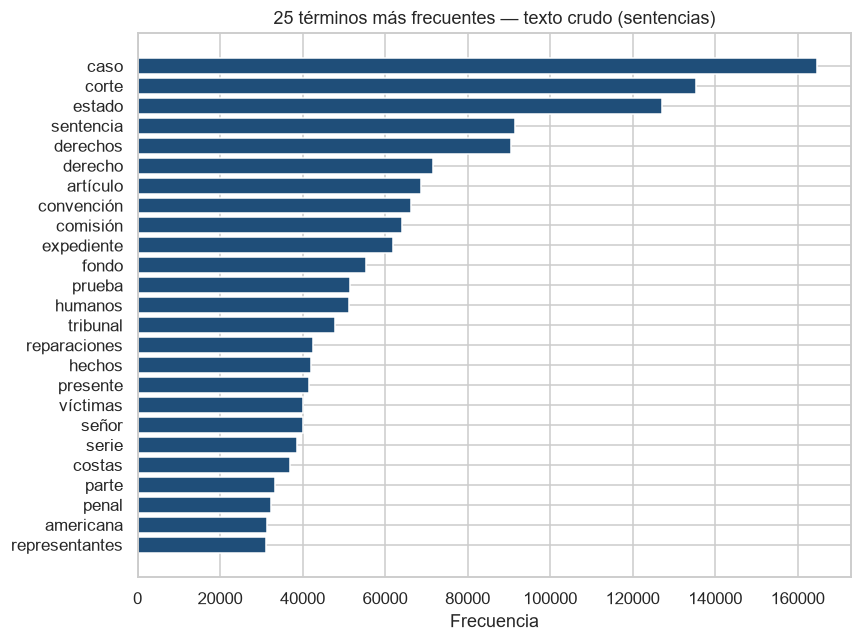

In [24]:
# ── Léxico exploratorio sobre el texto CRUDO (stopwords generales, sin lematizar) ──
# Sirve para ver qué domina el texto antes de preprocesar.
NEGACIONES = {"no", "sin", "ni", "nunca", "tampoco", "contra"}
# spaCy trae "estado" y "parte" como stopwords; en este dominio son términos clave
# (el Estado demandado, las partes del proceso) y NO deben eliminarse.
CONSERVAR = NEGACIONES | {"estado", "parte", "final"}
STOP_BASE = {w for w in STOP_ES if w not in CONSERVAR}
STOP_CITA = {"cfr", "cf", "supra", "infra", "ibíd", "ibid", "ibidem", "ibídem", "op", "cit",
             "párr", "parr", "pág", "págs", "pp", "núm", "vid", "véase"}   # aparato de citas, no contenido

def terminos_utiles(tokens, stop):
    return [t for t in tokens if len(t) > 2 and t not in stop]

df["tokens_crudos"] = df["texto_original"].apply(tokens_simples)
sent_ids = df["en_alcance_rag"]

freq_crudo = Counter()
for toks in df.loc[sent_ids, "tokens_crudos"]:
    freq_crudo.update(terminos_utiles(toks, STOP_BASE | STOP_CITA))

top = pd.DataFrame(freq_crudo.most_common(25), columns=["termino", "frecuencia"])
plt.figure(figsize=(8, 6))
plt.barh(top["termino"][::-1], top["frecuencia"][::-1], color="#1f4e79")
plt.title("25 términos más frecuentes — texto crudo (sentencias)")
plt.xlabel("Frecuencia")
guardar_fig("fig03_top_terminos_crudo")

Bigramas frecuentes: revelan expresiones jurídicas compuestas (p. ej. "derechos humanos")

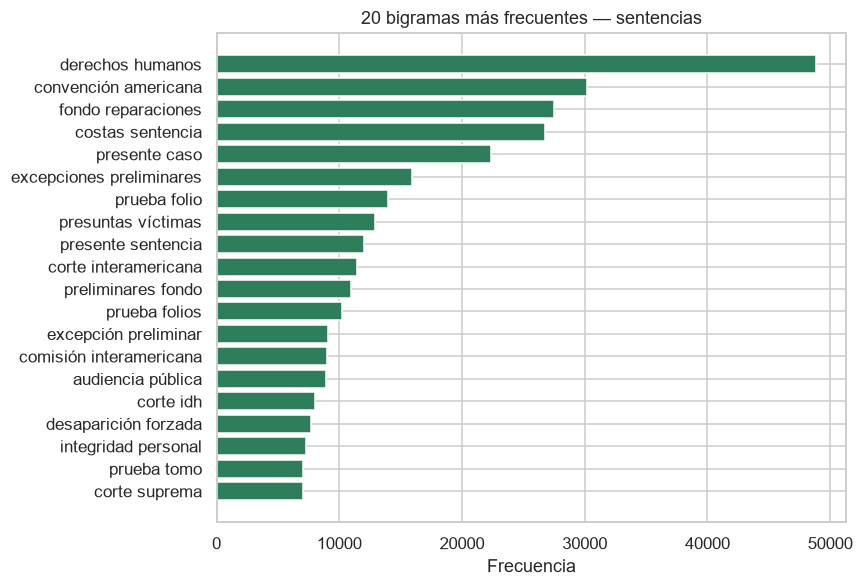

In [25]:
# Bigramas frecuentes: revelan expresiones jurídicas compuestas (p. ej. "derechos humanos")
stop_bi = STOP_BASE | STOP_CITA
bigramas = Counter()
for toks in df.loc[sent_ids, "tokens_crudos"]:
    for a, b in zip(toks, toks[1:]):
        if len(a) > 2 and len(b) > 2 and a not in stop_bi and b not in stop_bi:
            bigramas[(a, b)] += 1

top_bi = pd.DataFrame([(" ".join(k), v) for k, v in bigramas.most_common(20)],
                      columns=["bigrama", "frecuencia"])
plt.figure(figsize=(8, 5.5))
plt.barh(top_bi["bigrama"][::-1], top_bi["frecuencia"][::-1], color="#2e7d5b")
plt.title("20 bigramas más frecuentes — sentencias"); plt.xlabel("Frecuencia")
guardar_fig("fig05_bigramas")

**Leyes de Zipf y de Heaps.** Zipf: la frecuencia de una palabra es aproximadamente inversamente proporcional a su rango, f(r) ∝ r^−α con α cercano a 1, que en escala log-log es una recta. Heaps: el vocabulario crece de forma sublineal con el texto leído, V(n) = K·n^β con β < 1. Si el texto extraído cumple las dos, se comporta como lenguaje natural y no como ruido de extracción.

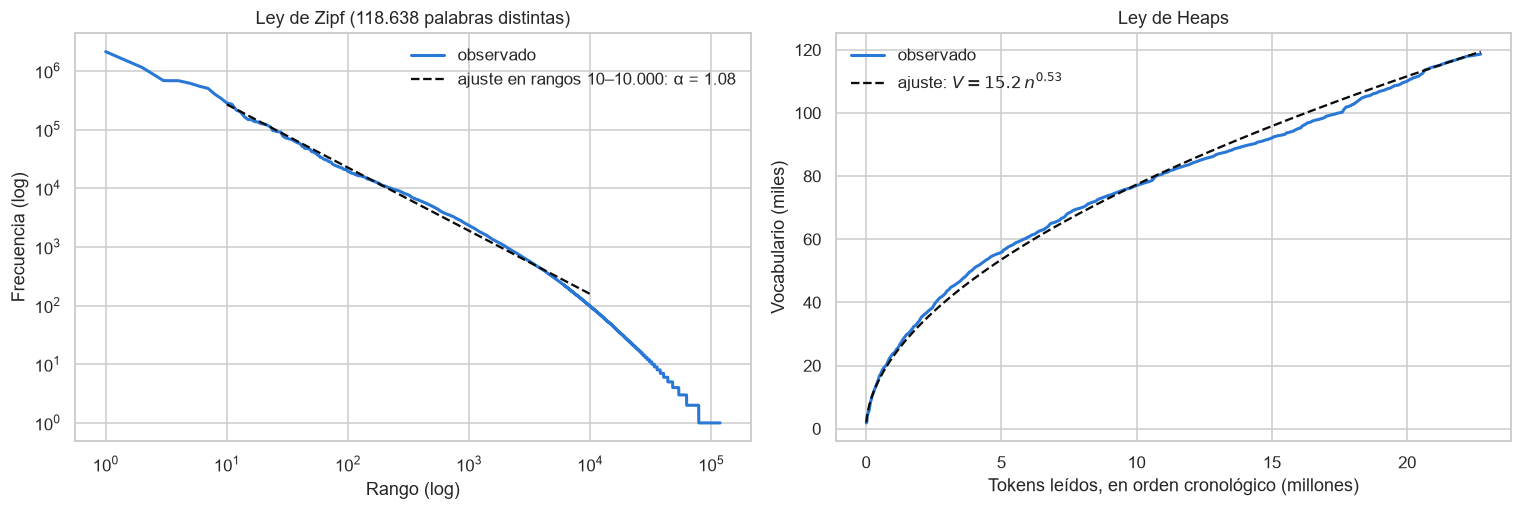

Zipf: α = 1.08  |  Heaps: K = 15.2, β = 0.53  |  22.7 millones de tokens, 118638 palabras distintas


In [26]:
# Leyes de Zipf y de Heaps sobre el texto crudo de las sentencias
freq_all = Counter()
for toks in df.loc[sent_ids, "tokens_crudos"]:
    freq_all.update(toks)
f = np.array(sorted(freq_all.values(), reverse=True), dtype=float)
rango = np.arange(1, len(f) + 1)

# Zipf, f(r) ∝ r^-α: se ajusta entre los rangos 10 y 10.000, fuera de las palabras funcionales y de la cola de hápax
# (puntos espaciados en escala log, para que cada década de rangos pese lo mismo en el ajuste)
tramo = np.unique(np.logspace(1, 4, 60).astype(int)) - 1
pend_z, inter_z = np.polyfit(np.log10(rango[tramo]), np.log10(f[tramo]), 1)

# Heaps, V(n) = K·n^β: vocabulario acumulado leyendo las sentencias en orden cronológico
vistos, n_tokens, curva = set(), 0, []
for toks in df[sent_ids].sort_values("anio")["tokens_crudos"]:
    vistos.update(toks)
    n_tokens += len(toks)
    curva.append((n_tokens, len(vistos)))
curva = np.array(curva, dtype=float)
beta, log_k = np.polyfit(np.log10(curva[:, 0]), np.log10(curva[:, 1]), 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].loglog(rango, f, color="#2a78d6", lw=2, label="observado")
ax[0].loglog(rango[tramo], 10 ** inter_z * rango[tramo] ** pend_z, "--", color="#0b0b0b", lw=1.5,
             label=f"ajuste en rangos 10–10.000: α = {-pend_z:.2f}")
ax[0].set_xlabel("Rango (log)"); ax[0].set_ylabel("Frecuencia (log)")
ax[0].set_title(f"Ley de Zipf ({len(f):,} palabras distintas)".replace(",", "."))
ax[0].legend(frameon=False)

ax[1].plot(curva[:, 0] / 1e6, curva[:, 1] / 1e3, color="#2a78d6", lw=2, label="observado")
ax[1].plot(curva[:, 0] / 1e6, 10 ** log_k * curva[:, 0] ** beta / 1e3, "--", color="#0b0b0b", lw=1.5,
           label=rf"ajuste: $V = {10 ** log_k:.1f}\,n^{{{beta:.2f}}}$")
ax[1].set_xlabel("Tokens leídos, en orden cronológico (millones)"); ax[1].set_ylabel("Vocabulario (miles)")
ax[1].set_title("Ley de Heaps"); ax[1].legend(frameon=False)
guardar_fig("fig06_zipf_y_heaps")
print(f"Zipf: α = {-pend_z:.2f}  |  Heaps: K = {10 ** log_k:.1f}, β = {beta:.2f}  |  "
      f"{n_tokens / 1e6:.1f} millones de tokens, {len(vistos)} palabras distintas")

Ambas leyes se cumplen. La pendiente de Zipf en el tramo central es cercana a 1, y la curva se dobla en la cola, donde están los hápax (nombres propios, cifras escritas y errores de extracción). El vocabulario sigue creciendo con cada sentencia nueva (β ≈ 0,5): siempre aparecen nombres de víctimas, lugares e instituciones. Por eso un índice léxico necesita una normalización consistente entre las consultas y los chunks.

**Pipeline secuencial**
***

In [27]:
# @title
CONFIG = {
    "umbral_lineas_repetidas": 0.40,   # fracción de páginas en que debe repetirse una línea
    "ventana_numeracion": 5,           # tolerancia a saltos en la numeración de párrafos
    "modelo_spacy": "es_core_news_sm",
    "min_len_token": 3,
    "parrafo_min_palabras": 5,         # por debajo se marca como párrafo corto
    "max_palabras_no_numerado": 200,   # bloques sin numeración (p. ej. el resumen) se parten por oraciones
}

LIGADURAS = {"\ufb00": "ff", "\ufb01": "fi", "\ufb02": "fl", "\ufb03": "ffi", "\ufb04": "ffl"}

# ── NUEVO: títulos de sección y marcadores de nota al pie ──
RE_TITULO = re.compile(r"^[IVX]{1,6}(?:-\d{1,2})?\.\s+(?!.*\.{4,})[A-ZÁÉÍÓÚÑÜ][A-ZÁÉÍÓÚÑÜ0-9 ,;:()/.\-–\"']{3,}$")
RE_ROMANO_SOLO      = re.compile(r"[IVX]{1,6}(?:-\d{1,2})?\.?")
RE_MARCA_PEGADA     = re.compile(r"\b([^\W\d_]{3,})\d{1,4}\b")                  # misma1, Juristas2, palabra1034
RE_MARCA_TRAS_PUNTO = re.compile(r"(?<=[^\W\d_][.,;:)])\d{1,4}(?=[\s,;:]|$)")   # Corte.15  EXPRESIÓN)77,  (no "A.1.")
# Las sentencias más largas superan los 999 párrafos
RE_NUM_PARR = re.compile(r"^(\d{1,4})\.\s+(?=\S)")
RE_NUM_SOLO = re.compile(r"^(\d{1,4})\.$")
# Entrada del índice: "XI. PUNTOS RESOLUTIVOS ........ 85", "1. Admisión de la prueba ..... 8"
RE_INDICE = re.compile(r"\.{4,}|…{2,}")
# Puntos resolutivos y votos individuales: reinician la numeración en 1 y no deben pegarse al último párrafo
RE_RESOLUTIVOS = re.compile(r"(?:[IVX]{1,6}(?:-\d{1,2})?\.?\s+)?PUNTOS RESOLUTIVOS[.:]?")
# Sentencias antiguas: sin título, la parte dispositiva abre con "LA CORTE," / "DECIDE:" / "POR TANTO:" en una línea sola
RE_DISPOSITIVA = re.compile(r"(?:POR TANTO[,:]?\s+)?LA\s+CORTE(?:\s+INTERAMERICANA DE DERECHOS HUMANOS)?,?"
                            r"(?:\s+(?:DECIDE|RESUELVE|DECLARA)[:,]?)?|(?:DECIDE|RESUELVE|DECLARA)[:,]?|POR TANTO[,:]|OPERATIVE PARAGRAPHS")
# Bloque de firmas al final de la sentencia: nombres de jueces, no contenido
# algunas no traen "Redactada en": la firma empieza con la referencia "Corte IDH. Caso ... Sentencia de ..."
RE_FIRMAS = re.compile(r"^(?:(?:Redactada|Hecha|Dada) en (?:español|castellano|inglés|portugués|francés)\b|Corte IDH\. Caso\b)")
RE_VOTO = re.compile(r"^VOTO\s+(?:PARCIALMENTE\s+)?(?:CONCURRENTE|RAZONADO|DISIDENTE|CONJUNTO|INDIVIDUAL|SEPARADO|SALVADO)\b")

def nueva_parte(linea, parte):
    if RE_VOTO.match(linea) and linea.isupper():
        return "voto"
    if parte == "cuerpo" and linea.isupper() and (RE_RESOLUTIVOS.match(linea) or RE_DISPOSITIVA.fullmatch(linea)):
        return "resolutivos"
    if parte == "resolutivos" and RE_FIRMAS.match(linea):           # en el cuerpo y los votos esas líneas pueden ser citas
        return "firmas"
    return None


def marcar_portada(df_parr):
    """Portada e índice: todo lo anterior al párrafo 1 del cuerpo (el índice también trae títulos de sección)."""
    p1 = df_parr[df_parr["parte"].eq("cuerpo") & df_parr["num_parrafo"].eq(1).fillna(False)].groupby("doc_id")["orden"].min()
    inicio = df_parr["doc_id"].map(p1)
    sin_p1 = inicio.isna() & df_parr["seccion"].eq("ENCABEZADO")      # sin numeración detectada: criterio anterior
    return df_parr["doc_id"].str.endswith("_sentencia") & (df_parr["orden"].lt(inicio) | sin_p1)

# ──────────────────────────── Etapa 1 ────────────────────────────
def normalizar_unicode(t):
    t = unicodedata.normalize("NFC", t)

    for k, v in LIGADURAS.items():
        t = t.replace(k, v)

    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = re.sub(r"[\u00ad\u200b\u200c\u200d\ufeff]", "", t)          # guion blando, espacios de ancho cero
    t = t.replace("\xa0", " ")
    t = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", " ", t)          # caracteres de control
    t = re.sub(r"[“”«»„]", '"', t)
    t = re.sub(r"[‘’]", "'", t)

    return t

# NUEVO: quita los números de nota al pie pegados a una palabra o a la puntuación
def quitar_marcas_nota(t):
    t, n1 = RE_MARCA_PEGADA.subn(r"\1", t)
    t, n2 = RE_MARCA_TRAS_PUNTO.subn("", t)
    return t, n1 + n2

# NUEVO: "I." + "INTRODUCCIÓN DE LA CAUSA..." (en líneas separadas) -> "I. INTRODUCCIÓN DE LA CAUSA..."
def _es_linea_titulo(l):
    return l.isupper() and not l.startswith("CASO ")

def unir_titulos(t):
    lineas, unidas, i, n = t.split("\n"), [], 0, 0
    while i < len(lineas):
        l = lineas[i]
        if RE_ROMANO_SOLO.fullmatch(l) and i + 1 < len(lineas) and _es_linea_titulo(lineas[i + 1]):
            j, titulo = i + 1, []
            while j < len(lineas) and _es_linea_titulo(lineas[j]) and len(titulo) < 3:
                titulo.append(lineas[j]); j += 1
            unidas.append(l.rstrip(".") + ". " + " ".join(titulo)); n += 1
            i = j
        else:
            unidas.append(l); i += 1
    return "\n".join(unidas), n

# Parte un bloque largo sin numeración en trozos de <= max_pal palabras
def dividir_bloque_largo(p, max_pal):

    if len(p.split()) <= max_pal:
        return [p]

    trozos, actual, n = [], [], 0

    for oracion in re.split(r"(?<=[.!?])\s+", p):
        k = len(oracion.split())
        if actual and n + k > max_pal:
            trozos.append(" ".join(actual)); actual, n = [], 0
        actual.append(oracion); n += k

    if actual:
        trozos.append(" ".join(actual))

    return trozos

# ──────────────────────────── Etapas 2-4 ────────────────────────────
def limpiar_texto(texto, n_paginas, cfg=CONFIG):
    stats = Counter()
    t = normalizar_unicode(texto)

    # NUEVO: marcadores de nota al pie pegados a palabras
    t, n = quitar_marcas_nota(t)
    stats["marcas_nota_quitadas"] = n

    # Etapa 2: encabezados / pie de pagina/ numeros de pagina
    repetidas = detectar_lineas_repetidas(t, n_paginas, cfg["umbral_lineas_repetidas"])
    lineas = []

    for l in t.split("\n"):
        l = l.strip()
        if not l:
            continue

        if l in repetidas:
            stats["lineas_encabezado_pie"] += 1; continue

        if RE_PAGINA.match(l):
            stats["lineas_num_pagina"] += 1; continue

        lineas.append(l)

    t = "\n".join(lineas)

    # Etapa 3: palabras cortadas por guion al final de línea
    t, n = RE_GUION_CORTE.subn("", t)
    stats["palabras_unidas_guion"] = n

    # NUEVO, Etapa 3b: unir numeral romano suelto con su título
    t, n = unir_titulos(t)
    stats["titulos_unidos"] = n

    # Etapa 4: reconstrucción de párrafos, separando cuerpo, puntos resolutivos y votos
    parrafos, actual = [], []
    parte = parte_parr = "cuerpo"           # parte del documento y del párrafo abierto
    ultimo, ultimo_cuerpo = 0, 0

    def cerrar():
        if actual:
            parrafos.append((parte_parr, False, " ".join(actual))); actual.clear()

    for l in t.split("\n"):
        # solo después del primer párrafo numerado: el índice de la portada también lista "PUNTOS RESOLUTIVOS"
        indice = bool(RE_INDICE.search(l))       # el índice no abre partes ni cuenta como párrafo numerado
        if parte == "resolutivos" and ultimo == 0 and re.match(r"I\.\s", l) and RE_TITULO.match(l):
            parte = parte_parr = "cuerpo"; ultimo = ultimo_cuerpo = 0   # era el índice: el cuerpo empieza en "I."
            stats["inicio_resolutivos"] -= 1
        nueva = nueva_parte(l, parte) if (ultimo or parte != "cuerpo") and not indice else None
        if nueva:
            cerrar()
            if parte == "cuerpo":
                ultimo_cuerpo = ultimo
            parte = parte_parr = nueva; ultimo = 0          # resolutivos y votos reinician la numeración
            stats[f"inicio_{parte}"] += 1

        if nueva in ("resolutivos", "voto") or RE_TITULO.match(l):     # la línea de firmas es texto, no título
            cerrar(); parrafos.append((parte, True, l))
            if nueva != "voto":
                stats["titulos"] += 1
            continue

        m = None if indice else (RE_NUM_PARR.match(l) or RE_NUM_SOLO.match(l))

        if m:
            n_p, w = int(m.group(1)), cfg["ventana_numeracion"]
            if ultimo < n_p <= ultimo + w:                    # la numeración debe ser consecutiva
                cerrar(); ultimo = n_p; parte_parr = parte; stats["parrafos_numerados"] += 1
            elif parte == "resolutivos" and ultimo == 0 and ultimo_cuerpo < n_p <= ultimo_cuerpo + w:
                # "189. Por tanto," continúa la numeración del cuerpo antes del punto resolutivo 1
                cerrar(); ultimo_cuerpo = n_p; parte_parr = "cuerpo"; stats["parrafos_numerados"] += 1

        actual.append(l)
    cerrar()

    finales = []
    for pa, es_titulo, p in parrafos:
        p = re.sub(r"\s+", " ", p).strip()
        if es_titulo or RE_NUM_PARR.match(p):
            finales.append((pa, es_titulo, p))          # títulos y párrafos numerados se respetan tal cual
        else:
            finales.extend((pa, False, x) for x in dividir_bloque_largo(p, cfg["max_palabras_no_numerado"]))

    texto_limpio = "\n\n".join(p for _, _, p in finales)
    stats["parrafos_totales"] = len(finales)

    return texto_limpio, dict(stats), finales

# ──────────────────────────── Etapa 5 ────────────────────────────
def segmentar_parrafos(doc_id, bloques, cfg=CONFIG):
    filas, seccion, orden = [], "ENCABEZADO", 0

    for parte, es_titulo, p in bloques:
        if es_titulo:
            seccion = p; continue

        m = RE_NUM_PARR.match(p)
        num = int(m.group(1)) if m else None
        cuerpo = RE_NUM_PARR.sub("", p, count=1) if m else p
        orden += 1
        nw = len(cuerpo.split())

        filas.append({"doc_id": doc_id, "orden": orden, "parte": parte, "seccion": seccion, "num_parrafo": num,
                      "texto": cuerpo, "num_palabras": nw, "es_corto": nw < cfg["parrafo_min_palabras"]})
    return filas

In [28]:
# Aplicacion de las etapas 1-5 al corpus
limpios, stats_lista, parr_filas = [], [], []

for r in tqdm(df.itertuples(), total=len(df), desc="Limpieza"):
    txt, st, bloques = limpiar_texto(r.texto_cuerpo, r.numero_paginas)
    limpios.append(txt)
    stats_lista.append({"doc_id": r.doc_id, **st})
    parr_filas.extend(segmentar_parrafos(r.doc_id, bloques))

df["texto_limpio"] = limpios
df_stats = pd.DataFrame(stats_lista).fillna(0).set_index("doc_id").astype(int)
df_parr = pd.DataFrame(parr_filas)
df_parr["num_parrafo"] = df_parr["num_parrafo"].astype("Int64")

# NUEVO: portada + índice de las sentencias (los resúmenes no tienen secciones, no se marcan)
df_parr["es_portada"] = marcar_portada(df_parr)

print(f"Párrafos generados: {len(df_parr):,}")
display(df_stats)

Párrafos generados: 146,627


,marcas_nota_quitadas,lineas_num_pagina,palabras_unidas_guion,titulos_unidos,titulos,parrafos_numerados,inicio_resolutivos,inicio_firmas,parrafos_totales,inicio_voto,lineas_encabezado_pie
doc_id,,,,,,,,,,,
1025868111_sentencia,2,36,0,5,5,160,1,1,169,0,0
1031550500_sentencia,0,17,0,5,5,60,1,1,69,0,0
1034838366_sentencia,0,1,0,12,12,209,1,1,232,0,0
1034838366_resumen,0,7,0,0,0,0,0,0,21,0,0
1035032346_sentencia,0,21,0,11,11,73,1,1,90,0,0
...,...,...,...,...,...,...,...,...,...,...,...
980571262_resumen,2,7,0,0,0,0,0,0,22,0,0
980571899_sentencia,4,208,5,13,18,676,1,1,715,2,0
980571899_resumen,0,6,0,0,0,0,0,0,25,0,0


In [29]:
val = []
# solo el cuerpo: puntos resolutivos y votos tienen su propia numeración
for doc_id, g in df_parr[df_parr["parte"].eq("cuerpo")].groupby("doc_id"):
    nums = g["num_parrafo"].dropna().astype(int)
    if nums.empty:
        val.append({"doc_id": doc_id, "numerados": 0, "max_num": None, "faltantes": None, "cobertura_%": None})
        continue
    esperados = set(range(1, nums.max() + 1))
    faltan = sorted(esperados - set(nums))
    val.append({"doc_id": doc_id, "numerados": len(nums), "max_num": int(nums.max()),
                "faltantes": len(faltan), "cobertura_%": round(100 * (1 - len(faltan) / nums.max()), 1),
                "primeros_faltantes": faltan[:8]})
display(pd.DataFrame(val))
print("Nota: el resumen no tiene párrafos numerados; es esperado que salga vacío.")

,doc_id,numerados,max_num,faltantes,cobertura_%,primeros_faltantes
0,1025868111_sentencia,150,150.0,0.0,100.0,[]
1,1031550500_sentencia,56,56.0,0.0,100.0,[]
2,1034838366_resumen,0,NaN,NaN,NaN,NaN
3,1034838366_sentencia,188,188.0,0.0,100.0,[]
4,1035032346_resumen,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
881,980571262_sentencia,247,247.0,0.0,100.0,[]
882,980571899_resumen,0,NaN,NaN,NaN,NaN
883,980571899_sentencia,393,393.0,0.0,100.0,[]
884,980572019_resumen,0,NaN,NaN,NaN,NaN


Nota: el resumen no tiene párrafos numerados; es esperado que salga vacío.


In [30]:
# Ejemplo antes → después sobre un fragmento real
r = df[df["doc_id"] == doc_ref["doc_id"]].iloc[0]
# un párrafo real del cuerpo (fuera de portada e índice) y su ubicación en el texto crudo
p_ej = df_parr[(df_parr["doc_id"] == r["doc_id"]) & ~df_parr["es_portada"] & df_parr["parte"].eq("cuerpo")
               & df_parr["num_palabras"].between(40, 120)].iloc[0]
m = re.search(r"\s+".join(map(re.escape, p_ej["texto"].split()[:4])), r["texto_original"])
ini = m.start() if m else r["texto_original"].find("\n", 3000)

print(" ────────────────────────────── TEXTO CRUDO (extracción PDF) ──────────────────────────────")
print(r["texto_original"][ini:ini + 700])

print("\n ────────────────────────────── TEXTO LIMPIO (párrafos reconstruidos)  ──────────────────────────────")
print(f"[sección: {p_ej['seccion']} | párrafo nº {p_ej['num_parrafo']}]")
print(p_ej["texto"])

 ────────────────────────────── TEXTO CRUDO (extracción PDF) ──────────────────────────────
Notificación al Estado. - El Informe de Fondo fue notificado al Estado mediante 
comunicación de 8 de octubre de 2019, habiéndosele otorgado el plazo de dos meses para 
que informara sobre el cumplimiento de las recomendaciones formuladas. La Comisión, 
después de otorgar dos prórrogas al Estado, negó el otorgamiento de una nueva prórroga, 
debido a que Colombia “no [había] present[ado] información sustantiva que revelara avances 
relevantes en el cumplimiento de las recomendaciones”. 
 
4. 
Sometimiento a la Corte. - El 8 de julio de 2020 la Comisión sometió a la Corte la 
totalidad de los hechos y violaciones a derechos humanos del caso. Lo hizo, según indicó, “por 
la necesidad de obtenci

 ────────────────────────────── TEXTO LIMPIO (párrafos reconstruidos)  ──────────────────────────────
[sección: I. INTRODUCCIÓN DE LA CAUSA Y OBJETO DE LA CONTROVERSIA | párrafo nº 3]
Notificación al Estado

In [31]:
# ──────────────────────────── Etapas 6-7: tokenización, lematización y filtrado ────────────────────────────
nlp = spacy.load(CONFIG["modelo_spacy"], disable=["parser", "ner"])   # Lematizador y morfologizador
nlp.max_length = 2_000_000

STOPWORDS = STOP_BASE | STOP_CITA
POS_FUNCION = {"PRON", "DET", "ADP", "CCONJ", "SCONJ", "AUX"}     # pronombres como "él" se colaban como lemas

# "artículo 8.1" -> "art_8_1": los números de artículo son términos clave y el filtro alfabético los borraba
# shortcut: no distingue la Convención del Reglamento u otros tratados; añadir el instrumento si hace falta
RE_ARTICULOS = re.compile(r"\b(?:art[íi]culos?|arts?\.)\s+(\d{1,3}(?:\.\d{1,2})?(?:\s*(?:,|y|e)\s*\d{1,3}(?:\.\d{1,2})?)*)", re.I)
RE_ART_TOKEN = re.compile(r"art_\d{1,3}(?:_\d{1,2})?")

def marcar_articulos(texto):
    return RE_ARTICULOS.sub(lambda m: " ".join("art_" + n.replace(".", "_")
                                               for n in re.findall(r"\d{1,3}(?:\.\d{1,2})?", m.group(1))), texto)

def filtrar_tokens(doc):
    out = []
    for tok in doc:
        txt = tok.text.lower()
        if RE_ART_TOKEN.fullmatch(txt):
            out.append(txt); continue
        if not tok.is_alpha:
            continue

        lem = tok.lemma_.lower()
        if lem in CONSERVAR:                 # negaciones y términos del dominio, aunque sean cortos o stopwords
            out.append(lem); continue

        if tok.pos_ in POS_FUNCION or len(lem) < CONFIG["min_len_token"] or lem in STOPWORDS or txt in STOPWORDS:
            continue
        out.append(lem)
    return out

# Una sola normalización para párrafos, chunks y consultas
def normalizar_lote(textos, desc="Lematización"):
    docs = nlp.pipe((marcar_articulos(t) for t in textos), batch_size=64)
    return [filtrar_tokens(d) for d in tqdm(docs, total=len(textos), desc=desc)]

def normalizar(texto):
    return " ".join(filtrar_tokens(nlp(marcar_articulos(texto))))

# Se procesa por párrafo (unidad corta => rápido y sin problemas de memoria)
lemas = normalizar_lote(df_parr["texto"])

df_parr["lemas"] = lemas
df_parr["texto_normalizado"] = df_parr["lemas"].apply(" ".join)
df_parr["num_lemas"] = df_parr["lemas"].apply(len)

norm_doc = df_parr.groupby("doc_id")["texto_normalizado"].apply(" ".join)
df["texto_normalizado"] = df["doc_id"].map(norm_doc).fillna("")
df_parr[["doc_id", "seccion", "num_parrafo", "num_palabras", "num_lemas", "texto_normalizado"]].head(5)

,doc_id,seccion,num_parrafo,num_palabras,num_lemas,texto_normalizado
0,1025868111_sentencia,ENCABEZADO,<NA>,99,63,corte interamericana derechos humanos caso integrante militante unión patriótico colom...
1,1025868111_sentencia,ENCABEZADO,<NA>,199,85,sijniensky secretaria adjunta conformidad art_67 convención americana derechos humanos...
2,1025868111_sentencia,ENCABEZADO,<NA>,173,54,familiar víctima encontrar listada anexo sentencia argumento parte comisión considerac...
3,1025868111_sentencia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,1,72,26,julio corte interamericana emitir sentencia presente caso sentencia notificar parte co...
4,1025868111_sentencia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,2,57,23,marzo intervinient común derechos dignidad presentar solicitud interpretación relación...


In [32]:
# @title
# Trazabilidad de una misma frase a lo largo del pipeline
frase = p_ej["texto"].split(". ")[0][:400]
doc = nlp(frase)
print("1) LIMPIO      :", frase)
print("\n2) TOKENS      :", [t.text for t in doc][:25], "...")
print("\n3) LEMAS       :", [t.lemma_ for t in doc][:25], "...")
print("\n4) FILTRADO    :", filtrar_tokens(doc))

1) LIMPIO      : Notificación al Estado

2) TOKENS      : ['Notificación', 'al', 'Estado'] ...

3) LEMAS       : ['Notificación', 'al', 'Estado'] ...

4) FILTRADO    : ['notificación', 'estado']


,palabras_original,palabras_limpio,tokens_normalizados,vocab_crudo,vocab_normalizado,reduccion_texto_%,reduccion_tokens_%,reduccion_vocab_%
doc_id,,,,,,,,
1025868111_sentencia,22598,19439,8254,2390,1300,14.0,63.5,45.6
1031550500_sentencia,9544,7272,3143,1409,767,23.8,67.1,45.6
1034838366_sentencia,33208,22589,10357,3381,1901,32.0,68.8,43.8
1034838366_resumen,3745,3705,1782,818,584,1.1,52.4,28.6
1035032346_sentencia,11281,8019,3370,1762,902,28.9,70.1,48.8
1035032346_resumen,725,723,320,271,175,0.3,55.9,35.4
1039244171_sentencia,65252,45435,19707,6084,3338,30.4,69.8,45.1
1039244171_resumen,3313,3206,1399,881,605,3.2,57.8,31.3
1039351190_sentencia,43270,30705,13476,3916,1993,29.0,68.9,49.1


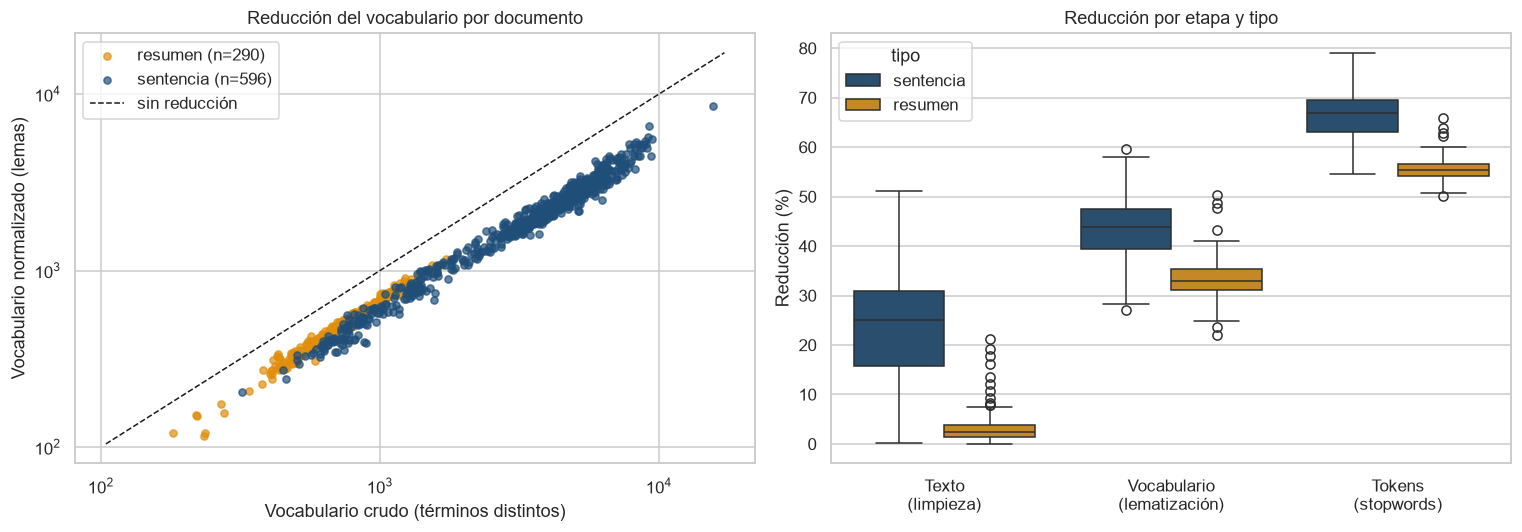

In [33]:
# ── Tabla de comparación antes / después del preprocesamiento ──
comp = []

for r in df.itertuples():
    tok_crudo = r.tokens_crudos
    lem = r.texto_normalizado.split()
    comp.append({
        "doc_id": r.doc_id,
        "palabras_original": r.numero_palabras,
        "palabras_limpio": len(r.texto_limpio.split()),
        "tokens_normalizados": len(lem),
        "vocab_crudo": len(set(tok_crudo)),
        "vocab_normalizado": len(set(lem)),
    })

df_comp = pd.DataFrame(comp).set_index("doc_id")
df_comp["reduccion_texto_%"] = (100 * (1 - df_comp["palabras_limpio"] / df_comp["palabras_original"])).round(1)
df_comp["reduccion_tokens_%"] = (100 * (1 - df_comp["tokens_normalizados"] / df_comp["palabras_original"])).round(1)
df_comp["reduccion_vocab_%"] = (100 * (1 - df_comp["vocab_normalizado"] / df_comp["vocab_crudo"])).round(1)
df_comp["tipo"] = df_comp.index.str.rsplit("_", n=1).str[-1]
display(df_comp.drop(columns="tipo").head(10))

# ── Gráfico ──
colores = {"sentencia": "#1f4e79", "resumen": "#e08e0b"}

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for t, g in df_comp.groupby("tipo"):
    ax[0].scatter(g["vocab_crudo"], g["vocab_normalizado"], s=22, alpha=0.7,
                  color=colores.get(t, "gray"), label=f"{t} (n={len(g)})")
lim = [df_comp["vocab_normalizado"].min() * 0.9, df_comp["vocab_crudo"].max() * 1.1]
ax[0].plot(lim, lim, "k--", lw=1, label="sin reducción")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Vocabulario crudo (términos distintos)")
ax[0].set_ylabel("Vocabulario normalizado (lemas)")
ax[0].set_title("Reducción del vocabulario por documento"); ax[0].legend()

nombres = {"reduccion_texto_%": "Texto\n(limpieza)",
           "reduccion_vocab_%": "Vocabulario\n(lematización)",
           "reduccion_tokens_%": "Tokens\n(stopwords)"}
largo = (df_comp.melt(id_vars="tipo", value_vars=list(nombres), var_name="etapa", value_name="reduccion")
                .assign(etapa=lambda d: d["etapa"].map(nombres)))
sns.boxplot(data=largo, x="etapa", y="reduccion", hue="tipo", palette=colores, ax=ax[1])
ax[1].set_xlabel(""); ax[1].set_ylabel("Reducción (%)"); ax[1].set_title("Reducción por etapa y tipo")

guardar_fig("fig07_vocabulario_antes_despues")

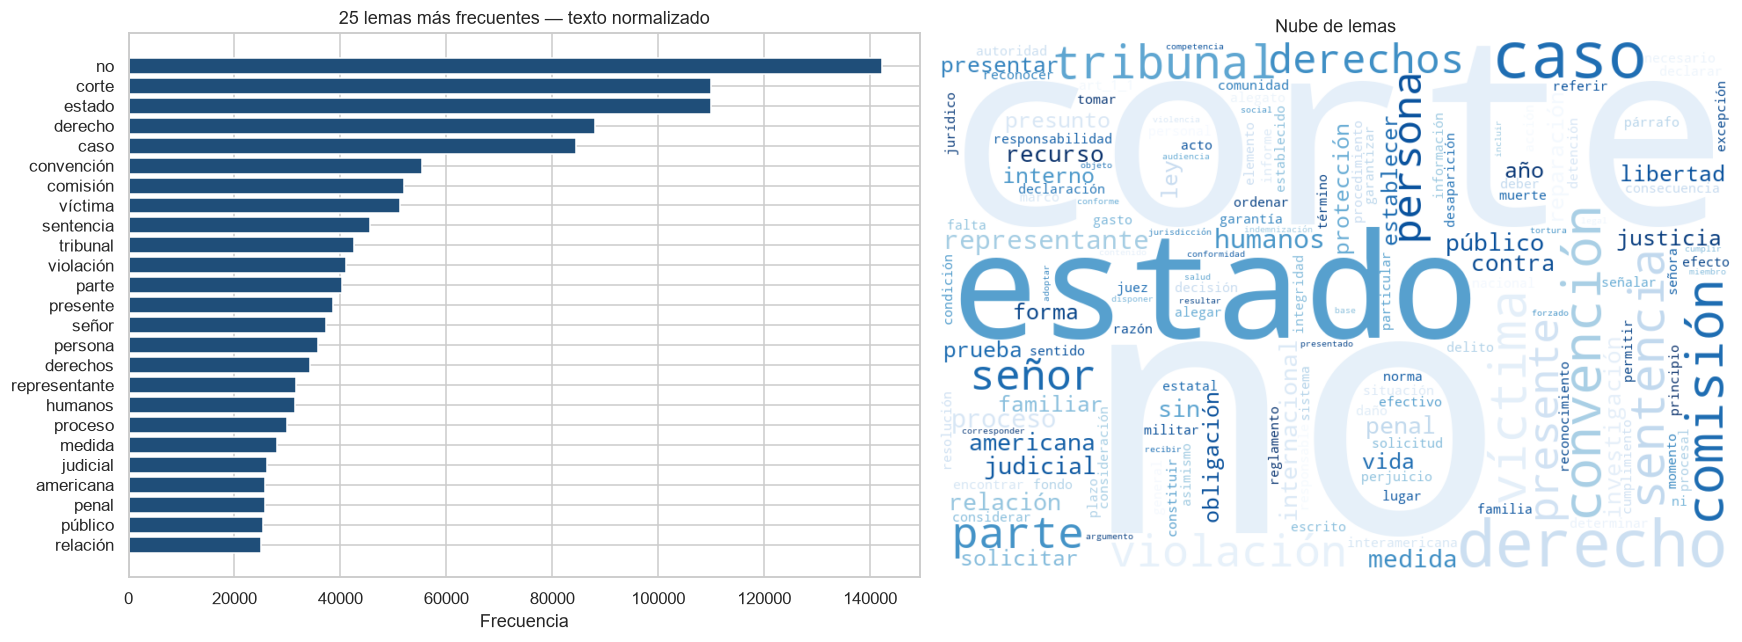

Lemas presentes en todas las sentencias (candidatos a revisar, NO eliminados):
 ['no', 'corte', 'estado', 'caso', 'convención', 'comisión', 'sentencia', 'parte', 'presente', 'derechos', 'humanos', 'americana', 'presentar', 'interamericana', 'reglamento', 'él']


Sentencias sin el lema «corte»: 0 []
Sentencias sin el lema «caso»: 0 []
Sentencias sin el lema «estado»: 0 []
Sentencias sin el lema «convención»: 0 []
Sentencias sin el lema «sentencia»: 0 []


In [34]:
# Términos y nube despues del preprocesamiento (lemas)
freq_lem = Counter()

for lem in df_parr.loc[df_parr["doc_id"].isin(df.loc[sent_ids, "doc_id"]), "lemas"]:
    freq_lem.update(lem)

top_l = pd.DataFrame(freq_lem.most_common(25), columns=["lema", "frecuencia"])
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].barh(top_l["lema"][::-1], top_l["frecuencia"][::-1], color="#1f4e79")
ax[0].set_title("25 lemas más frecuentes — texto normalizado"); ax[0].set_xlabel("Frecuencia")
wc = WordCloud(width=900, height=600, background_color="white", max_words=150,
               colormap="Blues", random_state=42).generate_from_frequencies(freq_lem)
ax[1].imshow(wc, interpolation="bilinear"); ax[1].axis("off"); ax[1].set_title("Nube de lemas")
guardar_fig("fig08_lemas_despues")

# Candidatos a stopwords de dominio: lemas presentes en TODOS los documentos en alcance
df_en_alcance = df[sent_ids]
if len(df_en_alcance) > 1:
    presencia = Counter()
    for t in df_en_alcance["texto_normalizado"]:
        presencia.update(set(t.split()))

    ubicuos = sorted([w for w, c in presencia.items() if c == len(df_en_alcance)],
                     key=lambda w: -freq_lem[w])[:30]

    print("Lemas presentes en todas las sentencias (candidatos a revisar, NO eliminados):\n", ubicuos)

    # Términos que deberían aparecer en todas las sentencias: si faltan, revisar lematización o extracción
    conjuntos = [set(t.split()) for t in df_en_alcance["texto_normalizado"]]
    for w in ("corte", "caso", "estado", "convención", "sentencia"):
        faltan = [d for d, c in zip(df_en_alcance["doc_id"], conjuntos) if w not in c]
        print(f"Sentencias sin el lema «{w}»: {len(faltan)}", faltan[:5])

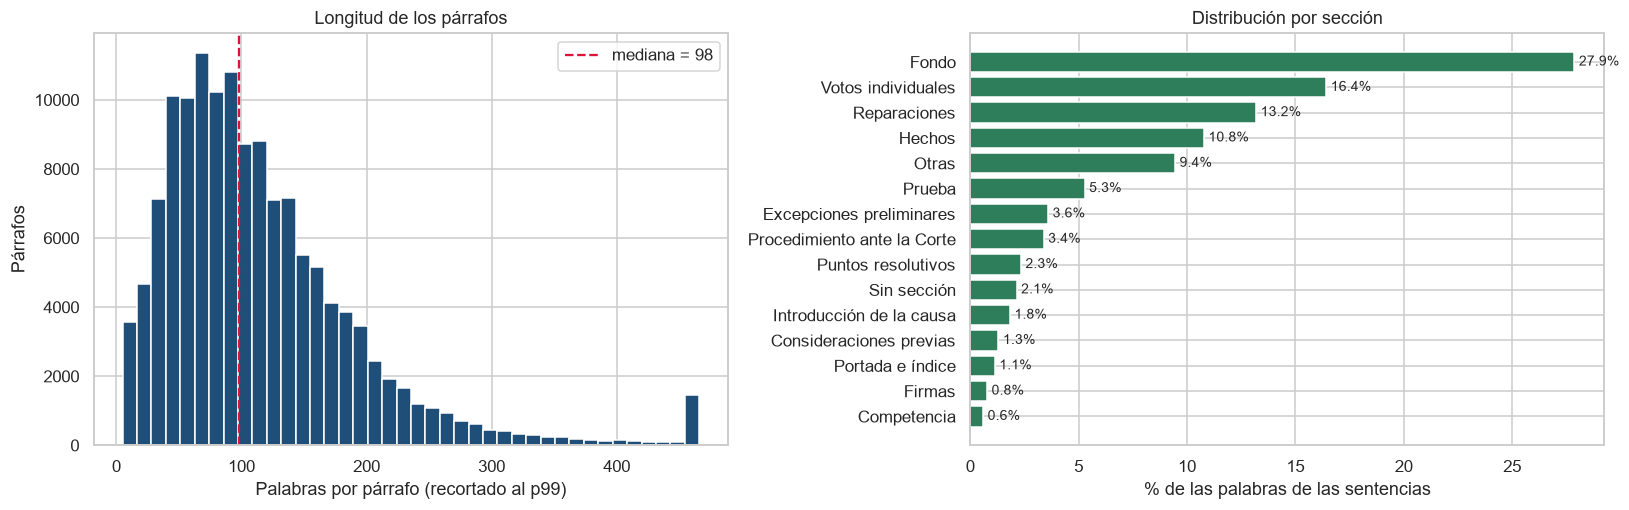

Cuantiles de longitud de párrafo (palabras):


,0.05,0.25,0.50,0.75,0.90,0.95,0.99
palabras,26.0,61.0,98.0,149.0,206.0,256.0,466.0


Párrafos > 300 palabras: 4079 de 136708


In [35]:
# Párrafos de las sentencias (sin los muy cortos), base para el histograma y las secciones
pa = df_parr[df_parr["doc_id"].isin(df.loc[sent_ids, "doc_id"]) & ~df_parr["es_corto"]].copy()

def canon_seccion(s):
    if s == "ENCABEZADO":
        return "Sin sección"      # cuerpo antes del primer título: sentencias antiguas sin títulos
    t = re.sub(r"\s+", " ", re.sub(r"^[IVX]+(?:-\d+)?\.?\s+", "", s)).upper()
    reglas = [("Introducción de la causa", "INTRODUCCI"), ("Procedimiento ante la Corte", "PROCEDIMIENTO"),
              ("Competencia", "COMPETENCIA"), ("Excepciones preliminares", "EXCEPCI"),
              ("Consideraciones previas", "CONSIDERACIONES PREVIAS"), ("Prueba", "PRUEBA"),
              ("Hechos", "HECHOS"), ("Fondo", "FONDO|DERECHO"),
              ("Reparaciones", "REPARACI"), ("Puntos resolutivos", "PUNTOS RESOLUTIVOS")]
    for nombre, patron in reglas:
        if re.search(patron, t):
            return nombre
    return "Otras"

def seccion_canonica(d):
    por_titulo = d["seccion"].map(canon_seccion).where(~d["es_portada"], "Portada e índice")
    return d["parte"].map({"voto": "Votos individuales", "firmas": "Firmas"}).fillna(por_titulo)

pa["sec"] = seccion_canonica(pa)
por_sec = pa.groupby("sec")["num_palabras"].sum().sort_values()
por_sec = 100 * por_sec / por_sec.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].hist(pa["num_palabras"].clip(upper=pa["num_palabras"].quantile(0.99)), bins=40, color="#1f4e79")
ax[0].axvline(pa["num_palabras"].median(), color="crimson", ls="--", label=f"mediana = {pa['num_palabras'].median():.0f}")
ax[0].set_xlabel("Palabras por párrafo (recortado al p99)"); ax[0].set_ylabel("Párrafos")
ax[0].set_title("Longitud de los párrafos"); ax[0].legend()

ax[1].barh(por_sec.index, por_sec.values, color="#2e7d5b")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax[1].set_xlabel("% de las palabras de las sentencias"); ax[1].set_title("Distribución por sección")
guardar_fig("fig09_parrafos_y_secciones")

print("Cuantiles de longitud de párrafo (palabras):")
display(pa["num_palabras"].quantile([.05, .25, .5, .75, .9, .95, .99]).round(0).to_frame("palabras").T)
print("Párrafos > 300 palabras:", int((pa["num_palabras"] > 300).sum()), "de", len(pa))

In [36]:
cols_doc = [c for c in ["doc_id", "vid", "titulo", "estado", "fecha", "anio", "idioma", "tipo_documento",
                        "pdf_path", "numero_paginas", "numero_caracteres", "numero_palabras",
                        "en_alcance_rag", "caso_id", "tipo_sentencia", "texto_limpio", "texto_normalizado", "texto_notas"] if c in df.columns]

# 1) Documentos limpios (una línea por documento)
df[cols_doc].to_parquet(PROC_DIR / "corpus_limpio.parquet", index=False)

# 2) Párrafos (unidad para chunking / embeddings en la Parte 3)
meta_cols = [c for c in ["doc_id", "vid", "caso_id", "titulo", "estado", "tipo_documento", "tipo_sentencia", "anio", "idioma"]
             if c in df.columns]
df_parr_out = df_parr.merge(df[meta_cols].drop_duplicates("doc_id"), on="doc_id", how="left")
df_parr_out["lemas"] = df_parr_out["lemas"].apply(lambda l: " ".join(l))
df_parr_out["seccion_canonica"] = seccion_canonica(df_parr_out)
df_parr_out.to_parquet(PROC_DIR / "parrafos.parquet", index=False)
df_parr_out.to_csv(PROC_DIR / "parrafos.csv", index=False, encoding="utf-8-sig")

# 3) Tablas de soporte para el artículo
df_desc.drop(columns=["etiqueta"]).round(3).to_csv(PROC_DIR / "tabla_descriptiva.csv", index=False, encoding="utf-8-sig")
df_ruido.to_csv(PROC_DIR / "tabla_ruido_extraccion.csv", encoding="utf-8-sig")
df_stats.to_csv(PROC_DIR / "tabla_limpieza_stats.csv", encoding="utf-8-sig")
df_comp.to_csv(PROC_DIR / "tabla_antes_despues.csv", encoding="utf-8-sig")

# 4) Configuración del pipeline (reproducibilidad)
with open(PROC_DIR / "config_preprocesamiento.json", "w", encoding="utf-8") as f:
    json.dump({**CONFIG, "stopwords_conservadas": sorted(CONSERVAR), "stopwords_citas": sorted(STOP_CITA),
               "n_stopwords_base": len(STOP_BASE)}, f, ensure_ascii=False, indent=2)

print("Archivos generados en", PROC_DIR)
for p in sorted(PROC_DIR.glob("*.*")):
    print(f"  {p.name:<34} {p.stat().st_size/1024:>9,.1f} KB")

Archivos generados en C:\Users\USER\Desktop\proyectoPLN\procesado
  config_preprocesamiento.json             0.6 KB
  corpus_limpio.parquet               99,878.5 KB
  muestra_revision_manual.csv             13.1 KB
  parrafos.csv                       290,749.9 KB
  parrafos.parquet                   113,046.3 KB
  tabla_antes_despues.csv                 60.6 KB
  tabla_descriptiva.csv                   85.7 KB
  tabla_limpieza_stats.csv                40.6 KB
  tabla_ruido_extraccion.csv              45.5 KB


In [37]:
sent_doc_ids = set(df.loc[sent_ids, "doc_id"])
ps = df_parr[df_parr["doc_id"].isin(sent_doc_ids)].copy()

# 1) Portada + índice: todo lo anterior al párrafo numerado 1
ps["pre_cuerpo"] = False
for doc_id, g in ps.groupby("doc_id"):
    p1 = g.loc[g["num_parrafo"].eq(1).fillna(False), "orden"]
    if len(p1):
        ps.loc[g.index[g["orden"] < p1.iloc[0]], "pre_cuerpo"] = True

pct = 100 * ps.loc[ps["pre_cuerpo"], "num_palabras"].sum() / ps["num_palabras"].sum()
print(f"Palabras antes del párrafo 1: {pct:.1f}% del texto de las sentencias")

# 2) ¿Funciona la detección de secciones?
pct_enc = ps.assign(enc=ps["seccion"].eq("ENCABEZADO")).groupby("doc_id")["enc"].mean().mul(100)
print("% de párrafos sin sección, mediana por sentencia:", round(pct_enc.median(), 1))
print("Secciones distintas:", ps["seccion"].nunique())
print("Sentencias con >20% de párrafos sin sección:", int((pct_enc > 20).sum()), "de", len(pct_enc))
print(pct_enc[pct_enc > 20].sort_values(ascending=False).head(10))

# 3) Marcadores de nota residuales, con un patrón más amplio que el de la limpieza
#    (palabras de cualquier largo, después de paréntesis o comillas, hasta 4 dígitos)
pat = r"[^\W\d_]\d{1,4}\b|[)\]\"»]\d{1,4}\b"
txt = df.loc[sent_ids, "texto_limpio"]
print("\nPosibles marcadores de nota residuales:", int(txt.str.count(pat).sum()))
print("Ejemplos:", txt.str.findall(r"\S*(?:" + pat + r")\S*").explode().dropna().head(10).tolist())

# 4) Títulos y marcas quitadas por sentencia
print(df_stats.loc[df_stats.index.str.endswith("_sentencia")].reindex(columns=["titulos", "marcas_nota_quitadas"], fill_value=0).describe().round(1))

# 5) Partes del documento: cuerpo, puntos resolutivos y votos individuales
print("\nSentencias con puntos resolutivos detectados:", ps.loc[ps["parte"].eq("resolutivos"), "doc_id"].nunique(),
      "de", len(sent_doc_ids))
print("Sentencias con votos individuales separados:", ps.loc[ps["parte"].eq("voto"), "doc_id"].nunique())
print("Palabras por párrafo del cuerpo (p50, p90, p99):",
      ps.loc[ps["parte"].eq("cuerpo"), "num_palabras"].quantile([.5, .9, .99]).round().tolist())

# 6) Notas al pie separadas por tamaño de fuente
print("% de palabras de las sentencias en notas al pie:",
      round(100 * df.loc[sent_ids, "numero_palabras_notas"].sum() / df.loc[sent_ids, "numero_palabras"].sum(), 1))

Palabras antes del párrafo 1: 1.1% del texto de las sentencias
% de párrafos sin sección, mediana por sentencia: 1.0
Secciones distintas: 2326
Sentencias con >20% de párrafos sin sección: 43 de 596
doc_id
883975276_sentencia    100.000000
883975764_sentencia    100.000000
883976080_sentencia    100.000000
883975216_sentencia    100.000000
883974862_sentencia     97.023810
883974822_sentencia     95.774648
883974779_sentencia     95.238095
883974738_sentencia     95.145631
883974759_sentencia     95.098039
883974253_sentencia     94.520548
Name: enc, dtype: float64



Posibles marcadores de nota residuales: 1158


Ejemplos: ['"577.', '"626.', '14h47,', '9h53', '"6)', 'Covid[-]19', '"31', 'N2.182-98', '"2.', '"14']
       titulos  marcas_nota_quitadas
count    596.0                 596.0
mean      10.8                   5.9
std        5.3                  10.6
min        0.0                   0.0
25%        7.0                   0.0
50%       11.0                   1.0
75%       14.0                   8.0
max       33.0                  78.0

Sentencias con puntos resolutivos detectados: 590 de 596
Sentencias con votos individuales separados: 279
Palabras por párrafo del cuerpo (p50, p90, p99): [100.0, 213.0, 474.0]
% de palabras de las sentencias en notas al pie: 27.5


In [38]:
# Sentencias sin secciones detectadas: líneas en mayúsculas candidatas a título, para ajustar RE_TITULO
for doc_id in pct_enc[pct_enc > 20].sort_values(ascending=False).index[:3]:
    texto = df.loc[df["doc_id"].eq(doc_id), "texto_cuerpo"].iloc[0]
    cand = [l.strip() for l in texto.split("\n") if l.strip().isupper() and 3 < len(l.strip()) < 120]
    print(doc_id, cand[:15], "\n")

# Muestra aleatoria para revisión manual: anotar qué porcentaje de párrafos está bien segmentado y limpio
muestra_manual = ps[~ps["es_portada"]].sample(20, random_state=42)[["doc_id", "parte", "seccion", "num_parrafo", "texto"]]
muestra_manual.to_csv(PROC_DIR / "muestra_revision_manual.csv", index=False, encoding="utf-8-sig")
display(muestra_manual)


883975276_sentencia [] 

883975764_sentencia ['VIII'] 

883976080_sentencia ['VIII'] 



,doc_id,parte,seccion,num_parrafo,texto
60732,883974959_sentencia,cuerpo,VI. HECHOS,35,Esta situación pudo disimular por muchos años la realidad de un racismo estructural de...
116035,883977172_sentencia,firmas,X. PUNTOS RESOLUTIVOS,60,Sebastián Amaya Fiestas
130622,916956329_sentencia,cuerpo,VI. PRUEBA A.,<NA>,Admisibilidad de la prueba documental
101206,883976651_sentencia,cuerpo,II. HECHOS EXPUESTOS EN LA DEMANDA,9,El 10 de diciembre de 1990 el señor Mervyn Edmund (Caso 12.042) fue condenado y senten...
51333,883974665_sentencia,cuerpo,IV. PROCEDIMIENTO ANTE LA CORTE,29,Mediante Resolución del Presidente de 4 de agosto de 1999 se convocó a la Comisión Int...
72267,883975302_sentencia,cuerpo,VII. REPARACIONES,101,"En el acuerdo de solución amistosa las partes acordaron que el mismo ""entrará en vigor..."
58750,883974879_sentencia,voto,VOTO RAZONADO DEL JUEZ A.A. CANÇADO TRINDADE,20,"Frente a la angustia generada por la muerte de un ser querido, los ritos fúnebres, con..."
29108,883974189_sentencia,cuerpo,"IX. DESAPARICIÓN FORZADA DE PERSONAS DERECHOS A LA LIBERTAD PERSONAL, INTEGRIDAD PERSO...",238,"En relación con las personas que trabajaban en la cafetería, la Corte toma nota de las..."
29475,883974189_sentencia,cuerpo,XIV. REPARACIONES,602,"No obstante, este Tribunal nota que las víctimas de este caso no han sido indemnizadas..."
121247,883977539_sentencia,cuerpo,VI. HECHOS,50,El señor Poblete Vilches llegó a su casa ese mismo 2 de febrero de 2001 con una fiebre...


#Punto 3


In [39]:

#CONFIGURACIÓN


%pip -q install rank_bm25 faiss-cpu sentence-transformers joblib umap-learn

Note: you may need to restart the kernel to use updated packages.


In [40]:

from pathlib import Path
import os
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

from rank_bm25 import BM25Okapi

import faiss
import joblib

from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# RUTAS
# ------------------------------------------------------------

BASE_DIR = Path(os.environ.get("CORTEIDH_BASE", "/content/drive/MyDrive/corteidh_rag/content/corte_idh_descargas"))
PROC_DIR = BASE_DIR / "procesado"
OUT_DIR = PROC_DIR / "caracteristicas"

OUT_DIR.mkdir(parents=True, exist_ok=True)

PARAGRAFOS_PATH = PROC_DIR / "parrafos.parquet"

print("BASE_DIR :", BASE_DIR)
print("PROC_DIR :", PROC_DIR)
print("OUT_DIR  :", OUT_DIR)
print("Parrafos :", PARAGRAFOS_PATH)

W1113 00:20:28.319000 7272 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


BASE_DIR : C:\Users\USER\Desktop\proyectoPLN
PROC_DIR : C:\Users\USER\Desktop\proyectoPLN\procesado
OUT_DIR  : C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas
Parrafos : C:\Users\USER\Desktop\proyectoPLN\procesado\parrafos.parquet


In [41]:
# ============================================================
# CARGA DEL CORPUS PREPROCESADO
# ============================================================

if not PARAGRAFOS_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{PARAGRAFOS_PATH}\n\n"
        "Verifica que hayas ejecutado primero el punto 2."
    )


df_parr = pd.read_parquet(PARAGRAFOS_PATH)

print("Filas:", len(df_parr))
print("Columnas:")
print(df_parr.columns.tolist())

Filas: 146627
Columnas:
['doc_id', 'orden', 'parte', 'seccion', 'num_parrafo', 'texto', 'num_palabras', 'es_corto', 'es_portada', 'lemas', 'texto_normalizado', 'num_lemas', 'vid', 'caso_id', 'titulo', 'estado', 'tipo_documento', 'tipo_sentencia', 'anio', 'idioma', 'seccion_canonica']


In [42]:
# ============================================================
# ALCANCE DEL RAG
# ============================================================

TIPOS_RAG = ["sentencia"]

df_parr = df_parr.copy()

if "tipo_documento" in df_parr.columns:
    df_rag = df_parr[
        df_parr["tipo_documento"].isin(TIPOS_RAG)
    ].copy()
else:
    # Por seguridad, si el archivo de párrafos no tiene la columna,
    # asumimos que ya contiene únicamente documentos de sentencia.
    df_rag = df_parr.copy()


# Fuera del índice: portada e índice, firmas y votos individuales (no expresan la decisión de la Corte)
assert "parte" in df_rag, "parrafos.parquet es de una versión anterior: ejecute de nuevo el punto 2."
assert "normalizar_lote" in globals(), "Ejecute antes el punto 2 en esta sesión: define nlp y la normalización."
df_rag = df_rag[~df_rag["es_portada"] & ~df_rag["parte"].isin(["voto", "firmas"])].copy()

df_rag["doc_id"] = df_rag["doc_id"].astype(str)

df_rag["seccion"] = (
    df_rag["seccion"]
    .fillna("SIN SECCIÓN")
    .astype(str)
)

df_rag["texto"] = (
    df_rag["texto"]
    .fillna("")
    .astype(str)
)

df_rag["texto_normalizado"] = (
    df_rag["texto_normalizado"]
    .fillna("")
    .astype(str)
)

df_rag["orden"] = pd.to_numeric(
    df_rag["orden"],
    errors="coerce"
)

df_rag["num_parrafo"] = pd.to_numeric(
    df_rag["num_parrafo"],
    errors="coerce"
)

df_rag = df_rag.sort_values(
    ["doc_id", "orden"]
).reset_index(drop=True)

print("Párrafos totales:", len(df_parr))
print("Párrafos en RAG :", len(df_rag))
print("Documentos      :", df_rag["doc_id"].nunique())

Párrafos totales: 146627
Párrafos en RAG : 114795


Documentos      : 596


In [43]:
# ============================================================
# 3.1 CHUNKING
# ============================================================

MAX_PALABRAS = 250

# Solapamiento utilizado únicamente cuando un párrafo
# individual es demasiado largo y debe dividirse.
SOLAPE_PALABRAS = 40


print("Máximo de palabras por chunk:", MAX_PALABRAS)
print("Solapamiento en párrafos largos:", SOLAPE_PALABRAS)

Máximo de palabras por chunk: 250
Solapamiento en párrafos largos: 40


In [44]:
# ============================================================
# FUNCIONES AUXILIARES PARA CHUNKING
# ============================================================

def contar_palabras(texto):
    """
    Cuenta palabras separadas por espacios.
    """
    if not texto:
        return 0

    return len(re.findall(r"\S+", texto))


def ultimas_palabras(texto, n=40):
    """
    Devuelve las últimas n palabras de un texto.
    Se usa para crear solapamiento en párrafos largos.
    """
    palabras = texto.split()

    if len(palabras) <= n:
        return texto

    return " ".join(palabras[-n:])


def dividir_por_palabras(texto, max_palabras=250, solape=40):
    """
    Divide un texto demasiado largo por palabras.
    Se utiliza como último recurso cuando una oración
    individual supera el máximo permitido.
    """

    palabras = texto.split()

    if len(palabras) <= max_palabras:
        return [texto]

    resultados = []

    inicio = 0

    while inicio < len(palabras):

        fin = min(
            inicio + max_palabras,
            len(palabras)
        )

        chunk = " ".join(palabras[inicio:fin]).strip()

        if chunk:
            resultados.append(chunk)

        if fin >= len(palabras):
            break

        inicio = max(
            inicio + 1,
            fin - solape
        )

    return resultados

In [45]:
# ============================================================
# DIVISIÓN DE PÁRRAFOS LARGOS
# ============================================================

import spacy

# No necesitamos el modelo completo.
# Solo queremos segmentación de oraciones.
nlp_sent = spacy.blank("es")
nlp_sent.add_pipe("sentencizer")


def dividir_parrafo_largo(
    texto,
    max_palabras=250,
    solape=40
):
    """
    Divide un párrafo largo por oraciones.
    Si alguna oración sigue siendo demasiado larga,
    la divide por palabras.
    """

    if contar_palabras(texto) <= max_palabras:
        return [texto.strip()]

    doc = nlp_sent(texto)

    oraciones = [
        s.text.strip()
        for s in doc.sents
        if s.text.strip()
    ]

    if not oraciones:
        return dividir_por_palabras(
            texto,
            max_palabras,
            solape
        )

    chunks = []
    actual = ""

    for oracion in oraciones:

        candidato = (
            f"{actual} {oracion}".strip()
            if actual
            else oracion
        )

        if contar_palabras(candidato) <= max_palabras:
            actual = candidato
            continue

        # Guardar el bloque anterior
        if actual:
            chunks.append(actual)

            # Solapamiento con las últimas palabras
            overlap = ultimas_palabras(
                actual,
                solape
            )

        else:
            overlap = ""

        # Si la oración por sí sola cabe
        if contar_palabras(oracion) <= max_palabras:

            actual = (
                f"{overlap} {oracion}".strip()
                if overlap
                else oracion
            )

        else:
            # Oración individual demasiado larga
            subchunks = dividir_por_palabras(
                oracion,
                max_palabras,
                solape
            )

            chunks.extend(
                subchunks[:-1]
            )

            actual = subchunks[-1]

    if actual:
        chunks.append(actual)

    return chunks

In [46]:
# ============================================================
# CONSTRUCCIÓN DE CHUNKS
# ============================================================

META_CHUNK = ["doc_id", "vid", "caso_id", "titulo", "estado", "anio", "tipo_documento", "tipo_sentencia"]


def cabecera(meta, seccion, parte, ini, fin):
    titulo = meta.get("titulo")
    titulo = str(titulo) if pd.notna(titulo) else meta["doc_id"]      # el título ya empieza por "caso"
    anio = int(meta["anio"]) if pd.notna(meta.get("anio")) else "s.f."
    rango = f" · {'puntos' if parte == 'resolutivos' else 'párrs.'} {ini}–{fin}" if ini is not None else ""
    return f"{titulo[:1].upper()}{titulo[1:]} ({anio}) · {seccion}{rango}"


def construir_chunks(df):
    """
    Agrupa párrafos consecutivos de la misma sección hasta MAX_PALABRAS.
    Los párrafos que superan MAX_PALABRAS se dividen por oraciones, con solape.
    """
    chunks = []

    def agregar(meta, seccion, parte, textos, normalizados, parrafos, tipo_chunk):
        nums = [int(p) for p in parrafos if pd.notna(p)]
        ini, fin = (min(nums), max(nums)) if nums else (None, None)
        texto = "\n\n".join(textos).strip()
        chunks.append({**meta, "seccion": seccion, "parte": parte, "parr_ini": ini, "parr_fin": fin,
                       "num_parrafos": len(parrafos), "tipo_chunk": tipo_chunk,
                       "num_palabras": contar_palabras(texto), "texto": texto,
                       "texto_normalizado": " ".join(normalizados).strip(),
                       "texto_con_contexto": f"{cabecera(meta, seccion, parte, ini, fin)}\n\n{texto}"})

    for doc_id, g in df.groupby("doc_id", sort=False):
        meta = {c: g[c].iloc[0] for c in META_CHUNK if c in g.columns}
        textos, normalizados, parrafos, seccion, parte = [], [], [], None, None

        def cerrar():
            if textos:
                agregar(meta, seccion, parte, textos, normalizados, parrafos, "parrafos")
            textos.clear(); normalizados.clear(); parrafos.clear()

        for fila in g.sort_values("orden").itertuples():
            texto = str(fila.texto).strip()
            if not texto:
                continue

            if (fila.seccion, fila.parte) != (seccion, parte):     # un chunk nunca mezcla secciones ni partes
                cerrar(); seccion, parte = fila.seccion, fila.parte

            if contar_palabras(texto) > MAX_PALABRAS:
                cerrar()
                for sub in dividir_parrafo_largo(texto, MAX_PALABRAS, SOLAPE_PALABRAS):
                    agregar(meta, seccion, parte, [sub], [], [fila.num_parrafo], "parrafo_largo")
                continue

            if textos and contar_palabras(" ".join(textos + [texto])) > MAX_PALABRAS:
                cerrar()
            textos.append(texto); normalizados.append(str(fila.texto_normalizado)); parrafos.append(fila.num_parrafo)
        cerrar()

    out = pd.DataFrame(chunks)
    # identificador por documento: no cambia si se modifica otra sentencia
    out.insert(1, "chunk_id", out["doc_id"] + "_chunk_" + out.groupby("doc_id").cumcount().astype(str).str.zfill(4))
    return out


df_chunks = construir_chunks(df_rag)

# Los trozos de párrafos largos no tienen lemas del punto 2: se normalizan con la misma función que las consultas
largos = df_chunks["tipo_chunk"].eq("parrafo_largo")
df_chunks.loc[largos, "texto_normalizado"] = [" ".join(l) for l in normalizar_lote(df_chunks.loc[largos, "texto"],
                                                                                   "Lematización de chunks largos")]

print("Chunks construidos:", len(df_chunks))
print("Documentos:", df_chunks["doc_id"].nunique())
print(df_chunks["tipo_chunk"].value_counts().to_string())

display(df_chunks[["chunk_id", "titulo", "seccion", "parr_ini", "parr_fin", "num_palabras"]].head(10))


Chunks construidos: 79799
Documentos: 596
tipo_chunk
parrafos         60243
parrafo_largo    19556


,chunk_id,titulo,seccion,parr_ini,parr_fin,num_palabras
0,1025868111_sentencia_chunk_0000,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,1.0,3.0,206
1,1025868111_sentencia_chunk_0001,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,4.0,6.0,208
2,1025868111_sentencia_chunk_0002,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,7.0,10.0,242
3,1025868111_sentencia_chunk_0003,caso integrantes y militantes de la unión patriótica vs. colombia,I. SOLICITUDES DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE,11.0,12.0,116
4,1025868111_sentencia_chunk_0004,caso integrantes y militantes de la unión patriótica vs. colombia,II. COMPETENCIA,13.0,14.0,184
5,1025868111_sentencia_chunk_0005,caso integrantes y militantes de la unión patriótica vs. colombia,III. ADMISIBILIDAD,15.0,16.0,201
6,1025868111_sentencia_chunk_0006,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,17.0,19.0,210
7,1025868111_sentencia_chunk_0007,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,20.0,20.0,146
8,1025868111_sentencia_chunk_0008,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,21.0,22.0,221
9,1025868111_sentencia_chunk_0009,caso integrantes y militantes de la unión patriótica vs. colombia,IV. ANÁLISIS DE LA PROCEDENCIA DE LAS SOLICITUDES DE INTERPRETACIÓN,23.0,23.0,243


In [47]:
# ============================================================
# 3.2 CARACTERÍSTICAS DE DOMINIO
# ============================================================
# Estado (país), año y tipo de sentencia vienen de los metadatos del punto 1. Aquí se añaden:
#   - seccion_canonica: la sección normalizada del punto 2 (Hechos, Fondo, Reparaciones, ...).
#   - articulos_violados: artículos de la Convención Americana que la sentencia declara violados
#     en sus puntos resolutivos. Se omiten 1.1 y 2 (obligaciones generales que acompañan casi todas
#     las violaciones) y las violaciones de otros tratados (Belém do Pará, Convención contra la Tortura...).
# Se usan como filtros de búsqueda (ver buscar()) y para el análisis de contenido de abajo.

RE_VIOLA = re.compile(r"\bviol(?:[óo]|ad[oa]s?|aci[óo]n)\b|\bincumpli(?:[óo]|miento)\b", re.I)
RE_NO = re.compile(r"\bno\b(?:\s+\w+){0,4}\s*$", re.I)       # "no es responsable por la", "no ha", "no"
RE_LISTA_ART = re.compile(r"art[íi]culos?\s+(\d+(?:\.\d+)*(?:(?:\s*,\s*(?:[ye]\s+)?|\s+[ye]\s+)\d+(?:\.\d+)*)*)", re.I)
RE_CONVENCION = re.compile(
    r"(?P<cadh>convenci[óo]n\s+americana|pacto\s+de\s+san\s+jos[ée]|(?:mism[oa]|dich[oa])\s+(?:instrumento|convenci[óo]n|tratado)"
    r"|\b(?:la|esta)\s+convenci[óo]n\b(?!\s+(?:interamericana|de|sobre|para)))"
    r"|(?P<otro>convenci[óo]n\s+interamericana|bel[ée]m|protocolo|carta\s+democr|convenci[óo]n\s+(?:de|sobre|para))", re.I)


def articulos_violados(textos):
    """Artículos de la Convención Americana (sin 1 y 2) en los puntos resolutivos que declaran una violación."""
    arts = set()
    for t in textos:
        v = RE_VIOLA.search(t)
        if not v or RE_NO.search(t[:v.start()]):          # "El Estado no es responsable por la violación..."
            continue
        for m in RE_LISTA_ART.finditer(t, v.start()):
            conv = RE_CONVENCION.search(t, m.end())       # el primer tratado nombrado después de la lista
            if conv and conv.group("cadh"):
                arts.update(int(n.split(".")[0]) for n in re.split(r"\s*,\s*(?:[ye]\s+)?|\s+[ye]\s+", m.group(1)))
    return sorted(a for a in arts if 3 <= a <= 82)


NOMBRES_ARTICULOS = {
    3: "personalidad jurídica", 4: "vida", 5: "integridad personal", 6: "esclavitud y servidumbre",
    7: "libertad personal", 8: "garantías judiciales", 9: "legalidad y retroactividad", 11: "honra y dignidad",
    12: "conciencia y religión", 13: "libertad de expresión", 15: "reunión", 16: "asociación",
    17: "protección a la familia", 18: "nombre", 19: "derechos del niño", 20: "nacionalidad",
    21: "propiedad privada", 22: "circulación y residencia", 23: "derechos políticos",
    24: "igualdad ante la ley", 25: "protección judicial", 26: "DESCA", 27: "suspensión de garantías",
}

parr_resolutivos = df_parr[df_parr["tipo_documento"].eq("sentencia") & df_parr["parte"].eq("resolutivos")]
art_por_doc = parr_resolutivos.groupby("doc_id")["texto"].apply(articulos_violados)
df_chunks["articulos_violados"] = [a if isinstance(a, list) else [] for a in df_chunks["doc_id"].map(art_por_doc)]

# Un chunk no mezcla secciones ni partes, así que hereda la sección canónica de sus párrafos
sec_canon = df_rag.drop_duplicates(["doc_id", "seccion", "parte"])[["doc_id", "seccion", "parte", "seccion_canonica"]]
df_chunks = df_chunks.merge(sec_canon, on=["doc_id", "seccion", "parte"], how="left", validate="many_to_one")

docs_rag = df_chunks.drop_duplicates("doc_id")
es_fondo = docs_rag["tipo_sentencia"].eq("fondo")
print(f"Sentencias de fondo con al menos un artículo violado: "
      f"{docs_rag.loc[es_fondo, 'articulos_violados'].str.len().gt(0).sum()} de {es_fondo.sum()}")
print("Chunks por sección canónica:")
print(df_chunks["seccion_canonica"].value_counts().to_string())

Sentencias de fondo con al menos un artículo violado: 373 de 394
Chunks por sección canónica:
seccion_canonica
Fondo                          27216
Reparaciones                   12612
Hechos                         10228
Otras                           9322
Prueba                          5001
Excepciones preliminares        3513
Procedimiento ante la Corte     3247
Puntos resolutivos              2580
Sin sección                     2048
Introducción de la causa        1913
Consideraciones previas         1259
Competencia                      860


,derecho,sentencias,% de sentencias de fondo
artículo,,,
8,garantías judiciales,336,85.3
25,protección judicial,291,73.9
5,integridad personal,249,63.2
4,vida,170,43.1
7,libertad personal,162,41.1
13,libertad de expresión,75,19.0
19,derechos del niño,71,18.0
11,honra y dignidad,68,17.3
3,personalidad jurídica,61,15.5


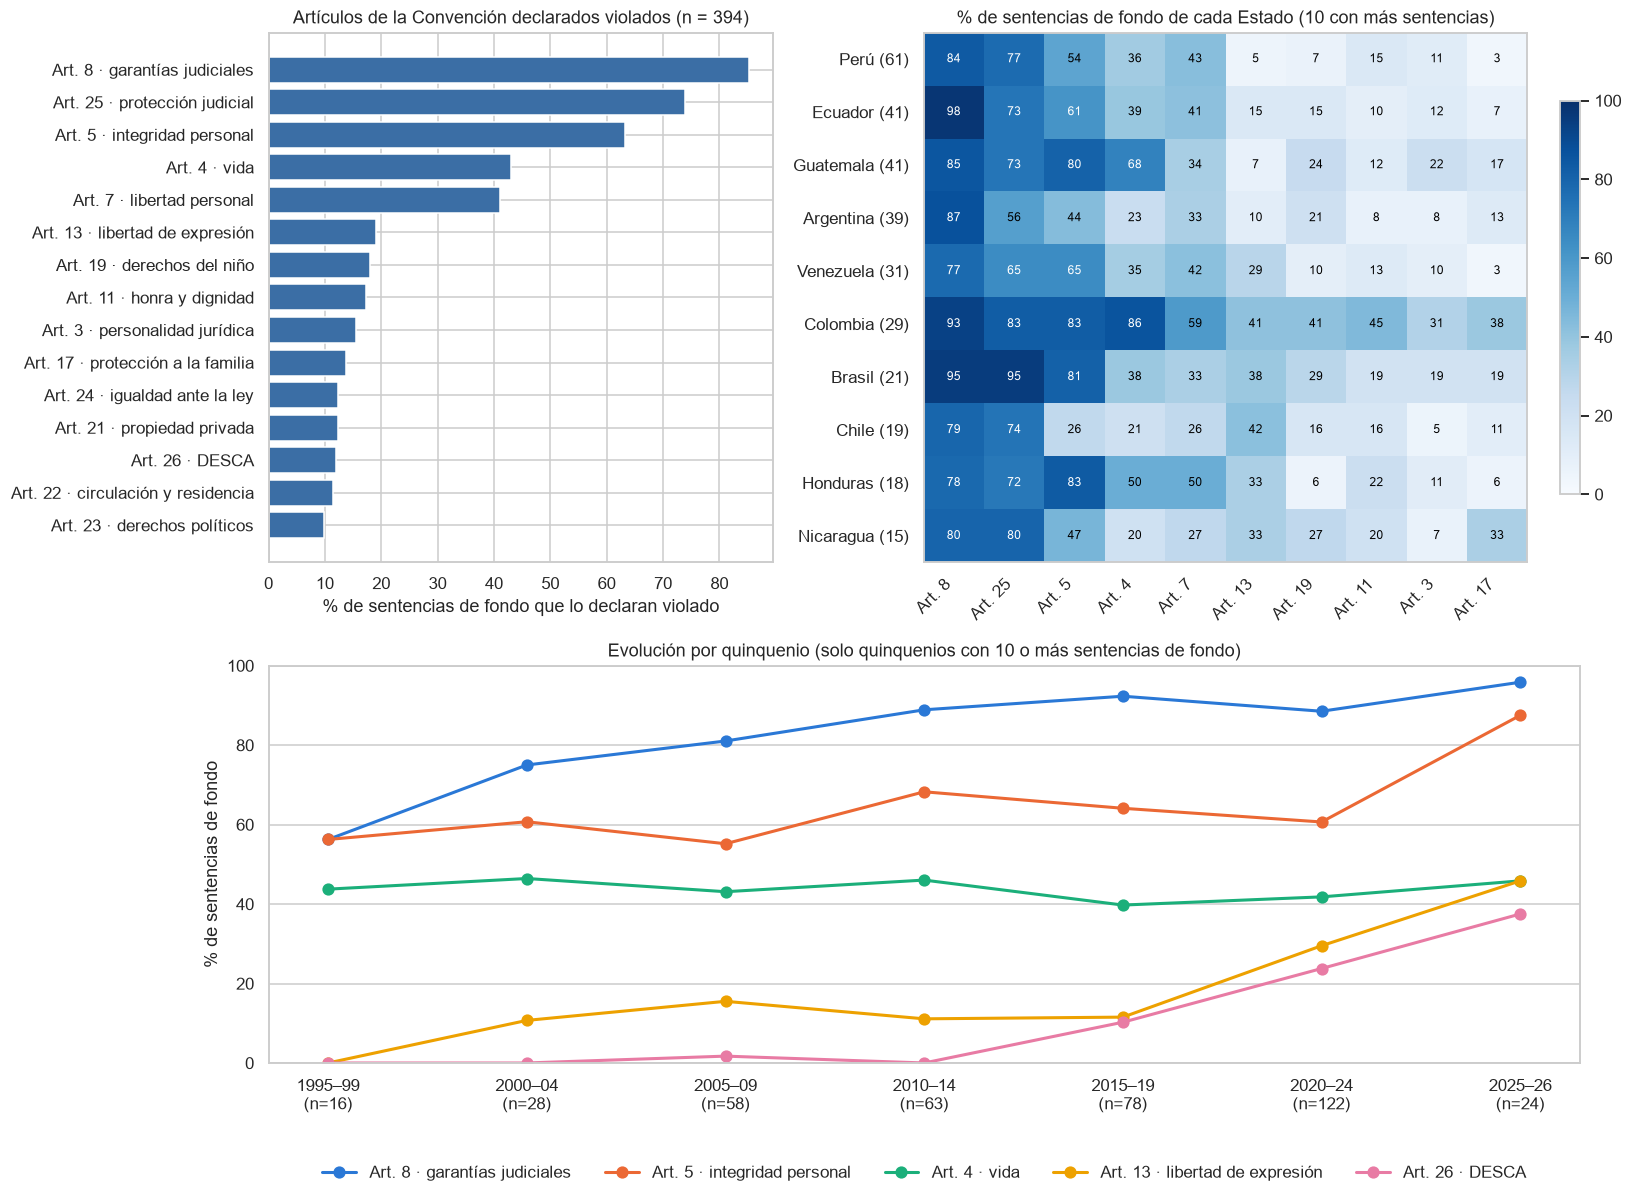

% de sentencias de fondo por quinquenio:


anio,1995,2000,2005,2010,2015,2020,2025
articulo,,,,,,,
8,56,75,81,89,92,89,96
5,56,61,55,68,64,61,88
4,44,46,43,46,40,42,46
13,0,11,16,11,12,30,46
26,0,0,2,0,10,24,38


In [48]:
# ============================================================
# ANÁLISIS DE CONTENIDO: ARTÍCULOS DECLARADOS VIOLADOS
# ============================================================
# Una fila por sentencia de fondo; se cuenta cada artículo una vez por sentencia.
art_sent = (docs_rag[es_fondo][["doc_id", "estado", "anio", "articulos_violados"]]
            .explode("articulos_violados").dropna(subset=["articulos_violados"]))
art_sent["articulo"] = art_sent["articulos_violados"].astype(int)
n_fondo = es_fondo.sum()

frec = art_sent["articulo"].value_counts()
tabla_art = pd.DataFrame({
    "derecho": [NOMBRES_ARTICULOS.get(a, "") for a in frec.index],
    "sentencias": frec.values,
    "% de sentencias de fondo": (100 * frec.values / n_fondo).round(1),
}, index=pd.Index(frec.index, name="artículo"))
display(tabla_art.head(15))

top_art = frec.index[:10]
top_est = docs_rag[es_fondo]["estado"].value_counts().index[:10]
por_estado = (art_sent[art_sent["estado"].isin(top_est) & art_sent["articulo"].isin(top_art)]
              .groupby(["estado", "articulo"]).size().unstack(fill_value=0)
              .reindex(index=top_est, columns=top_art, fill_value=0))
pct_estado = 100 * por_estado.div(docs_rag[es_fondo]["estado"].value_counts().reindex(top_est), axis=0)

# Evolución: % de las sentencias de fondo de cada quinquenio que declaran violado cada artículo.
# Solo quinquenios con al menos 10 sentencias de fondo (con menos, los porcentajes saltan demasiado).
quinq_fondo = (docs_rag.loc[es_fondo, "anio"].dropna() // 5 * 5).astype(int).value_counts().sort_index()
quinq_fondo = quinq_fondo[quinq_fondo >= 10]
evol = (art_sent.dropna(subset=["anio"]).assign(quinquenio=lambda d: (d["anio"] // 5 * 5).astype(int))
        .groupby(["quinquenio", "articulo"]).size().unstack(fill_value=0)
        .reindex(quinq_fondo.index, fill_value=0))
evol = 100 * evol.div(quinq_fondo, axis=0)
ARTS_EVOL = {8: "#2a78d6", 5: "#eb6834", 4: "#1baf7a", 13: "#eda100", 26: "#e87ba4"}   # estables y en alza
anio_max = int(docs_rag["anio"].max())   # el último quinquenio está incompleto

fig, ax = plt.subplot_mosaic([["barras", "mapa"], ["tiempo", "tiempo"]], figsize=(15, 11),
                             gridspec_kw={"width_ratios": [1, 1.3], "height_ratios": [1, 0.75]})
etiquetas = [f"Art. {a} · {NOMBRES_ARTICULOS.get(a, '')}" for a in frec.index[:15]]
ax["barras"].barh(etiquetas[::-1], tabla_art["% de sentencias de fondo"].head(15)[::-1], color="#3b6ea5")
ax["barras"].set_xlabel("% de sentencias de fondo que lo declaran violado")
ax["barras"].set_title(f"Artículos de la Convención declarados violados (n = {n_fondo})")
im = ax["mapa"].imshow(pct_estado.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax["mapa"].set_xticks(range(len(top_art)), [f"Art. {a}" for a in top_art], rotation=45, ha="right")
ax["mapa"].set_yticks(range(len(top_est)), [f"{e.title()} ({n})" for e, n in
                                            docs_rag[es_fondo]["estado"].value_counts().reindex(top_est).items()])
for i in range(len(top_est)):
    for j in range(len(top_art)):
        v = pct_estado.values[i, j]
        ax["mapa"].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
ax["mapa"].set_title("% de sentencias de fondo de cada Estado (10 con más sentencias)")
ax["mapa"].grid(False)
fig.colorbar(im, ax=ax["mapa"], fraction=0.03)

for a, color in ARTS_EVOL.items():
    ax["tiempo"].plot(evol.index, evol.get(a, 0), marker="o", ms=7, lw=2, color=color,
                      label=f"Art. {a} · {NOMBRES_ARTICULOS[a]}")
ax["tiempo"].set_xticks(evol.index, [f"{q}–{str(min(q + 4, anio_max))[2:]}\n(n={n})" for q, n in quinq_fondo.items()])
ax["tiempo"].set_ylim(0, 100); ax["tiempo"].set_ylabel("% de sentencias de fondo")
ax["tiempo"].set_title("Evolución por quinquenio (solo quinquenios con 10 o más sentencias de fondo)")
ax["tiempo"].legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax["tiempo"].grid(False, axis="x")
guardar_fig("fig10_articulos_violados")
print("% de sentencias de fondo por quinquenio:")
display(evol[list(ARTS_EVOL)].round(0).astype(int).T)

**Qué declara violado la Corte.** Las garantías judiciales (art. 8) y la protección judicial (art. 25) aparecen en tres de cada cuatro sentencias de fondo: casi todo caso es también un caso de acceso a la justicia. La integridad personal (art. 5) y la vida (art. 4) se mantienen estables en el tiempo. Lo que cambia es la agenda. El art. 26 (derechos económicos, sociales, culturales y ambientales) no se declaraba violado antes de 2015 y está en una de cada tres sentencias recientes. La libertad de expresión (art. 13) también crece. Para el RAG, esto indica qué temas debe cubrir bien la recuperación y cuáles son más recientes y tienen menos jurisprudencia.

count    79799.000000
mean       181.523653
std         55.367892
min          1.000000
25%        147.000000
50%        195.000000
75%        227.000000
90%        242.000000
95%        247.000000
max        290.000000
Name: num_palabras, dtype: float64


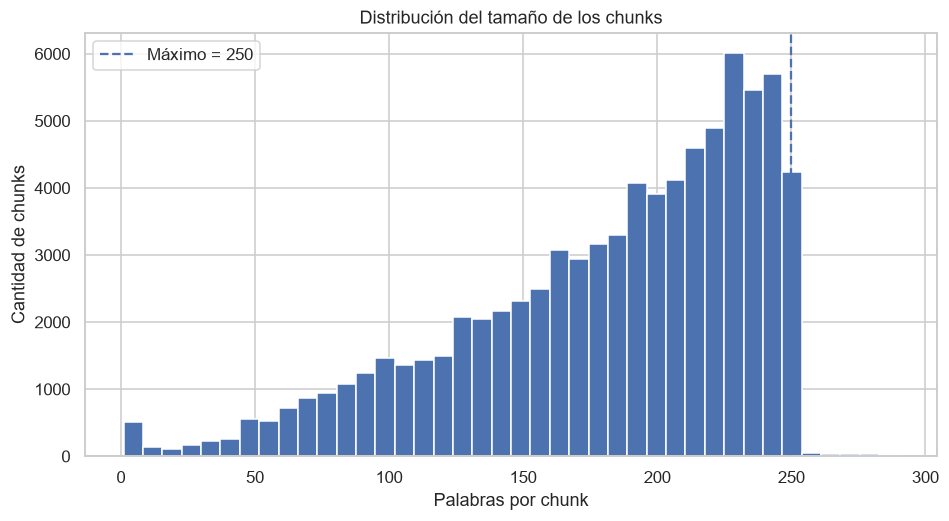

In [49]:
# ============================================================
# DISTRIBUCIÓN DE TAMAÑOS DE CHUNKS
# ============================================================

print(
    df_chunks["num_palabras"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

plt.figure(figsize=(10, 5))

plt.hist(
    df_chunks["num_palabras"],
    bins=40
)

plt.axvline(
    MAX_PALABRAS,
    linestyle="--",
    label=f"Máximo = {MAX_PALABRAS}"
)

plt.xlabel("Palabras por chunk")
plt.ylabel("Cantidad de chunks")
plt.title("Distribución del tamaño de los chunks")
plt.legend()

plt.show()

In [50]:
# ============================================================
# 3.2 BAG OF WORDS
# ============================================================

bow_vectorizer = CountVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b"
)

X_bow = bow_vectorizer.fit_transform(
    df_chunks["texto_normalizado"]
)

print("Matriz BoW:", X_bow.shape)
print(
    "Tamaño vocabulario:",
    len(bow_vectorizer.vocabulary_)
)

Matriz BoW: (79799, 50592)
Tamaño vocabulario: 50592


In [51]:
# ============================================================
# EJEMPLO DE REPRESENTACIÓN BOW
# ============================================================

bow_features = bow_vectorizer.get_feature_names_out()

print("Primeras 30 características:")
print(bow_features[:30])

print("\nForma de la matriz:")
print(X_bow.shape)

print("\nMatriz del primer chunk:")
print(
    X_bow[0].toarray()
)

Primeras 30 características:
['aaa' 'aaas' 'aac' 'aacto' 'aaddfi' 'aadi' 'aahjj' 'aamp' 'aanmg' 'aar'
 'aarhus' 'aarón' 'aas' 'aat' 'aba' 'abad' 'abadalá' 'abadia' 'abadía'
 'abafador' 'abaisa' 'abajito' 'abajo' 'abalance' 'abalanzar' 'abanderan'
 'abanderar' 'abandonado' 'abandonar' 'abandonara']

Forma de la matriz:
(79799, 50592)

Matriz del primer chunk:
[[0 0 0 ... 0 0 0]]


In [52]:
# ============================================================
# 3.3 TF-IDF
# ============================================================

tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 2),
    min_df=3,          # descarta términos de 1–2 chunks (ruido de OCR, nombres propios aislados)
    max_df=0.5,        # descarta términos presentes en más de la mitad de los chunks
    sublinear_tf=True
)

X_tfidf = tfidf_vectorizer.fit_transform(
    df_chunks["texto_normalizado"]
)

print("Matriz TF-IDF:", X_tfidf.shape)

print(
    "Vocabulario:",
    len(tfidf_vectorizer.vocabulary_)
)

Matriz TF-IDF: (79799, 348689)
Vocabulario: 348689


In [53]:
# ============================================================
# CARACTERÍSTICAS TF-IDF
# ============================================================

tfidf_features = (
    tfidf_vectorizer
    .get_feature_names_out()
)

print("Primeras 50 características:")
print(tfidf_features[:50])

Primeras 50 características:


['aaas' 'aac' 'aamp' 'aamp buenaventura' 'aarhus' 'aarón' 'aarón enríquez'
 'abad' 'abad agurto' 'abad carranza' 'abad gómez' 'abad hijo'
 'abad yupanqui' 'abadía' 'abafador' 'abajo' 'abajo detenido' 'abajo no'
 'abajo piso' 'abajo suelo' 'abajo viga' 'abandonado' 'abandonado llamado'
 'abandonado misteriosa' 'abandonar' 'abandonar actividad'
 'abandonar acusación' 'abandonar aldea' 'abandonar barrio'
 'abandonar cargo' 'abandonar carretera' 'abandonar casa'
 'abandonar ciudad' 'abandonar colombia' 'abandonar comunidad'
 'abandonar definitivamente' 'abandonar demarcación' 'abandonar domicilio'
 'abandonar ecuador' 'abandonar escuela' 'abandonar estudio'
 'abandonar guatemala' 'abandonar hacienda' 'abandonar hijo'
 'abandonar hogar' 'abandonar hospital' 'abandonar inmueble'
 'abandonar intempestivamente' 'abandonar lugar' 'abandonar organización']


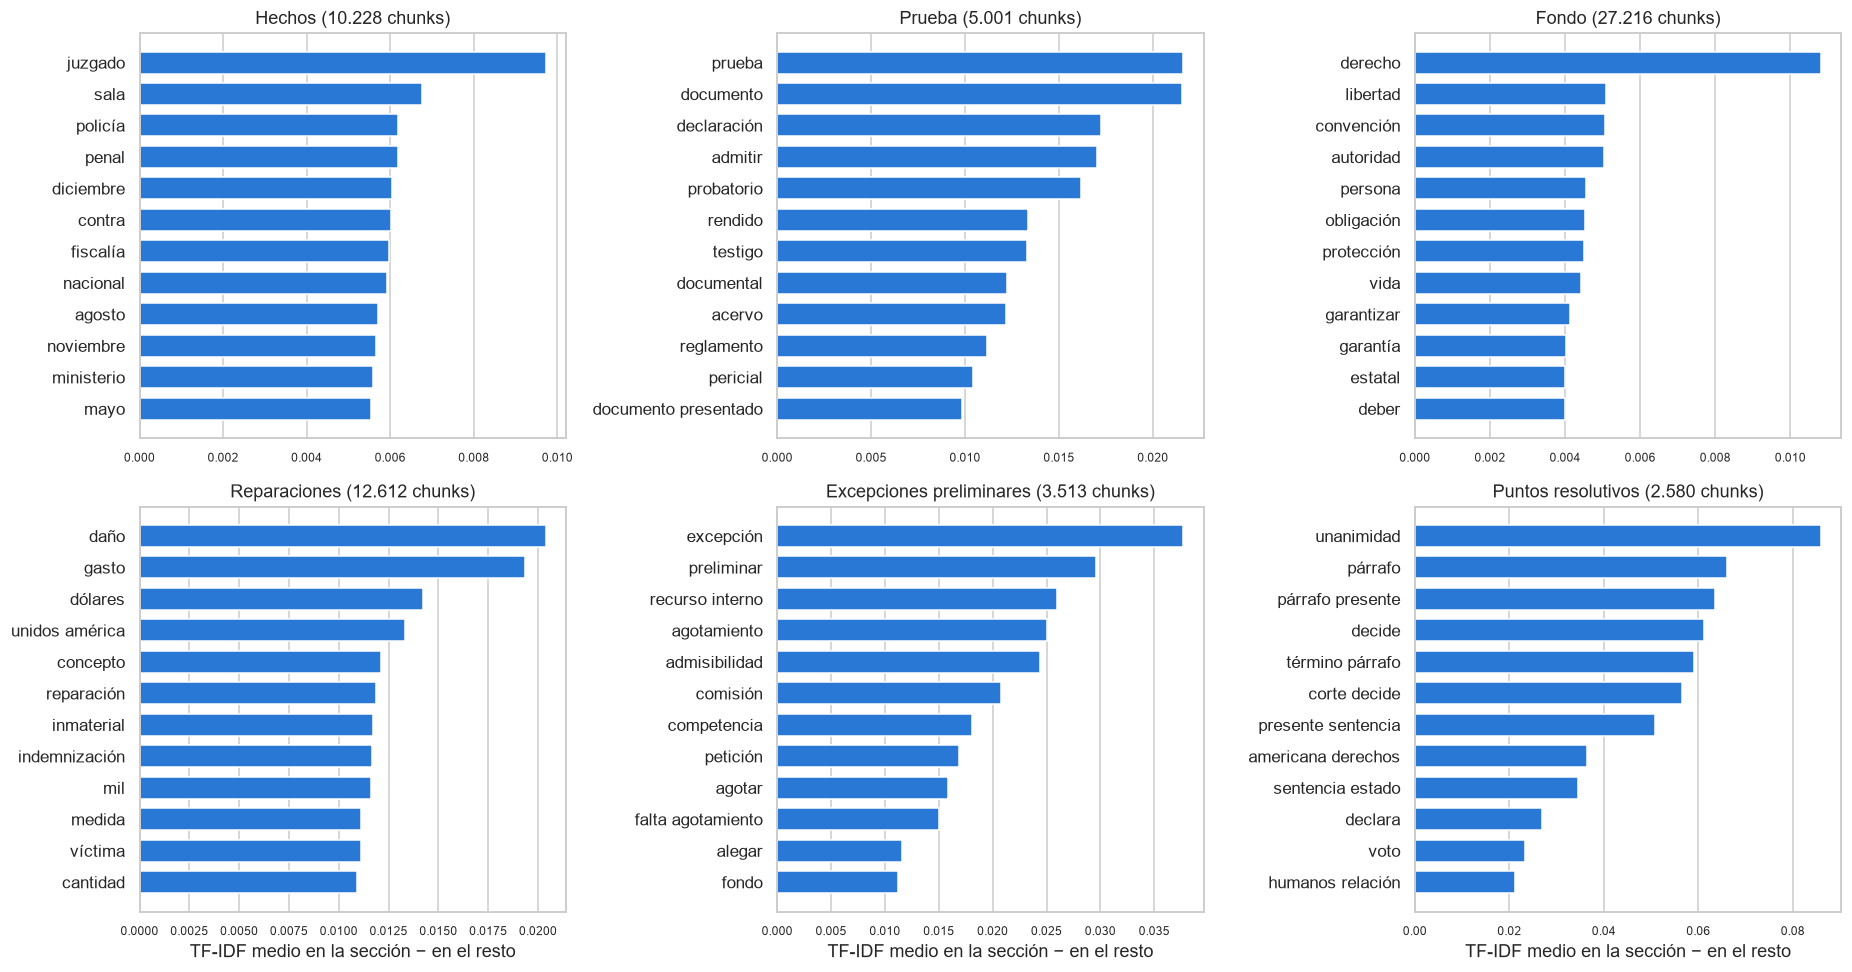

,Hechos,Prueba,Fondo,Reparaciones,Excepciones preliminares,Puntos resolutivos
0,juzgado,prueba,derecho,daño,excepción,unanimidad
1,sala,documento,libertad,gasto,preliminar,párrafo
2,policía,declaración,convención,dólares,recurso interno,párrafo presente
3,penal,admitir,autoridad,unidos américa,agotamiento,decide
4,diciembre,probatorio,persona,concepto,admisibilidad,término párrafo
5,contra,rendido,obligación,reparación,comisión,corte decide
6,fiscalía,testigo,protección,inmaterial,competencia,presente sentencia
7,nacional,documental,vida,indemnización,petición,americana derechos


In [54]:
# ============================================================
# TÉRMINOS CARACTERÍSTICOS DE CADA SECCIÓN
# ============================================================
# Para cada sección: peso TF-IDF medio del término en sus chunks menos su peso medio en el resto de chunks.
# Restar el resto evita que ganen los términos frecuentes en todas las secciones («víctima», «derecho»).
SECCIONES_TERM = ["Hechos", "Prueba", "Fondo", "Reparaciones", "Excepciones preliminares", "Puntos resolutivos"]
sec_chunk = df_chunks["seccion_canonica"].to_numpy()
suma_total = np.asarray(X_tfidf.sum(axis=0)).ravel()

fig, axs = plt.subplots(2, 3, figsize=(17, 9))
terminos_seccion = {}
for a, sec in zip(axs.ravel(), SECCIONES_TERM):
    m = sec_chunk == sec
    suma_sec = np.asarray(X_tfidf[m].sum(axis=0)).ravel()
    distintivo = suma_sec / m.sum() - (suma_total - suma_sec) / (~m).sum()
    top, cubiertas = [], set()
    for j in np.argsort(distintivo)[::-1]:       # sin repetir una expresión como unigrama y bigrama
        palabras = set(tfidf_features[j].split())
        if not palabras <= cubiertas:
            top.append(j); cubiertas |= palabras
        if len(top) == 12:
            break
    top = np.array(top)
    terminos_seccion[sec] = list(tfidf_features[top])
    a.barh(tfidf_features[top][::-1], distintivo[top][::-1], color="#2a78d6", height=0.7)
    a.set_title(f"{sec} ({m.sum():,} chunks)".replace(",", "."))
    a.tick_params(axis="x", labelsize=8); a.grid(False, axis="y")
for a in axs[1]:
    a.set_xlabel("TF-IDF medio en la sección − en el resto")
guardar_fig("fig12_terminos_por_seccion")
display(pd.DataFrame(terminos_seccion).head(8))

**Cada sección tiene su vocabulario.**
- Hechos: juzgados, fiscalías y fechas.
- Prueba: el lenguaje probatorio.
- Fondo: derechos y obligaciones.
- Reparaciones: daño, gastos y montos en dólares.
- Excepciones preliminares: el agotamiento de los recursos internos.
- Puntos resolutivos: las fórmulas fijas de la decisión.

Esto confirma que la detección de secciones del punto 2 separa contenidos distintos, y justifica el filtro por sección de `buscar()`.

In [55]:
# ============================================================
# 3.4 BM25
# ============================================================
# Línea base léxica estándar en recuperación de información: a diferencia de TF-IDF con coseno,
# satura la frecuencia del término (k1) y normaliza por la longitud del chunk (b).
# Usa los mismos lemas que TF-IDF, así que la consulta pasa por normalizar().
tokens_bm25 = df_chunks["texto_normalizado"].str.split().tolist()
bm25 = BM25Okapi(tokens_bm25, k1=1.5, b=0.75)
print("Chunks indexados:", bm25.corpus_size, "| longitud media en lemas:", round(bm25.avgdl, 1))

Chunks indexados: 79799 | longitud media en lemas: 80.9


In [56]:
import torch
print("Torch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Capacidad:", torch.cuda.get_device_capability(0))
    print("Memoria total (GB):", round(torch.cuda.get_device_properties(0).total_memory/1e9, 2))

Torch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4070
Capacidad: (8, 9)
Memoria total (GB): 12.88


In [57]:
%pip -q install -U sentence-transformers

import torch
from sentence_transformers import SentenceTransformer

MODELO_EMBEDDING = "intfloat/multilingual-e5-base"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

embedding_model = SentenceTransformer(MODELO_EMBEDDING, device=DEVICE)

if DEVICE == "cuda":
    embedding_model = embedding_model.half()      # fp16 → ~2x más rápido

embedding_model.max_seq_length = 512              # máximo de e5; con 256 se truncaba el 74 % de los chunks (ver abajo)
print("Modelo cargado.")

Note: you may need to restart the kernel to use updated packages.
Device: cuda


Modelo cargado.


In [58]:
# ============================================================
# ¿CUÁNTO TEXTO VE EL MODELO?
# ============================================================
# El modelo solo lee max_seq_length tokens: lo que sobra se descarta sin aviso.
# Los chunks tienen hasta 290 palabras más la cabecera, y el español con este tokenizador
# usa ~1,6 tokens por palabra, así que 256 tokens se quedaban cortos.
longitudes = np.array([len(ids) for ids in embedding_model.tokenizer(
    [f"passage: {t}" for t in df_chunks["texto_con_contexto"]])["input_ids"]])
print("Tokens por chunk: mediana", int(np.median(longitudes)), "| p99", int(np.percentile(longitudes, 99)),
      "| máximo", longitudes.max())
for lim in (256, 384, 512):
    print(f"  chunks truncados con max_seq_length={lim}: {100 * (longitudes > lim).mean():5.1f} %")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (517 > 512). Running this sequence through the model will result in indexing errors


Tokens por chunk: mediana 318 | p99 449 | máximo 750
  chunks truncados con max_seq_length=256:  73.6 %
  chunks truncados con max_seq_length=384:  13.3 %
  chunks truncados con max_seq_length=512:   0.1 %


In [59]:
# ============================================================
# GENERACIÓN DE EMBEDDINGS PARA LOS CHUNKS
# ============================================================

import numpy as np
import torch

textos_embedding = [f"passage: {t}" for t in df_chunks["texto_con_contexto"]]
print("N chunks:", len(textos_embedding))

with torch.inference_mode():
    embeddings = embedding_model.encode(
        textos_embedding,
        batch_size=128,              # con 512 tokens, 128 cabe en 12 GB en fp16
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
        device=DEVICE,
    )

embeddings = embeddings.astype(np.float32)
print("Forma:", embeddings.shape)



N chunks:

 79799


Forma: (79799, 768)


In [60]:
# ============================================================
# 3.5 VISUALIZACIÓN
# ============================================================

!pip -q install umap-learn

import umap.umap_ as umap

# ============================================================
# REDUCCIÓN DE DIMENSIONALIDAD CON UMAP
# ============================================================

MAX_VIS = min(
    2000,
    len(embeddings)
)

rng = np.random.default_rng(42)

indices_vis = rng.choice(
    len(embeddings),
    size=MAX_VIS,
    replace=False
)

embeddings_vis = embeddings[
    indices_vis
]

df_vis = df_chunks.iloc[
    indices_vis
].copy()

reducer = umap.UMAP(
    n_components=2,
    random_state=42,
    n_neighbors=15,
    min_dist=0.1
)

embedding_2d = reducer.fit_transform(
    embeddings_vis
)

print(
    "Dimensiones después de UMAP:",
    embedding_2d.shape
)

Dimensiones después de UMAP: (2000, 2)


Sentencias con otra sentencia del mismo caso: 290 de 596. Su vecina más cercana es del mismo caso en el 95 % (al azar: 0.2 %).


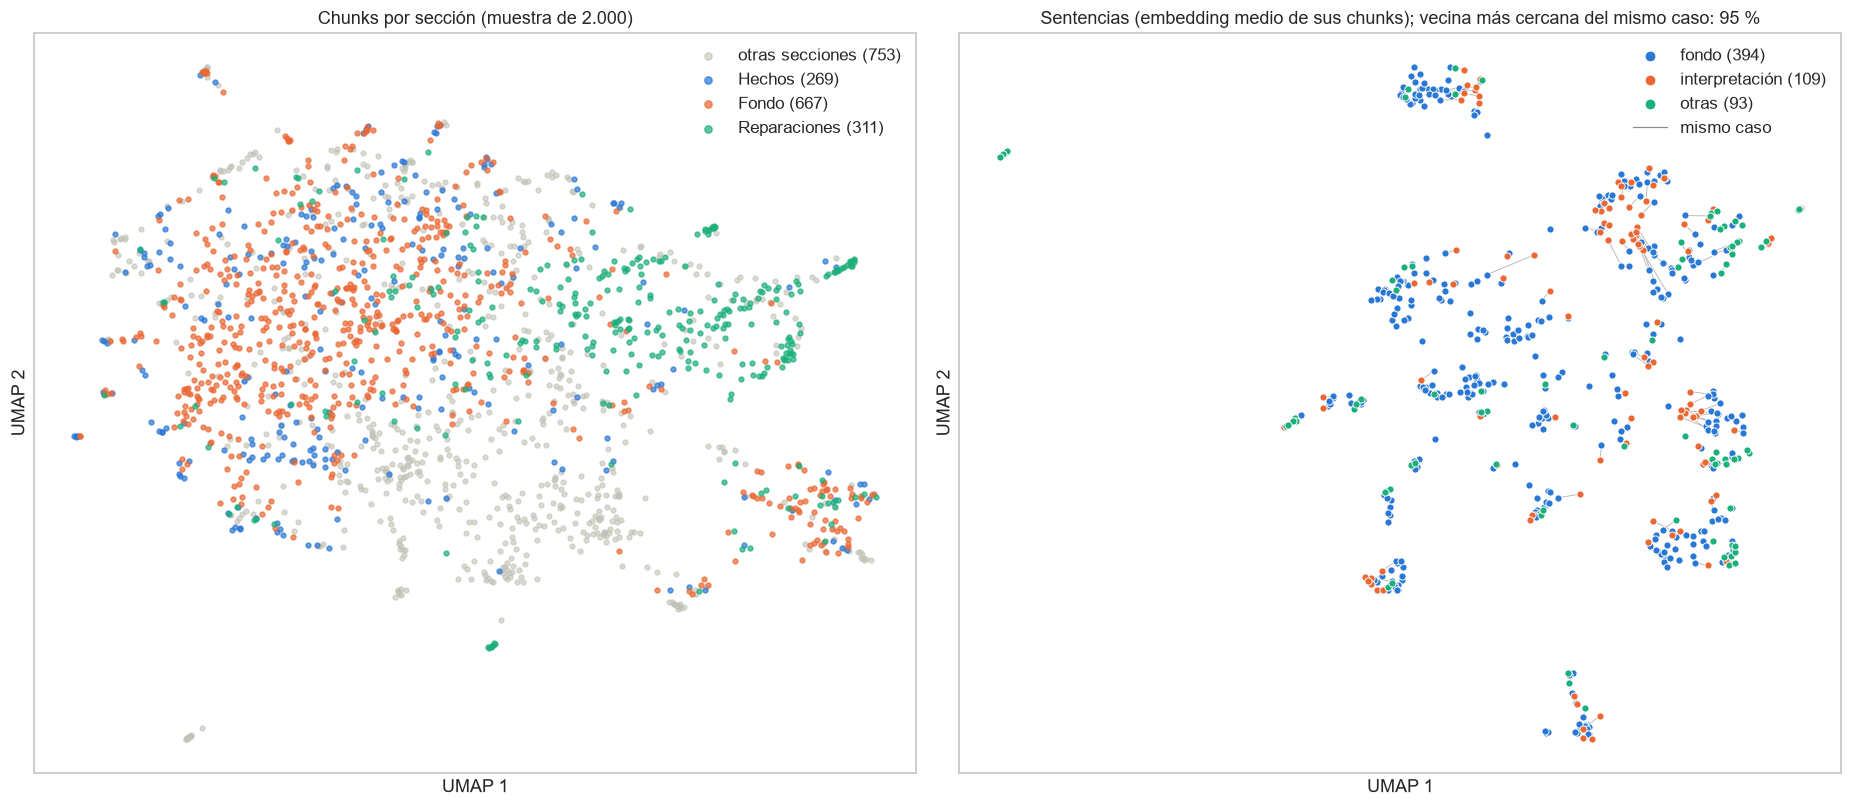

In [61]:
# ============================================================
# GRÁFICO DE LOS EMBEDDINGS
# ============================================================
# a) Chunks de la muestra, coloreados por sección (las tres más grandes; el resto en gris).
# b) Sentencias: embedding medio de sus chunks, coloreado por tipo; una línea une las sentencias del mismo caso.
# Si los embeddings capturan el contenido, las secciones forman regiones y las sentencias de un caso quedan juntas.
# Salvedad: cada chunk lleva en su cabecera el título del caso, que también acerca las sentencias de un mismo caso.
SEC_COLOR = {"Hechos": "#2a78d6", "Fondo": "#eb6834", "Reparaciones": "#1baf7a"}
TIPO_COLOR = {"fondo": "#2a78d6", "interpretación": "#eb6834", "otras": "#1baf7a"}

ids_doc, pos_doc = np.unique(df_chunks["doc_id"].to_numpy(), return_inverse=True)
emb_doc = np.zeros((len(ids_doc), embeddings.shape[1]), dtype=np.float64)
np.add.at(emb_doc, pos_doc, embeddings)
emb_doc /= np.linalg.norm(emb_doc, axis=1, keepdims=True)
meta_vis = df_chunks.drop_duplicates("doc_id").set_index("doc_id").loc[ids_doc]

# ¿La sentencia más parecida (coseno) es del mismo caso?
sim = emb_doc @ emb_doc.T
np.fill_diagonal(sim, -1)
caso = meta_vis["caso_id"].to_numpy()
n_caso = pd.Series(caso).map(pd.Series(caso).value_counts()).to_numpy()
con_otra = n_caso > 1
acierto = (caso[sim.argmax(1)] == caso)[con_otra].mean()
azar = ((n_caso - 1) / (len(caso) - 1))[con_otra].mean()
print(f"Sentencias con otra sentencia del mismo caso: {con_otra.sum()} de {len(caso)}. "
      f"Su vecina más cercana es del mismo caso en el {100 * acierto:.0f} % (al azar: {100 * azar:.1f} %).")

doc_2d = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1, random_state=42).fit_transform(emb_doc)
tipo_vis = meta_vis["tipo_sentencia"].where(meta_vis["tipo_sentencia"].isin(["fondo", "interpretación"]), "otras").to_numpy()
sec_vis = df_vis["seccion_canonica"].where(df_vis["seccion_canonica"].isin(list(SEC_COLOR)), "Otras").to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
otras = sec_vis == "Otras"
ax[0].scatter(*embedding_2d[otras].T, s=10, color="#c3c2b7", alpha=0.6, label=f"otras secciones ({otras.sum()})")
for sec, color in SEC_COLOR.items():
    m = sec_vis == sec
    ax[0].scatter(*embedding_2d[m].T, s=10, color=color, alpha=0.7, label=f"{sec} ({m.sum()})")
ax[0].set_title(f"Chunks por sección (muestra de {len(embedding_2d):,})".replace(",", "."))

for c in pd.unique(caso[con_otra]):
    p = doc_2d[caso == c]
    ax[1].plot(*p.T, color="#8a8984", lw=0.6, alpha=0.6, zorder=1)
for tipo, color in TIPO_COLOR.items():
    m = tipo_vis == tipo
    ax[1].scatter(*doc_2d[m].T, s=22, color=color, edgecolor="white", linewidth=0.6, zorder=2,
                  label=f"{tipo} ({m.sum()})")
ax[1].plot([], [], color="#8a8984", lw=0.8, label="mismo caso")
ax[1].set_title(f"Sentencias (embedding medio de sus chunks); vecina más cercana del mismo caso: {100 * acierto:.0f} %")
for a in ax:
    a.set_xticks([]); a.set_yticks([]); a.set_xlabel("UMAP 1"); a.set_ylabel("UMAP 2")
    a.legend(frameon=False, markerscale=1.5, loc="best"); a.grid(False)
guardar_fig("fig13_umap_embeddings")

**Los embeddings separan contenidos.**
- **Por sección.** Los chunks de reparaciones forman una región propia. Los de hechos y fondo se mezclan, porque el fondo vuelve a narrar los hechos al analizarlos.
- **Por caso.** La sentencia más parecida a otra es del mismo caso en la gran mayoría de los casos, frente a menos del 1 % al azar. Parte de ese parecido viene del título del caso en la cabecera de cada chunk. Que los embeddings capturen el contenido jurídico lo muestran mejor las evaluaciones B y C del punto 4.

In [62]:
# ============================================================
# 3.7 RECUPERACIÓN LÉXICA: TF-IDF Y BM25
# ============================================================
# Cada función devuelve un puntaje por chunk; buscar() (más abajo) filtra, ordena y combina.

def puntajes_tfidf(consulta):
    """Coseno TF-IDF entre la consulta normalizada y cada chunk (las filas de X_tfidf ya tienen norma 1)."""
    return (X_tfidf @ tfidf_vectorizer.transform([normalizar(consulta)]).T).toarray().ravel()


def puntajes_bm25(consulta):
    return bm25.get_scores(normalizar(consulta).split())


def ranking_lexico(puntajes, mascara, n):
    """Índices de los n chunks con mayor puntaje dentro de la máscara (sin los de puntaje 0)."""
    s = np.where(mascara & (puntajes > 0), puntajes, -np.inf)
    n = min(n, int(np.isfinite(s).sum()))
    top = np.argpartition(-s, n - 1)[:n] if n else np.array([], int)
    top = top[np.argsort(-s[top])]
    return top, s[top]

In [63]:
!pip -q install faiss-cpu

import faiss

# ============================================================
# CREAR ÍNDICE FAISS
# ============================================================

dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(
    dimension
)

faiss_index.add(
    embeddings
)

print(
    "Vectores indexados:",
    faiss_index.ntotal
)

print(
    "Dimensión:",
    dimension
)

Vectores indexados: 79799
Dimensión: 768


In [64]:
# ============================================================
# CASI DUPLICADOS ENTRE CASOS
# ============================================================
# La Corte repite párrafos casi literales de su jurisprudencia (costas y gastos, plazo razonable,
# artículo 63.1...). Se marcan los chunks con un vecino de otro caso con coseno >= 0,97: por debajo
# de ese umbral aparecen paráfrasis con contenido propio (e5 comprime las similitudes hacia arriba).
UMBRAL_CASI_DUPLICADO = 0.97
VECINOS_DUP = 6

S_knn, I_knn = faiss_index.search(embeddings, VECINOS_DUP)
caso_arr = df_chunks["caso_id"].to_numpy(dtype=object)
es_dup = ((S_knn >= UMBRAL_CASI_DUPLICADO) & (I_knn != np.arange(len(I_knn))[:, None])
          & (caso_arr[I_knn] != caso_arr[:, None]))
primero = I_knn[np.arange(len(I_knn)), es_dup.argmax(1)]
df_chunks["casi_duplicado_de"] = np.where(es_dup.any(1), df_chunks["chunk_id"].to_numpy(dtype=object)[primero], None)
df_chunks["n_casi_duplicados"] = es_dup.sum(1)

print(f"Chunks con un casi duplicado en otro caso: {es_dup.any(1).sum()} "
      f"({100 * es_dup.any(1).mean():.1f} %)")
print("\n% de chunks con casi duplicado, por sección canónica:")
print((100 * df_chunks.groupby("seccion_canonica")["casi_duplicado_de"].apply(lambda s: s.notna().mean()))
      .round(1).sort_values(ascending=False).to_string())
ejemplo = df_chunks[df_chunks["casi_duplicado_de"].notna()].iloc[0]
otro = df_chunks.set_index("chunk_id").loc[ejemplo["casi_duplicado_de"]]
print("\nEjemplo:\n ", ejemplo["titulo"], "|", ejemplo["texto"][:200], "\n ", otro["titulo"], "|", otro["texto"][:200])

Chunks con un casi duplicado en otro caso: 2274 (2.8 %)

% de chunks con casi duplicado, por sección canónica:
seccion_canonica
Competencia                    20.1
Sin sección                    15.9
Reparaciones                    5.4
Excepciones preliminares        3.5
Puntos resolutivos              3.1
Consideraciones previas         2.9
Otras                           2.3
Procedimiento ante la Corte     1.7
Fondo                           1.5
Prueba                          1.4
Introducción de la causa        1.3
Hechos                          0.8

Ejemplo:
  caso integrantes y militantes de la unión patriótica vs. colombia | A continuación, la Corte analizará las solicitudes del Estado y de los intervinientes comunes para determinar si, de acuerdo con la normativa y los estándares desarrollados en su jurisprudencia, proce 
  caso miembros de la corporación colectivo de abogados “josé alvear restrepo” vs. colombia | Este Tribunal analizará las solicitudes formuladas por las parte

In [65]:
# ============================================================
# 3.8 BÚSQUEDA DENSA, HÍBRIDA Y FILTROS
# ============================================================
RRF_K = 60            # constante habitual de Reciprocal Rank Fusion (Cormack et al., 2009)
N_CANDIDATOS = 100    # candidatos por método antes de fusionar o diversificar


def ranking_denso(consulta, mascara, n):
    q = embedding_model.encode([f"query: {consulta}"], normalize_embeddings=True,
                               convert_to_numpy=True).astype(np.float32)
    params = None
    if not mascara.all():   # el filtro se aplica dentro de FAISS: la búsqueda sigue siendo exacta
        params = faiss.SearchParameters(sel=faiss.IDSelectorBatch(np.flatnonzero(mascara).astype("int64")))
    s, i = faiss_index.search(q, n, params=params)
    ok = i[0] >= 0
    return i[0][ok], s[0][ok]


def rrf(*rankings, k=RRF_K):
    """Reciprocal Rank Fusion: suma 1/(k + posición) de cada lista. No necesita calibrar puntajes."""
    puntaje = {}
    for r in rankings:
        for pos, i in enumerate(r, 1):
            puntaje[i] = puntaje.get(i, 0.0) + 1.0 / (k + pos)
    orden = sorted(puntaje, key=puntaje.get, reverse=True)
    return np.array(orden, dtype=int), np.array([puntaje[i] for i in orden])


def mascara_filtros(estado=None, anio_min=None, anio_max=None, tipo_sentencia=None, articulo=None, seccion=None):
    """Filtros por metadatos y características de dominio. articulo: número de la Convención (p. ej. 13)."""
    m = np.ones(len(df_chunks), bool)
    if estado:
        m &= df_chunks["estado"].eq(estado.lower()).to_numpy()
    if anio_min:
        m &= df_chunks["anio"].ge(anio_min).to_numpy()
    if anio_max:
        m &= df_chunks["anio"].le(anio_max).to_numpy()
    if tipo_sentencia:
        m &= df_chunks["tipo_sentencia"].eq(tipo_sentencia).to_numpy()
    if articulo:
        m &= np.array([articulo in a for a in df_chunks["articulos_violados"]])
    if seccion:
        m &= df_chunks["seccion_canonica"].eq(seccion).to_numpy()
    return m


def diversificar(indices, k, max_por_caso=1, umbral=UMBRAL_CASI_DUPLICADO):
    """Posiciones de los primeros k resultados con a lo sumo max_por_caso por caso y sin casi duplicados."""
    elegidos, por_caso = [], {}
    for pos, i in enumerate(indices):
        c = df_chunks["caso_id"].iat[i]
        if por_caso.get(c, 0) >= max_por_caso:
            continue
        if elegidos and (embeddings[indices[elegidos]] @ embeddings[i]).max() >= umbral:
            continue
        elegidos.append(pos)
        por_caso[c] = por_caso.get(c, 0) + 1
        if len(elegidos) == k:
            break
    return elegidos


def buscar(consulta, metodo="hibrido", k=5, diversificado=True, **filtros):
    """metodo: tfidf, bm25, denso o hibrido (BM25 + denso con RRF). filtros: ver mascara_filtros()."""
    m = mascara_filtros(**filtros)
    n = N_CANDIDATOS if (diversificado or metodo == "hibrido") else k
    if metodo == "tfidf":
        idx, sc = ranking_lexico(puntajes_tfidf(consulta), m, n)
    elif metodo == "bm25":
        idx, sc = ranking_lexico(puntajes_bm25(consulta), m, n)
    elif metodo == "denso":
        idx, sc = ranking_denso(consulta, m, n)
    elif metodo == "hibrido":
        idx, sc = rrf(ranking_lexico(puntajes_bm25(consulta), m, n)[0], ranking_denso(consulta, m, n)[0])
    else:
        raise ValueError(metodo)
    pos = diversificar(idx, k) if diversificado else list(range(min(k, len(idx))))
    res = df_chunks.iloc[idx[pos]].copy()
    res["score"] = sc[pos]
    res["rank"] = range(1, len(res) + 1)
    return res


def buscar_tfidf(consulta, k=5, **kw):
    return buscar(consulta, "tfidf", k, **kw)


def buscar_denso(consulta, k=5, **kw):
    return buscar(consulta, "denso", k, **kw)

In [66]:
# ============================================================
# 3.9 COMPARACIÓN DE RECUPERACIÓN
# ============================================================
METODOS = ["tfidf", "bm25", "denso", "hibrido"]
CONSULTA = "libertad de expresión y periodistas"

# Top 5 de cada método, sin diversificar, para ver qué recupera cada uno tal cual
comparacion = pd.DataFrame({
    m: [f"{r.titulo[:45]} · {r.seccion_canonica}" for r in buscar(CONSULTA, m, k=5, diversificado=False).itertuples()]
    for m in METODOS
}, index=pd.Index(range(1, 6), name="rank"))
display(comparacion)
print("Casos distintos en el top 5 sin diversificar:",
      {m: buscar(CONSULTA, m, k=5, diversificado=False)["caso_id"].nunique() for m in METODOS})

,tfidf,bm25,denso,hibrido
rank,,,,
1,caso palacio urrutia y otros vs. ecuador · Fondo,caso mémoli vs. argentina · Fondo,caso granier y otros (radio caracas televisió · Fondo,caso fontevecchia y d’amico vs. argentina · Fondo
2,caso carvajal carvajal y otros vs. colombia · Fondo,caso carvajal carvajal y otros vs. colombia · Fondo,caso tristán donoso vs. panamá · Fondo,caso herrera ulloa vs. costa rica · Fondo
3,caso fontevecchia y d’amico vs. argentina · Fondo,caso moya chacón y otro vs. costa rica · Fondo,caso de la masacre de pueblo bello vs. colomb · Otras,caso tristán donoso vs. panamá · Fondo
4,caso carvajal carvajal y otros vs. colombia · Fondo,caso palacio urrutia y otros vs. ecuador · Fondo,caso claude reyes y otros vs. chile · Otras,caso palacio urrutia y otros vs. ecuador · Fondo
5,caso leguizamón zaván y otros vs. paraguay · Fondo,caso carvajal carvajal y otros vs. colombia · Fondo,caso ríos y otros vs. venezuela · Fondo,caso vélez restrepo y familiares vs. colombia · Fondo


Casos distintos en el top 5 sin diversificar: {'tfidf': 4, 'bm25': 4, 'denso': 5, 'hibrido': 5}


In [67]:
# ============================================================
# PRUEBAS DE RECUPERACIÓN (híbrido, un resultado por caso)
# ============================================================
CONSULTAS = [
    "libertad de expresión y periodistas",
    "desaparición forzada y obligación de investigar",
    "propiedad comunal de pueblos indígenas",
    "reparaciones ordenadas por la Corte Interamericana"
]

for consulta in CONSULTAS:
    print("\n" + "=" * 100)
    print("CONSULTA:", consulta)
    print("=" * 100)
    for _, fila in buscar(consulta, "hibrido", k=3).iterrows():
        print(f"\n[{fila['rank']}] {fila['titulo']} ({fila['anio']:.0f}) · artículos violados: {fila['articulos_violados']}")
        print(f"Sección: {fila['seccion']} [{fila['seccion_canonica']}] · párrafos {fila['parr_ini']}–{fila['parr_fin']}")
        print(fila["texto"][:500], "...")


CONSULTA: libertad de expresión y periodistas

[1] caso fontevecchia y d’amico vs. argentina (2011) · artículos violados: [13]
Sección: V. LIBERTAD DE PENSAMIENTO Y DE EXPRESIÓN, EN RELACIÓN CON LA OBLIGACIÓN DE RESPETAR LOS DERECHOS [Fondo] · párrafos 45.0–46.0
Dada la importancia de la libertad de expresión en una sociedad democrática y la elevada responsabilidad que ello entraña para quienes ejercen profesionalmente labores de comunicación social, el Estado no sólo debe minimizar las restricciones a la circulación de la información sino también equilibrar, en la mayor medida de lo posible, la participación de las distintas informaciones en el debate público, impulsando el pluralismo informativo. En consecuencia, la equidad debe regir el flujo informa ...

[2] caso herrera ulloa vs. costa rica (2004) · artículos violados: [8, 13]
Sección: X. VIOLACION DEL ARTICULO 13 EN RELACIÓN CON LOS ARTÍCULOS 1.1 Y 2 (DERECHO A LA LIBERTAD DE PENSAMIENTO [Fondo] · párrafos 117.0–119.0
Los medios


[1] caso leite de souza y otros vs. brasil (2024) · artículos violados: [3, 4, 5, 7, 8, 13, 17, 19, 25]
Sección: VIII-2. DERECHOS A LAS GARANTÍAS JUDICIALES, A LA PROTECCIÓN JUDICIAL, A CONOCER LA VERDAD, DE LA NIÑEZ, A LA IGUALDAD ANTE LA LEY, A LA LIBERTAD DE PENSAMIENTO Y EXPRESIÓN Y A LA LIBERTAD DE ASOCIACIÓN, [Fondo] · párrafos 131.0–132.0
A continuación, la Corte se referirá a las obligaciones concretas en relación con las investigaciones por i) la desaparición de 11 personas y ii) la muerte de las señoras Edmea da Silva Euzebio y Sheila da Conceição. Finalmente, la Corte analizará los alegatos relacionados con iii) el supuesto trato discriminatorio sufrido por las víctimas de desaparición forzada y por sus familiares durante el trámite de las investigaciones y los procesos judiciales. B.1. La investigación y la acción de reparac ...

[2] caso tenorio roca y otros vs. perú (2016) · artículos violados: [3, 4, 5, 7, 8, 25]
Sección: VII-2. DERECHOS A LAS GARANTÍAS JUDICIALES Y A L


[1] caso osorio rivera y familiares vs. perú (2014) · artículos violados: []
Sección: I. SOLICITUD DE INTERPRETACIÓN Y PROCEDIMIENTO ANTE LA CORTE [Procedimiento ante la Corte] · párrafos 1.0–4.0
El 26 de noviembre de 2013 la Corte emitió la Sentencia, la cual fue notificada a las partes y a la Comisión el 23 de diciembre del mismo año.

El 21 de marzo de 2014 el Estado peruano sometió a la Corte una solicitud de interpretación, en relación con cuatro aspectos de la Sentencia: (1) la reparación ordenada en cuanto a la tipificación adecuada del delito de desaparición forzada; (2) las consideraciones sobre las leyes de amnistía; (3) la reparación ordenada en cuanto a los programas de capac ...

[2] caso isaza uribe y otros vs. colombia (2018) · artículos violados: [3, 4, 5, 7, 8, 11, 16, 17, 25]
Sección: IX. REPARACIONES (APLICACIÓN DEL ARTÍCULO 63.1 DE LA CONVENCIÓN AMERICANA) [Reparaciones] · párrafos 170.0–173.0
Con base en lo dispuesto en el artículo 63.1 de la Convención Americana,

In [68]:
# ============================================================
# BÚSQUEDA CON FILTROS
# ============================================================
# Los filtros restringen el universo antes de ordenar, en los cuatro métodos.
ejemplos_filtro = [
    ("desaparición forzada y obligación de investigar", dict(estado="guatemala", articulo=7)),
    ("consulta previa a pueblos indígenas", dict(seccion="Reparaciones", anio_min=2015)),
    ("libertad de expresión y periodistas", dict(articulo=13, tipo_sentencia="fondo")),
]
for consulta, filtros in ejemplos_filtro:
    print(f"\n{consulta}  |  filtros: {filtros}  |  chunks elegibles: {mascara_filtros(**filtros).sum()}")
    display(buscar(consulta, "hibrido", k=3, **filtros)[["rank", "titulo", "estado", "anio", "seccion_canonica",
                                                         "articulos_violados", "score"]])


desaparición forzada y obligación de investigar  |  filtros: {'estado': 'guatemala', 'articulo': 7}  |  chunks elegibles: 2985


,rank,titulo,estado,anio,seccion_canonica,articulos_violados,score
43224,1,caso garcía y familiares vs. guatemala,guatemala,2012.0,Otras,"[3, 4, 5, 7, 8, 16, 25]",0.031099
45871,2,caso gudiel álvarez y otros (“diario militar”) vs. guatemala,guatemala,2012.0,Otras,"[3, 4, 5, 7, 8, 11, 16, 17, 19, 22, 25]",0.030777
3180,3,caso pérez lucas y otros vs. guatemala,guatemala,2024.0,Fondo,"[3, 4, 5, 7, 8, 13, 16, 17, 19, 22, 25]",0.030622



consulta previa a pueblos indígenas  |  filtros: {'seccion': 'Reparaciones', 'anio_min': 2015}  |  chunks elegibles: 6896


,rank,titulo,estado,anio,seccion_canonica,articulos_violados,score
71275,1,caso pueblos indígenas maya kaqchikel de sumpango y otros vs. guatemala,guatemala,2021.0,Reparaciones,"[13, 24, 26]",0.031010
77608,2,caso comunidad indígena maya q’eqchi’ agua caliente vs. guatemala,guatemala,2023.0,Reparaciones,"[3, 5, 8, 13, 21, 23, 25]",0.030798
58635,3,caso pueblos kaliña y lokono vs. surinam,surinam,2015.0,Reparaciones,"[3, 21, 23, 25]",0.030579



libertad de expresión y periodistas  |  filtros: {'articulo': 13, 'tipo_sentencia': 'fondo'}  |  chunks elegibles: 15420


,rank,titulo,estado,anio,seccion_canonica,articulos_violados,score
57435,1,caso fontevecchia y d’amico vs. argentina,argentina,2011.0,Fondo,[13],0.029670
29774,2,caso herrera ulloa vs. costa rica,costa rica,2004.0,Fondo,"[8, 13]",0.029670
42737,3,caso tristán donoso vs. panamá,panamá,2009.0,Fondo,"[8, 11, 13]",0.028629


In [69]:
# ============================================================
# 3.11 EVALUACIÓN INICIAL
# ============================================================

def recall_at_k(
    retrieved,
    relevant,
    k
):
    """
    Indica si al menos un elemento relevante
    aparece dentro de los primeros k resultados.
    """

    return int(
        any(
            item in relevant
            for item in retrieved[:k]
        )
    )


def reciprocal_rank(
    retrieved,
    relevant,
    k=10
):
    """
    Reciprocal Rank.
    """

    for rank, item in enumerate(
        retrieved[:k],
        start=1
    ):

        if item in relevant:
            return 1 / rank

    return 0.0

In [70]:
# ============================================================
# SMOKE TEST DE RECUPERACIÓN (known-item)
# ============================================================
# 100 chunks del cuerpo elegidos al azar; la consulta son 25 palabras seguidas de un punto al azar
# del chunk, y se espera recuperar ese chunk. Cuentan como acierto los chunks del mismo documento que
# comparten párrafo (los trozos de un párrafo largo se solapan). Es una prueba de cordura, no una
# evaluación: la consulta copia el texto, así que favorece a los métodos léxicos. La evaluación con
# preguntas reales y juicios de relevancia es la fase 4.
N_EVAL, PALABRAS_CONSULTA = 100, 25
rng = np.random.default_rng(42)
candidatos_eval = df_chunks[df_chunks["parte"].eq("cuerpo") & df_chunks["num_palabras"].ge(40)].sample(N_EVAL, random_state=42)


def relevantes_de(fila):
    misma = df_chunks[df_chunks["doc_id"].eq(fila["doc_id"])]
    if pd.isna(fila["parr_ini"]):
        return {fila.name}
    solapa = misma["parr_ini"].le(fila["parr_fin"]) & misma["parr_fin"].ge(fila["parr_ini"])
    return set(misma.index[solapa]) | {fila.name}


resultados_eval = []
for _, fila in candidatos_eval.iterrows():
    palabras = fila["texto"].split()
    ini = int(rng.integers(0, max(1, len(palabras) - PALABRAS_CONSULTA)))
    consulta = " ".join(palabras[ini:ini + PALABRAS_CONSULTA])
    relevante = relevantes_de(fila)
    for metodo in METODOS:
        recuperados = buscar(consulta, metodo, k=10, diversificado=False).index.tolist()
        resultados_eval.append({
            "metodo": metodo,
            "consulta": consulta[:100],
            "Recall@1": recall_at_k(recuperados, relevante, 1),
            "Recall@5": recall_at_k(recuperados, relevante, 5),
            "Recall@10": recall_at_k(recuperados, relevante, 10),
            "MRR@10": reciprocal_rank(recuperados, relevante, 10),
        })

df_eval = pd.DataFrame(resultados_eval)
display(df_eval.head(8))

,metodo,consulta,Recall@1,Recall@5,Recall@10,MRR@10
0,tfidf,"Ley 26.657, que plasmaba la posibilidad del Poder Ejecutivo de permanecer en el poder ...",1,1,1,1.0
1,bm25,"Ley 26.657, que plasmaba la posibilidad del Poder Ejecutivo de permanecer en el poder ...",1,1,1,1.0
2,denso,"Ley 26.657, que plasmaba la posibilidad del Poder Ejecutivo de permanecer en el poder ...",1,1,1,1.0
3,hibrido,"Ley 26.657, que plasmaba la posibilidad del Poder Ejecutivo de permanecer en el poder ...",1,1,1,1.0
4,tfidf,"de mayo de 1989, la Corte Suprema de Justicia declaró ""inexequible"" el referido parágr...",1,1,1,1.0
5,bm25,"de mayo de 1989, la Corte Suprema de Justicia declaró ""inexequible"" el referido parágr...",1,1,1,1.0
6,denso,"de mayo de 1989, la Corte Suprema de Justicia declaró ""inexequible"" el referido parágr...",0,1,1,0.5
7,hibrido,"de mayo de 1989, la Corte Suprema de Justicia declaró ""inexequible"" el referido parágr...",1,1,1,1.0


In [71]:
# ============================================================
# RESUMEN DE EVALUACIÓN
# ============================================================
print(f"Promedio de métricas ({N_EVAL} consultas known-item):")
display(df_eval.groupby("metodo")[["Recall@1", "Recall@5", "Recall@10", "MRR@10"]].mean()
        .reindex(METODOS).round(3))

Promedio de métricas (100 consultas known-item):


,Recall@1,Recall@5,Recall@10,MRR@10
metodo,,,,
tfidf,0.86,0.97,0.99,0.910
bm25,0.85,0.94,0.99,0.889
denso,0.36,0.54,0.61,0.447
hibrido,0.61,0.73,0.85,0.675


In [72]:
# ============================================================
# 3.12 GUARDAR CHUNKS
# ============================================================

OUT_DIR = PROC_DIR / "caracteristicas"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHUNKS_PATH = OUT_DIR / "chunks.parquet"

df_chunks.to_parquet(CHUNKS_PATH, index=False)

print(
    "Chunks guardados en:",
    CHUNKS_PATH
)

Chunks guardados en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\chunks.parquet


In [73]:
# ============================================================
# GUARDAR EMBEDDINGS
# ============================================================

EMBEDDINGS_PATH = (
    OUT_DIR / "embeddings.npy"
)

np.save(
    EMBEDDINGS_PATH,
    embeddings
)

print(
    "Embeddings guardados en:",
    EMBEDDINGS_PATH
)

Embeddings guardados en:

 C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\embeddings.npy


In [74]:
# ============================================================
# GUARDAR ÍNDICE FAISS
# ============================================================

FAISS_PATH = (
    OUT_DIR / "indice.faiss"
)

faiss.write_index(
    faiss_index,
    str(FAISS_PATH)
)

print(
    "Índice FAISS guardado en:",
    FAISS_PATH
)

Índice FAISS guardado en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\indice.faiss


In [75]:
# ============================================================
# GUARDAR TF-IDF
# ============================================================

import joblib

TFIDF_PATH = (
    OUT_DIR / "tfidf_vectorizer.joblib"
)

joblib.dump(
    tfidf_vectorizer,
    TFIDF_PATH
)

print(
    "Vectorizador TF-IDF guardado en:",
    TFIDF_PATH
)

Vectorizador TF-IDF guardado en: C:\Users\USER\Desktop\proyectoPLN\procesado\caracteristicas\tfidf_vectorizer.joblib


In [76]:
print(Path(OUT_DIR / "chunks.parquet").stat().st_size / 1e6, "MB chunks")
print(Path(OUT_DIR / "embeddings.npy").stat().st_size / 1e6, "MB embeddings")
print(Path(OUT_DIR / "indice.faiss").stat().st_size / 1e6, "MB faiss")
print(Path(OUT_DIR / "tfidf_vectorizer.joblib").stat().st_size / 1e6, "MB tfidf")

110.849588 MB chunks
245.142656 MB embeddings
245.142573 MB faiss
11.119267 MB tfidf


#Punto 4

In [77]:
# ============================================================
# 4.1 CONJUNTOS DE EVALUACIÓN
# ============================================================
# A) Resúmenes oficiales (relevancia por documento). Cada resumen describe una sentencia: una oración
#    del resumen, elegida al azar, es la consulta, y esa sentencia es el único documento relevante.
#    Se descartan el encabezado y las oraciones que nombran a las víctimas o al caso (harían trivial
#    la búsqueda), así que la consulta describe hechos o razonamientos con otras palabras.
# B) 20 consultas temáticas propias (relevancia por chunk, de 0 a 2). Se juzgó el top 10 de TF-IDF,
#    BM25, denso, híbrido e híbrido diversificado: 2 = desarrolla el tema (estándar o razonamiento de
#    la Corte); 1 = lo trata de forma parcial (alegatos, hechos, una mención); 0 = no lo trata.
#    Los juicios los hizo Claude (un modelo de lenguaje) y están en evaluacion/ para que el grupo los revise.
# C) Cuadernillos de Jurisprudencia de la Corte IDH (relevancia por párrafo, juicios de la propia Corte).
#    Cada subtema de un cuadernillo es una consulta («Desaparición forzada: Derecho a la verdad»); los párrafos
#    que transcribe son relevantes con grado 2 y los que cita «en similar sentido», con grado 1.
#    evaluacion/extraer_cuadernillos.py los extrae de los PDF. Los juicios son incompletos: hay párrafos
#    relevantes que el cuadernillo no cita, así que las métricas de C son cotas inferiores y sirven para comparar.
EVAL_DIR = BASE_DIR / "evaluacion"
GENERICAS_TITULO = {"caso", "otros", "otras", "otro", "otra", "familiares", "miembros", "comunidad", "comunidades",
                    "pueblo", "pueblos", "indígena", "indígenas", "integrantes", "trabajadores", "masacre", "masacres",
                    "personas", "asociación", "familia", "hermanos", "hermanas", "niños", "calle"}
RE_ORACION = re.compile(r"(?<=[.;])\s+(?=[A-ZÁÉÍÓÚÑ¿\"“])")
RE_TRAMITE = re.compile(r"\b(?:Sentencia|resumen)\b.*\b(?:notific|emiti|dict)")   # "La Sentencia fue notificada..."


def palabras_nombre(titulo):
    """Palabras propias del nombre del caso (antes de 'vs.'), sin las genéricas."""
    nombre = str(titulo).split(" vs")[0]
    return {w for w in re.findall(r"\w+", nombre.lower()) if len(w) >= 4 and w not in GENERICAS_TITULO}


def oraciones_consulta(texto_resumen, titulo):
    texto = re.sub(r"\s+", " ", texto_resumen).split("RESUMEN OFICIAL", 1)[-1]
    nombres = palabras_nombre(titulo)
    return [o for o in RE_ORACION.split(texto)
            if 15 <= len(o.split()) <= 45 and not o.isupper()
            and not nombres & set(re.findall(r"\w+", o.lower())) and not RE_TRAMITE.search(o)]


df_corpus = pd.read_parquet(PROC_DIR / "corpus_limpio.parquet")
sent_por_vid = df_corpus[df_corpus["tipo_documento"].eq("sentencia")].set_index("vid")["doc_id"]
docs_indexados = set(df_chunks["doc_id"])
rng_eval = np.random.default_rng(42)
filas = []
for r in df_corpus[df_corpus["tipo_documento"].eq("resumen")].itertuples():
    candidatas = oraciones_consulta(r.texto_limpio, r.titulo)
    if candidatas and sent_por_vid.get(r.vid) in docs_indexados:
        filas.append({"consulta_id": f"R{len(filas) + 1:03d}", "consulta": candidatas[rng_eval.integers(len(candidatas))],
                      "doc_relevante": sent_por_vid[r.vid], "titulo": r.titulo})
consultas_res = pd.DataFrame(filas)

consultas_prop = pd.read_csv(EVAL_DIR / "consultas_propias.csv")
qrels_prop = pd.read_csv(EVAL_DIR / "qrels_consultas_propias.csv")
ganancia_prop = {q: dict(zip(g["chunk_id"], g["relevancia"])) for q, g in qrels_prop.groupby("consulta_id")}

consultas_cuad = pd.read_csv(EVAL_DIR / "consultas_cuadernillos.csv")
qrels_cuad = pd.read_csv(EVAL_DIR / "qrels_cuadernillos.csv")
ganancia_cuad_doc = {q: g.groupby("doc_id")["relevancia"].max().to_dict() for q, g in qrels_cuad.groupby("consulta_id")}

print(f"A) Resúmenes oficiales: {len(consultas_res)} consultas, una sentencia relevante cada una")
print(f"B) Consultas propias: {len(consultas_prop)} consultas, {len(qrels_prop)} juicios "
      f"{qrels_prop['relevancia'].value_counts().sort_index().to_dict()}")
print(f"C) Cuadernillos: {len(consultas_cuad)} consultas de {consultas_cuad['tema'].nunique()} cuadernillos, "
      f"{len(qrels_cuad)} párrafos citados de {qrels_cuad['doc_id'].nunique()} sentencias")
display(consultas_res.sample(5, random_state=1)[["consulta", "titulo"]])
display(consultas_cuad.sample(5, random_state=1)[["consulta"]])

A) Resúmenes oficiales: 290 consultas, una sentencia relevante cada una
B) Consultas propias: 20 consultas, 486 juicios {0: 50, 1: 195, 2: 241}
C) Cuadernillos: 182 consultas de 5 cuadernillos, 2495 párrafos citados de 191 sentencias


,consulta,titulo
132,"Entre las circunstancias indicadas destacan dos detenciones ocurridas en 2002, entre l...","caso guerrero, molina y otros vs. venezuela"
266,"En consecuencia, la Corte consideró que se vulneró el artículo 7.5 de la Convención Am...",caso garcía rodríguez y otro vs. méxico
230,"Posteriormente, fue asignado de forma permanente al Tercer Juzgado Especializado en lo...",caso cuya lavy y otros vs. perú
62,"No obstante, no se han encontrado, en su mayoria, los restos mortales de las victimas ...",caso gomes lund y otros (“guerrilha do araguaia”) vs. brasil
110,"Por último, cabe señalar que la jurisdicción contencioso administrativa estableció la ...",NaN


,consulta
53,Desaparición forzada: Afectación al proyecto de vida
90,Personas privadas de libertad: Violencia sexual contra personas privadas de libertad
102,Personas privadas de libertad: Rehabilitación
114,Libertad de pensamiento y de expresión: El derecho de reunión como forma de ejercer la...
47,Desaparición forzada: Niños y niñas objeto de desaparición forzada


In [78]:
# ============================================================
# 4.2 MÉTRICAS E INTERVALOS
# ============================================================
# R@k: hay al menos un relevante en los k primeros. MRR@10: 1/posición del primer relevante.
# nDCG@10: ganancia graduada (0, 1, 2) descontada por posición, dividida por la del orden ideal.
# Intervalos de confianza del 95 % por bootstrap sobre las consultas (1000 remuestreos).
def ndcg_at_k(recuperados, ganancia, k=10):
    dcg = sum(ganancia.get(x, 0) / np.log2(i + 2) for i, x in enumerate(recuperados[:k]))
    ideal = sorted(ganancia.values(), reverse=True)[:k]
    idcg = sum(g / np.log2(i + 2) for i, g in enumerate(ideal))
    return dcg / idcg if idcg else 0.0


def metricas(recuperados, ganancia, k=10):
    relevantes = {x for x, g in ganancia.items() if g > 0}
    return {"R@1": recall_at_k(recuperados, relevantes, 1), "R@5": recall_at_k(recuperados, relevantes, 5),
            "R@10": recall_at_k(recuperados, relevantes, k), "MRR@10": reciprocal_rank(recuperados, relevantes, k),
            "nDCG@10": ndcg_at_k(recuperados, ganancia, k)}


def ic_bootstrap(valores, n=1000, semilla=42):
    v = np.asarray(valores, float)
    return np.percentile(np.random.default_rng(semilla).choice(v, (n, len(v))).mean(1), [2.5, 97.5])


def resumir(df, por, columnas):
    """Media e IC 95 % por grupo; el IC queda en la columna '<métrica> IC'."""
    filas = []
    for clave, g in df.groupby(por, sort=False):
        fila = dict(zip(por, clave if isinstance(clave, tuple) else (clave,)))
        for c in columnas:
            fila[c], fila[c + " IC"] = g[c].mean(), tuple(ic_bootstrap(g[c]))
        filas.append(fila)
    return pd.DataFrame(filas)


def formatear(t, columnas):
    out = t.drop(columns=[c + " IC" for c in columnas])
    for c in columnas:
        out[c] = [f"{m:.3f} [{lo:.2f}–{hi:.2f}]" for m, (lo, hi) in zip(t[c], t[c + " IC"])]
    return out

In [79]:
# ============================================================
# 4.3 RECUPERACIÓN POR DOCUMENTO Y POR VARIANTE DEL ÍNDICE
# ============================================================
# Una variante es un índice completo (chunks, embeddings y BM25); las ablaciones cambian una sola pieza.
# Se recuperan N_PROFUNDIDAD chunks por método. Por documento: se colapsan en orden de aparición.
# Por párrafo (conjunto C): un chunk hereda el mayor grado de los párrafos citados que contiene.
N_PROFUNDIDAD = 200


def top_n(puntajes, n):
    i = np.argpartition(-puntajes, n)[:n]
    return i[np.argsort(-puntajes[i])]


def codificar_consultas(textos):
    return embedding_model.encode([f"query: {t}" for t in textos], batch_size=64, normalize_embeddings=True,
                                  convert_to_numpy=True).astype(np.float32)


def rankings_variante(var, tokens_consultas, emb_consultas, metodos, n=N_PROFUNDIDAD):
    """{método: [índices de chunks ordenados, uno por consulta]}. TF-IDF solo existe en la variante principal."""
    out = {m: [] for m in metodos}
    for tokens, qe in zip(tokens_consultas, emb_consultas):
        r = {}
        if {"bm25", "hibrido"} & set(metodos):
            r["bm25"] = top_n(var["bm25"].get_scores(tokens), n)
        if {"denso", "hibrido"} & set(metodos):
            r["denso"] = top_n(var["emb"] @ qe, n)
        if "tfidf" in metodos:
            r["tfidf"] = top_n((X_tfidf @ tfidf_vectorizer.transform([" ".join(tokens)]).T).toarray().ravel(), n)
        if "hibrido" in metodos:
            r["hibrido"] = rrf(r["bm25"], r["denso"])[0]
        for m in metodos:
            out[m].append(r[m])
    return out


def a_documentos(indices, doc_ids, k=10):
    vistos = []
    for d in doc_ids[indices]:
        if d not in vistos:
            vistos.append(d)
            if len(vistos) == k:
                break
    return vistos


def ganancia_cuadernillos(chunks):
    """{consulta_id: {posición del chunk: grado}} con los párrafos citados por los cuadernillos."""
    c = chunks.reset_index(drop=True)
    c = c[c["parte"].eq("cuerpo")][["doc_id", "parr_ini", "parr_fin"]].reset_index()
    m = qrels_cuad.merge(c, on="doc_id")
    m = m[(m["parr_ini"] <= m["num_parrafo"]) & (m["num_parrafo"] <= m["parr_fin"])]
    g = m.groupby(["consulta_id", "index"])["relevancia"].max()
    return {q: s.droplevel(0).to_dict() for q, s in g.groupby(level=0)}


def evaluar_variante(var, variante, metodos):
    """Conjunto A (por documento) y C (por párrafo y por documento) con el mismo índice."""
    rk = rankings_variante(var, tokens_res + tokens_cuad, np.vstack([emb_res, emb_cuad]), metodos)
    docs = var["chunks"]["doc_id"].to_numpy(dtype=object)
    gan_parr, n_a = ganancia_cuadernillos(var["chunks"]), len(consultas_res)
    filas = []
    for m in metodos:
        for q, idx in zip(consultas_res.itertuples(), rk[m][:n_a]):
            filas.append({"conjunto": "A", "variante": variante, "metodo": m, "consulta_id": q.consulta_id,
                          **metricas(a_documentos(idx, docs), {q.doc_relevante: 1})})
        for q, idx in zip(consultas_cuad.itertuples(), rk[m][n_a:]):
            filas.append({"conjunto": "C párrafo", "variante": variante, "metodo": m, "consulta_id": q.consulta_id,
                          **metricas(list(idx[:10]), gan_parr.get(q.consulta_id, {}))})
            filas.append({"conjunto": "C documento", "variante": variante, "metodo": m, "consulta_id": q.consulta_id,
                          **metricas(a_documentos(idx, docs), ganancia_cuad_doc[q.consulta_id])})
    return pd.DataFrame(filas)


tokens_res = [normalizar(t).split() for t in consultas_res["consulta"]]
emb_res = codificar_consultas(consultas_res["consulta"])
tokens_cuad = [normalizar(t).split() for t in consultas_cuad["consulta"]]
emb_cuad = codificar_consultas(consultas_cuad["consulta"])
var_principal = {"chunks": df_chunks, "emb": embeddings, "bm25": bm25}

In [80]:
# ============================================================
# 4.4 RESULTADOS: RESÚMENES OFICIALES (A) Y CUADERNILLOS (C)
# ============================================================
# El híbrido diversificado (un resultado por caso) se evalúa en C por párrafo con buscar(), que es lo que vería
# el usuario; en A no aplica, porque hay un solo documento relevante.
COLS_DOC = ["R@1", "R@10", "MRR@10", "nDCG@10"]
eval_principal = evaluar_variante(var_principal, "principal", METODOS)

chunk_ids = df_chunks["chunk_id"].to_numpy()
gan_parr_ids = {q: {chunk_ids[i]: g for i, g in d.items()} for q, d in ganancia_cuadernillos(df_chunks).items()}
eval_div = pd.DataFrame([{"conjunto": "C párrafo", "variante": "principal", "metodo": "hibrido diversificado",
                          "consulta_id": q.consulta_id,
                          **metricas(buscar(q.consulta, "hibrido", k=10)["chunk_id"].tolist(), gan_parr_ids.get(q.consulta_id, {}))}
                         for q in consultas_cuad.itertuples()])
eval_principal = pd.concat([eval_principal, eval_div], ignore_index=True)

tablas = {c: resumir(g, ["metodo"], COLS_DOC) for c, g in eval_principal.groupby("conjunto", sort=False)}
for c, n in [("A", len(consultas_res)), ("C párrafo", len(consultas_cuad)), ("C documento", len(consultas_cuad))]:
    print(f"\n{c} ({n} consultas)")
    display(formatear(tablas[c], COLS_DOC))
tabla_res = tablas["A"]


A (290 consultas)


,metodo,R@1,R@10,MRR@10,nDCG@10
0,tfidf,0.738 [0.69–0.79],0.917 [0.89–0.95],0.801 [0.76–0.84],0.829 [0.79–0.87]
1,bm25,0.741 [0.69–0.79],0.924 [0.89–0.96],0.807 [0.77–0.85],0.836 [0.80–0.87]
2,denso,0.455 [0.40–0.51],0.672 [0.62–0.72],0.521 [0.47–0.57],0.558 [0.51–0.61]
3,hibrido,0.586 [0.53–0.64],0.855 [0.81–0.89],0.673 [0.63–0.72],0.717 [0.68–0.76]



C párrafo (182 consultas)


,metodo,R@1,R@10,MRR@10,nDCG@10
0,tfidf,0.066 [0.03–0.10],0.231 [0.17–0.29],0.118 [0.08–0.16],0.061 [0.04–0.08]
1,bm25,0.088 [0.05–0.13],0.308 [0.24–0.37],0.144 [0.10–0.19],0.079 [0.06–0.10]
2,denso,0.126 [0.08–0.18],0.440 [0.37–0.51],0.214 [0.17–0.26],0.119 [0.09–0.15]
3,hibrido,0.159 [0.11–0.21],0.363 [0.29–0.43],0.218 [0.16–0.27],0.113 [0.09–0.14]
4,hibrido diversificado,0.159 [0.11–0.21],0.324 [0.26–0.39],0.203 [0.15–0.25],0.088 [0.06–0.11]



C documento (182 consultas)


,metodo,R@1,R@10,MRR@10,nDCG@10
0,tfidf,0.253 [0.19–0.31],0.670 [0.60–0.74],0.372 [0.32–0.43],0.302 [0.26–0.34]
1,bm25,0.269 [0.20–0.33],0.670 [0.60–0.74],0.380 [0.32–0.44],0.323 [0.28–0.37]
2,denso,0.236 [0.17–0.30],0.797 [0.74–0.85],0.398 [0.34–0.45],0.368 [0.32–0.41]
3,hibrido,0.302 [0.23–0.37],0.720 [0.65–0.78],0.425 [0.36–0.48],0.356 [0.31–0.40]


,metodo,nDCG@10,P@10,MRR@10,casos distintos,sin juzgar
0,tfidf,0.661 [0.59–0.73],0.895 [0.82–0.96],0.938 [0.84–1.00],7.0,0.0
1,bm25,0.761 [0.69–0.82],0.925 [0.86–0.97],0.975 [0.93–1.00],7.0,0.0
2,denso,0.858 [0.81–0.90],0.950 [0.91–0.98],0.975 [0.93–1.00],6.8,0.0
3,hibrido,0.861 [0.81–0.91],0.960 [0.92–0.99],1.000 [1.00–1.00],7.6,0.0
4,hibrido diversificado,0.811 [0.72–0.89],0.895 [0.81–0.97],1.000 [1.00–1.00],10.0,0.0


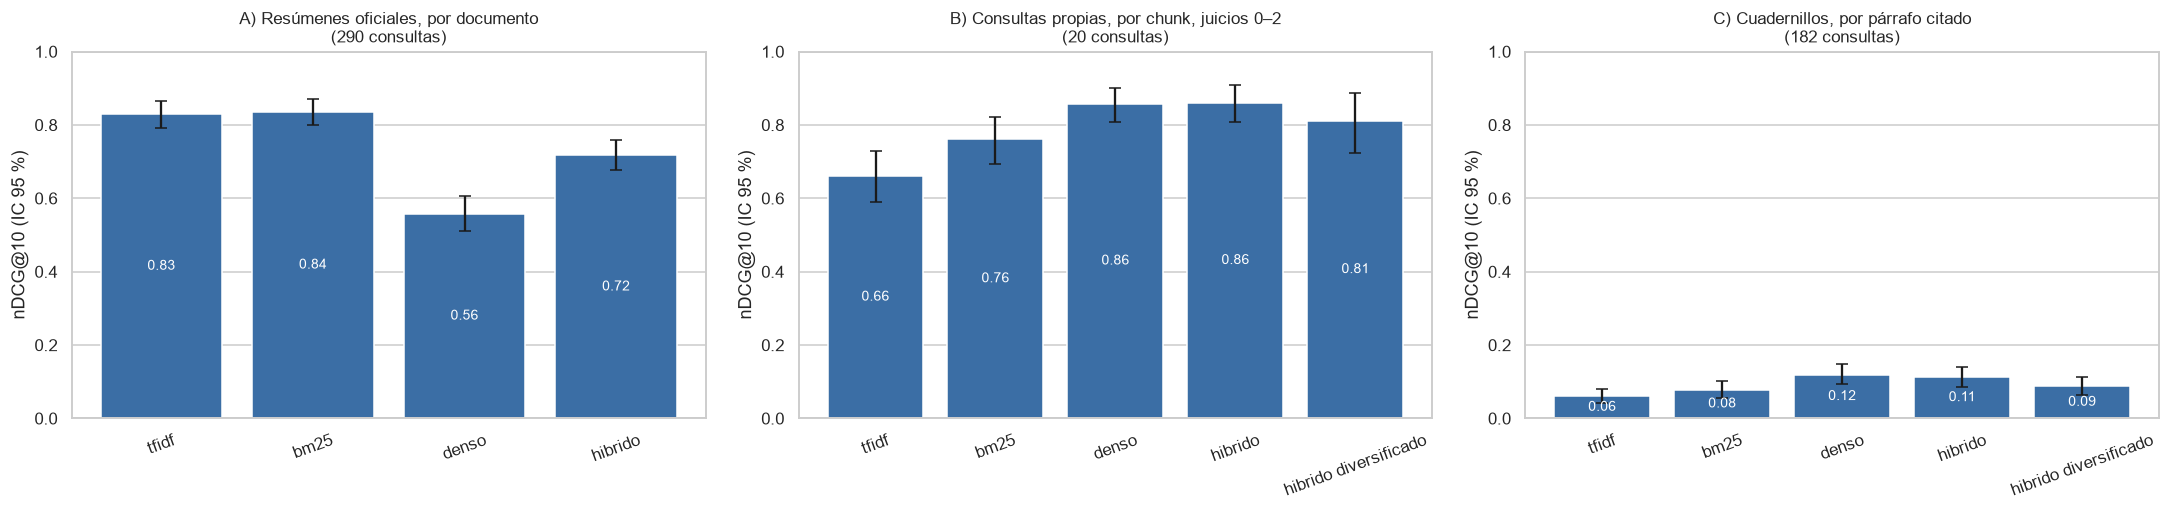

In [81]:
# ============================================================
# 4.5 RESULTADOS: CONSULTAS PROPIAS (por chunk, juicios 0–2)
# ============================================================
# P@10: fracción del top 10 con relevancia >= 1. "sin juzgar" debe ser ~0: el pool cubre los 5 sistemas.
SISTEMAS_PROP = [("tfidf", "tfidf", False), ("bm25", "bm25", False), ("denso", "denso", False),
                 ("hibrido", "hibrido", False), ("hibrido diversificado", "hibrido", True)]
filas = []
for q in consultas_prop.itertuples():
    g = ganancia_prop[q.consulta_id]
    for nombre, metodo, div in SISTEMAS_PROP:
        res = buscar(q.consulta, metodo, k=10, diversificado=div)
        ids = res["chunk_id"].tolist()
        filas.append({"metodo": nombre, "consulta_id": q.consulta_id, **metricas(ids, g),
                      "P@10": np.mean([g.get(i, 0) > 0 for i in ids]),
                      "casos distintos": res["caso_id"].nunique(),
                      "sin juzgar": np.mean([i not in g for i in ids])})
eval_prop = pd.DataFrame(filas)
COLS_PROP = ["nDCG@10", "P@10", "MRR@10"]
tabla_prop = resumir(eval_prop, ["metodo"], COLS_PROP)
display(formatear(tabla_prop, COLS_PROP).assign(
    **{"casos distintos": eval_prop.groupby("metodo", sort=False)["casos distintos"].mean().round(1).values,
       "sin juzgar": eval_prop.groupby("metodo", sort=False)["sin juzgar"].mean().round(3).values}))

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
for a, (t, titulo) in zip(ax, [(tabla_res, f"A) Resúmenes oficiales, por documento\n({len(consultas_res)} consultas)"),
                               (tabla_prop, f"B) Consultas propias, por chunk, juicios 0–2\n({len(consultas_prop)} consultas)"),
                               (tablas["C párrafo"], f"C) Cuadernillos, por párrafo citado\n({len(consultas_cuad)} consultas)")]):
    m = t["nDCG@10"].to_numpy()
    lo, hi = np.array([x[0] for x in t["nDCG@10 IC"]]), np.array([x[1] for x in t["nDCG@10 IC"]])
    barras = a.bar(t["metodo"], m, yerr=[m - lo, hi - m], capsize=4, color="#3b6ea5")
    a.bar_label(barras, labels=[f"{v:.2f}" for v in m], label_type="center", color="white", fontsize=9)
    a.set_ylim(0, 1)
    a.grid(False, axis="x")
    a.set_ylabel("nDCG@10 (IC 95 %)")
    a.set_title(titulo, fontsize=11)
    a.tick_params(axis="x", rotation=20)
guardar_fig("fig11_evaluacion_metodos")

In [82]:
# ============================================================
# 4.6 ABLACIONES (conjuntos A y C)
# ============================================================
# Cada fila cambia una sola decisión de la configuración principal: chunks de 250 palabras, cabecera
# de contexto en el embedding, 512 tokens y notas al pie fuera del índice. BM25 no usa la cabecera
# ni depende de la ventana del modelo, así que en esas dos solo se evalúan denso e híbrido.
def codificar_pasajes(textos, max_tokens=512):
    embedding_model.max_seq_length = max_tokens
    try:
        with torch.inference_mode():
            return embedding_model.encode([f"passage: {t}" for t in textos], batch_size=128, show_progress_bar=True,
                                          normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    finally:
        embedding_model.max_seq_length = 512


ablaciones = [eval_principal[eval_principal["metodo"].isin(["bm25", "denso", "hibrido"])]]

# a) Sin cabecera de contexto
ablaciones.append(evaluar_variante({**var_principal, "emb": codificar_pasajes(df_chunks["texto"])},
                                    "sin cabecera", ["denso", "hibrido"]))

# b) Ventana de 256 tokens (la configuración anterior)
ablaciones.append(evaluar_variante({**var_principal, "emb": codificar_pasajes(df_chunks["texto_con_contexto"], 256)},
                                    "256 tokens", ["denso", "hibrido"]))

# c) Con notas al pie: las notas de cada sentencia se añaden como chunks propios (ventanas de MAX_PALABRAS)
meta_doc = df_chunks.drop_duplicates("doc_id").set_index("doc_id", drop=False)
filas = []
for r in df_corpus[df_corpus["doc_id"].isin(docs_indexados)].itertuples():
    palabras = r.texto_notas.split() if isinstance(r.texto_notas, str) else []
    for i in range(0, len(palabras), MAX_PALABRAS):
        texto = " ".join(palabras[i:i + MAX_PALABRAS])
        filas.append({"doc_id": r.doc_id, "texto": texto,
                      "texto_con_contexto": f"{cabecera(meta_doc.loc[r.doc_id], 'Notas al pie', 'cuerpo', None, None)}\n\n{texto}"})
chunks_notas = pd.DataFrame(filas)
chunks_notas["texto_normalizado"] = [" ".join(l) for l in normalizar_lote(chunks_notas["texto"], "Lematización de notas")]
cols = ["doc_id", "parte", "parr_ini", "parr_fin", "texto", "texto_con_contexto", "texto_normalizado"]
chunks_con_notas = pd.concat([df_chunks[cols], chunks_notas.reindex(columns=cols)], ignore_index=True)
print("Chunks de notas al pie:", len(chunks_notas))
ablaciones.append(evaluar_variante(
    {"chunks": chunks_con_notas, "emb": np.vstack([embeddings, codificar_pasajes(chunks_notas["texto_con_contexto"])]),
     "bm25": BM25Okapi(chunks_con_notas["texto_normalizado"].str.split().tolist(), k1=1.5, b=0.75)},
    "con notas al pie", ["bm25", "denso", "hibrido"]))

# d) Chunks de 150 palabras
max_original, MAX_PALABRAS = MAX_PALABRAS, 150
try:
    chunks_150 = construir_chunks(df_rag)
finally:
    MAX_PALABRAS = max_original
largos = chunks_150["tipo_chunk"].eq("parrafo_largo")
chunks_150.loc[largos, "texto_normalizado"] = [" ".join(l) for l in normalizar_lote(chunks_150.loc[largos, "texto"],
                                                                                    "Lematización de chunks de 150")]
print("Chunks de 150 palabras:", len(chunks_150))
ablaciones.append(evaluar_variante(
    {"chunks": chunks_150, "emb": codificar_pasajes(chunks_150["texto_con_contexto"]),
     "bm25": BM25Okapi(chunks_150["texto_normalizado"].str.split().tolist(), k1=1.5, b=0.75)},
    "chunks de 150 palabras", ["bm25", "denso", "hibrido"]))

Chunks de notas al pie: 26665


Chunks de 150 palabras: 144833


In [83]:
# ============================================================
# TABLA DE ABLACIONES
# ============================================================
# Δ nDCG@10: diferencia pareada (misma consulta) contra la variante principal, con IC 95 % bootstrap.
# Si el intervalo contiene el 0, la diferencia no es concluyente.
eval_abl = pd.concat(ablaciones, ignore_index=True)


def delta_pareada(conjunto, variante, metodo, col="nDCG@10"):
    e = eval_abl[eval_abl["conjunto"].eq(conjunto) & eval_abl["metodo"].eq(metodo)]
    base = e[e["variante"].eq("principal")].set_index("consulta_id")[col]
    otra = e[e["variante"].eq(variante)].set_index("consulta_id")[col]
    d = (otra - base.reindex(otra.index)).to_numpy()
    lo, hi = ic_bootstrap(d)
    return f"{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]"


COLS_ABL = ["R@10", "MRR@10", "nDCG@10"]
tabla_abl = formatear(resumir(eval_abl, ["conjunto", "variante", "metodo"], COLS_ABL), COLS_ABL)
tabla_abl["Δ nDCG@10 vs principal"] = [("—" if v == "principal" else delta_pareada(c, v, m))
                                       for c, v, m in zip(tabla_abl["conjunto"], tabla_abl["variante"], tabla_abl["metodo"])]
display(tabla_abl[tabla_abl["variante"].ne("principal")]
        .pivot(index=["variante", "metodo"], columns="conjunto", values="Δ nDCG@10 vs principal")
        .reindex(columns=["A", "C párrafo", "C documento"]))

# Tablas para el artículo
TABLAS_EVAL = PROC_DIR / "evaluacion"
TABLAS_EVAL.mkdir(exist_ok=True)
formatear(tabla_res, COLS_DOC).to_csv(TABLAS_EVAL / "tabla_metodos_resumenes.csv", index=False, encoding="utf-8-sig")
formatear(tabla_prop, COLS_PROP).to_csv(TABLAS_EVAL / "tabla_metodos_consultas_propias.csv", index=False, encoding="utf-8-sig")
pd.concat([formatear(tablas[c], COLS_DOC).assign(conjunto=c) for c in ["C párrafo", "C documento"]]) \
  .to_csv(TABLAS_EVAL / "tabla_metodos_cuadernillos.csv", index=False, encoding="utf-8-sig")
tabla_abl.to_csv(TABLAS_EVAL / "tabla_ablaciones.csv", index=False, encoding="utf-8-sig")
pd.concat([eval_abl, eval_principal[~eval_principal["metodo"].isin(["bm25", "denso", "hibrido"])],
           eval_prop.assign(conjunto="B", variante="principal")]) \
  .to_csv(TABLAS_EVAL / "evaluacion_por_consulta.csv", index=False, encoding="utf-8-sig")
consultas_res.to_csv(TABLAS_EVAL / "consultas_resumenes.csv", index=False, encoding="utf-8-sig")
print("Tablas guardadas en:", TABLAS_EVAL)

conjunto                                              A                C párrafo              C documento
variante               metodo                                                                            
256 tokens             denso    -0.035 [-0.062, -0.007]  -0.007 [-0.020, +0.006]  +0.002 [-0.022, +0.024]
                       hibrido  -0.020 [-0.043, +0.002]  +0.014 [+0.005, +0.024]  +0.021 [+0.003, +0.040]
chunks de 150 palabras bm25     -0.001 [-0.025, +0.021]  -0.026 [-0.037, -0.014]  +0.006 [-0.017, +0.030]
                       denso    +0.010 [-0.022, +0.039]  -0.024 [-0.038, -0.009]  +0.008 [-0.016, +0.034]
                       hibrido  +0.023 [-0.001, +0.050]  -0.017 [-0.032, -0.004]  +0.007 [-0.017, +0.031]
con notas al pie       bm25     +0.001 [-0.006, +0.010]  -0.006 [-0.009, -0.003]  +0.018 [+0.002, +0.037]
                       denso    +0.005 [-0.004, +0.015]  -0.008 [-0.013, -0.005]  -0.020 [-0.031, -0.011]
                       hibrido  -0.000 [-0.007, +0.007]  -0.006 [-0.010, -0.002]  +0.000 [-0.012, +0.014]
sin cabecera           denso    -0.009 [-0.042, +0.026]  -0.027 [-0.044, -0.011]  -0.054 [-0.083, -0.024]
                       hibrido  +0.030 [+0.003, +0.058]  -0.004 [-0.013, +0.006]  -0.007 [-0.027, +0.011]

Tablas guardadas en: C:\Users\USER\Desktop\proyectoPLN\procesado\evaluacion
